# Adversarial Robustness and Reliability of IDC Histopathology Patch Classifiers

**Retrospective methodological study | reproducible research code and publication-preparation package**

This notebook studies **patch-level** invasive ductal carcinoma (IDC) labels—not patient diagnoses or clinical deployment. It compares custom CNN, ImageNet-pretrained ResNet-18, and MobileNetV3-Small using patient-grouped internal evaluation, adversarial perturbations, and reliability analyses.

**Evidence status:** Code and protocol preparation are not completed experiments. The manuscript generator **withholds numerical findings** until the full-study evidence gates pass. The earlier smoke-test results are exploratory engineering checks, not scientific results.

**Execution:** Set `RUN_PROFILE = "all_research"` and run sequentially with `RUN_STAGE = "baseline_only"`, then `"split_stability"`, then `"analyses"` on a CUDA-enabled computer. This order generates the complete audit without rerunning the expensive attack suite. Read `STUDY_PROTOCOL.md` before full execution.

> **Methods integrity revision (2026-11-02):** All previously saved numerical outputs describe an older code revision. This notebook clears cached execution outputs, preserves strict checkpoint matching, expands filename-group split stability to all three primary models, expands binary-compatible custom AutoAttack to ≥256 matched test patches, adds threshold-aware independent worst-of attacks and source-lineage gating, and corrects repeated training seed reporting. **No revised GPU results are claimed until re-execution.** This remains retrospective patch-level methodology and is **not submission-approved** automatically.


# Full Academic Research — All Stages In One Run

**Previously completed:** Stage 1 Full baseline CNN, pretrained ResNet-18 and MobileNetV3 results are present in the separately supplied `01_STAGE1_BASELINE_EXECUTED.ipynb` and on the user's local PC. This notebook attempts to reuse their saved `.pt` files.

**When run on the same Windows desktop with its IDC dataset and saved checkpoints**, this version executes the advanced analyses, independently retrains alternative group-split models, and then generates the Stage-1 technical-evidence audit. The Split Stability cell is enabled in `RUN_STAGE="all"`; in the original notebook it was only enabled when `RUN_STAGE="split_stability"`.

**Do not mistake a configured workflow for completed experiments.** The notebook has no prefilled Stage-2 or Stage-3 results. Execute it locally and inspect `ACADEMIC_STAGE1_AUDIT.json` and `STAGE1_SUBMISSION_READINESS.md` before making submission claims. The attack sweep covers the full test set and can require considerable GPU computation. A single-run restart may recompute earlier analyses; separate Stage-2/Stage-3 notebooks are the safer recovery path.

## Study design and evidence boundaries

- **Primary outcome:** change in patch-level IDC-positive sensitivity after white-box PGD (`ε = 8/255`, L∞) relative to clean input on matched internal-test patches, using a **validation-F1 threshold frozen before testing**. Report patient-grouped 95% bootstrap intervals.
- **Secondary outcomes:** clean sensitivity/specificity, FNR, AUROC/AUPRC, calibration, perturbation-strength sensitivity, adversarial fine-tuning, architecture differences, selective abstention, corruption robustness, computation, and failure cases.
- **Study groups:** inferred from source filename/folder identifiers. Their identity as distinct clinical patients must be verified against provenance. The source describes 162 whole-slide specimens, which should **not** be equated with the number of observed directory groups.
- **Data separation:** the full research profile uses a newly declared patient-grouped split seed (`20261101`) rather than the previously explored smoke-test seed (`42`). This is **not external validation** or a prospective preregistration.
- **Publication rule:** no fabricated performance measurements, no claims of clinical safety, and no unrestricted publication-ready flag based on file existence alone.

See `STUDY_PROTOCOL.md`, `REPORTING_CHECKLIST.md`, and `MANUSCRIPT_DRAFT.md` in the project package. These documents are manuscript preparation materials, **not completed study findings**.

In [1]:

import sys
import torch
import torchvision

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    x = torch.randn(100, 100, device="cuda")
    y = x @ x
    print("GPU calculation:", y.device)


Python: c:\Users\htpar\AppData\Local\Programs\Python\Python312\python.exe
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA runtime: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 4070
GPU calculation: cuda:0


## 0. Configuration and reproducible run stages

The notebook reads images already stored at `I:\Potforlio\IDC Adversarial Robustness`; it does not download the dataset. Default `all_smoke` runs on a small subset. For GPU Full research, set `RUN_PROFILE="all_research"` and proceed through `RUN_STAGE="baseline_only"`, then `"analyses"`, then `"split_stability"`. Restart the kernel between stages. Primary model order is CNN → pretrained ResNet-18 → pretrained MobileNetV3-Small. Each stage has an independent completion record; verified results from previous stages are not deleted.

In [2]:
# Dataset images are read from a local folder; this notebook never downloads the IDC dataset.
from pathlib import Path
import os, re, json, random, hashlib, time, filecmp, sys
from collections import Counter
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display
import torch
import torchvision
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models as tvmodels
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, roc_curve,
    precision_recall_curve, brier_score_loss)

DATA_ROOT = Path(r"I:\Potforlio\IDC Adversarial Robustness")
RUN_STARTED_AT = time.time()
RUN_PROFILE = "all_research"
RUN_STAGE = "all"
if RUN_STAGE not in ("all", "baseline_only", "analyses", "split_stability"):
    raise ValueError("RUN_STAGE must be all, baseline_only, analyses, or split_stability")
RUN_SELECTIVE_CLASSWISE = True
RUN_SHIFT_DOSE_RESPONSE = True
RUN_HIGH_CONFIDENCE_FN = True
GROUPED_SPLIT_SEEDS = [52, 62]
GROUPED_SPLIT_MODELS = ["cnn", "resnet18_pretrained", "mobilenetv3_small_pretrained"]
HIGH_CONFIDENCE_NEGATIVE = 0.90
OUTPUT_BASE = Path.home() / "Downloads" / "idc_robustness_final_outputs"
FULL_IMAGE_SIZE = 128
FULL_ATTACK_SAMPLE_LIMIT = None
ALL_SMOKE_TRAIN_N = 96
ALL_SMOKE_VAL_N = 48
ALL_SMOKE_TEST_N = 48
ALL_SMOKE_ATTACK_N = 16
ALL_SMOKE_OPTIONAL_N = 8
AUTOATTACK_FULL_SAMPLE_LIMIT = 256  # Expanded binary-compatible APGD-CE + Square subset; not official standard ensemble.
AUTOATTACK_INSTALL_IF_MISSING = True  # Install into the active Jupyter kernel when analyses run.
AUTOATTACK_REQUIRED_FOR_FULL = True  # Fail before costly full analysis when the package is unavailable.
DEEPFOOL_FULL_SAMPLE_LIMIT = 32

RUN_EXTERNAL_VALIDATION = False
EXTERNAL_DATA_ROOT = None
EXTERNAL_PROVENANCE_CONFIRMED = False
EXTRA_CHECKPOINT_FOLDERS = []
EXTRA_CHECKPOINT_FILES = []
AUTO_DISCOVER_CHECKPOINTS = False
CHECKPOINT_SCAN_MAX_DIRS = 12000
CHECKPOINT_SCAN_EXTRA_ROOTS = []

FULL_BASELINE_MODELS = ["cnn", "resnet18_pretrained", "mobilenetv3_small_pretrained"]
RUN_EFFICIENTNET = False
RUN_DENSENET = False
RUN_CONVNEXT = False
RUN_RESNET_SCRATCH = False

RUN_ALL_REQUESTED = RUN_PROFILE in ("all_smoke", "all_research")
RUN_DEFENSE = RUN_ALL_REQUESTED
RUN_EXTRA_ANALYSES = RUN_ALL_REQUESTED
RUN_TARGETED_ATTACK = RUN_ALL_REQUESTED
RUN_SPATIAL_MAPPING = RUN_ALL_REQUESTED
RUN_STAIN_SENSITIVITY = RUN_ALL_REQUESTED
RUN_DEEPFOOL = RUN_ALL_REQUESTED
RUN_AUTOATTACK = RUN_ALL_REQUESTED
RUN_CALIBRATION = True
RUN_ATTACK_CALIBRATION = True
RUN_PAIRED_BOOTSTRAP = True
RUN_SAVE_ATTACK_PREDICTIONS = True
RUN_TRANSFERABILITY = True
TRANSFER_ATTACK_METHODS = ("FGSM", "PGD")
TRANSFER_ATTACK_N = 256
TRANSFER_PGD_STEPS = 10
RUN_FN_FLIP_ANALYSIS = True
RUN_PGD_CONVERGENCE = RUN_PROFILE in ("all_smoke", "all_research", "full_research")
RUN_COST_SCENARIOS = True
COST_RATIO_GRID = (1, 3, 5, 10)
CACHE_VERIFIED_DUPLICATES = True
FORCE_RECHECK_DUPLICATE_BYTES = RUN_PROFILE == "all_research"

ALLOW_FULL_CPU_TRAINING = False
CPU_TORCH_THREADS = 4
SHOW_EPOCH_PROGRESS = True
REPEAT_MODEL_SEEDS = [43, 44] if RUN_PROFILE == "all_research" else []
REPEAT_CNN_TRAIN_SEEDS = []
RUN_INPUT_RESOLUTION_INFERENCE = RUN_PROFILE in ("all_smoke", "all_research")
RUN_EFFICIENCY_PARETO = True
EVALUATION_REVISION = "reviewed_unified_selective_shift_v1"
# Publication validation settings. Excluded from legacy checkpoint and experiment IDs.
SUBMISSION_VALIDATION_N = 384
SUBMISSION_VALIDATION_PGD_STEPS = 50
SUBMISSION_VALIDATION_RESTARTS = 3
RUN_SUBMISSION_VALIDATION = RUN_PROFILE == "all_research"
VERIFIED_GROUP_MAPPING_CSV = None  # Optional externally corroborated CSV; never inferred from folder names.
SUBMISSION_REVIEW_REVISION = "2026-11-02_methods_integrity_v2"
RUN_DEEPFOOL_CROSSCHECK = True
MIN_RESEARCH_IDC_POSITIVE_N = 20
MIN_RESEARCH_PATIENT_N = 20

SPLIT_STRATIFICATION_MODE = "legacy_has_positive"
SPLIT_SEED = 20261101 if RUN_PROFILE == "all_research" else 42
TRAIN_SEED = 42
REUSE_CHECKPOINTS = True
TARGET_RECALL = 0.90
MIN_CLEAN_CORRECT_POSITIVE_N = 5
MIN_PATIENT_POSITIVE_PATCHES = 5
EXPERIMENT_REVISION = "extended_v2_20261022"

PROFILES = ("recover_cnn", "quick_train", "full_research", "all_smoke", "all_research")
if RUN_PROFILE not in PROFILES:
    raise ValueError(f"RUN_PROFILE must be one of {PROFILES}")
MODE = "full" if RUN_PROFILE in ("full_research", "all_research") else "quick"
SHIFT_EVAL_N = 16 if RUN_PROFILE == "all_smoke" else (64 if MODE == "quick" else 256)
TRAIN_POLICY = "reuse_only" if RUN_PROFILE == "recover_cnn" else "train_missing"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if RUN_PROFILE in ("all_research", "full_research") and DEVICE.type == "cpu" and not ALLOW_FULL_CPU_TRAINING:
    raise RuntimeError("all_research requires a CUDA GPU by default. Use all_smoke on CPU or explicitly set ALLOW_FULL_CPU_TRAINING=True.")
if DEVICE.type == "cpu":
    torch.set_num_threads(max(1, min(int(CPU_TORCH_THREADS), os.cpu_count() or 1)))
IMAGE_SIZE = 64 if MODE == "quick" else int(FULL_IMAGE_SIZE)
BATCH_SIZE = 16 if DEVICE.type == "cpu" else 32
ATTACK_BATCH_SIZE = 8 if DEVICE.type == "cpu" else 16
NUM_WORKERS = 0
ATTACK_N = (ALL_SMOKE_ATTACK_N if RUN_PROFILE=="all_smoke" else (32 if MODE=="quick" else FULL_ATTACK_SAMPLE_LIMIT))
EPS_GRID = [0, 2/255, 4/255, 8/255]
DEFENSE_EPS = 8/255
PGD_CONVERGENCE_EPS = DEFENSE_EPS
PGD_CONVERGENCE_STEPS = (2, 3, 5) if MODE == "quick" else (10, 20, 50)
PGD_CONVERGENCE_RESTARTS = 1 if MODE == "quick" else 2
PGD_CONVERGENCE_N = ALL_SMOKE_OPTIONAL_N if RUN_PROFILE == "all_smoke" else (32 if MODE == "quick" else 128)
PGD_STEPS = 3 if RUN_PROFILE=="all_smoke" else (5 if MODE=="quick" else 20)
PGD_RESTARTS = 1 if MODE == "quick" else 2
PATIENCE = 2 if MODE == "quick" else 4
BOOTSTRAP_N = 100 if MODE == "quick" else 500
PAIRED_BOOTSTRAP_N = 200 if MODE == "quick" else 1000
STAIN_EVAL_N = 128 if MODE == "quick" else 512
TARGETED_N = 64 if MODE == "quick" else 512
DEFENSE_EPOCHS = 1 if MODE == "quick" else 5
if RUN_PROFILE == "all_smoke":
    TRANSFER_ATTACK_N = ALL_SMOKE_ATTACK_N
    TRANSFER_PGD_STEPS = 2
    TARGETED_N = ALL_SMOKE_OPTIONAL_N
    STAIN_EVAL_N = ALL_SMOKE_OPTIONAL_N
    PAIRED_BOOTSTRAP_N = 40
    BOOTSTRAP_N = 40

MAX_EPOCHS = ({"cnn": 2, "resnet18_scratch": 2, "resnet18_pretrained": 2,
    "mobilenetv3_small_pretrained": 2, "efficientnet_b0_pretrained": 2,
    "densenet121_pretrained": 2, "convnext_tiny_pretrained": 2} if MODE == "quick" else
    {"cnn": 15, "resnet18_scratch": 15, "resnet18_pretrained": 12,
     "mobilenetv3_small_pretrained": 12, "efficientnet_b0_pretrained": 12,
     "densenet121_pretrained": 12, "convnext_tiny_pretrained": 12})

if RUN_PROFILE in ("full_research", "all_research"):
    BASELINE_MODELS = list(dict.fromkeys(FULL_BASELINE_MODELS))
    if RUN_RESNET_SCRATCH and "resnet18_scratch" not in BASELINE_MODELS:
        BASELINE_MODELS.append("resnet18_scratch")
    for enabled, name in [(RUN_EFFICIENTNET,"efficientnet_b0_pretrained"),
                          (RUN_DENSENET,"densenet121_pretrained"),
                          (RUN_CONVNEXT,"convnext_tiny_pretrained")]:
        if enabled and name not in BASELINE_MODELS: BASELINE_MODELS.append(name)
elif RUN_PROFILE == "all_smoke":
    BASELINE_MODELS = ["cnn", "resnet18_scratch"]
else:
    BASELINE_MODELS = ["cnn"]
if RUN_PROFILE == "all_smoke":
    MAX_EPOCHS["cnn"] = 1
    MAX_EPOCHS["resnet18_scratch"] = 1
if RUN_ALL_REQUESTED:
    EXPERIMENT_REVISION = "v6_classwise_robustness_20261023"

if RUN_PROFILE == "recover_cnn" and RUN_DEFENSE:
    raise ValueError("recover_cnn does not train defenses. Set RUN_DEFENSE=False.")
if RUN_ALL_REQUESTED and len(BASELINE_MODELS)<2:
    raise ValueError("The all-analyses run requires >=2 models for Cross-Model Transferability.")
if RUN_DEFENSE and "cnn" not in BASELINE_MODELS:
    raise ValueError("RUN_DEFENSE requires CNN in BASELINE_MODELS")
if TRAIN_POLICY == "reuse_only" and (REPEAT_CNN_TRAIN_SEEDS or REPEAT_MODEL_SEEDS):
    raise ValueError("Repeated seed training is not available in reuse_only mode")
# Validate AutoAttack in this exact Jupyter kernel; terminal Python may differ.
import importlib, importlib.util, subprocess
AUTOATTACK_PIP_SOURCE = "git+https://github.com/fra31/auto-attack"
AUTOATTACK_PREFLIGHT = {
    "interpreter": sys.executable,
    "requested": bool(RUN_AUTOATTACK and RUN_STAGE in ("all", "analyses")),
    "install_attempted": False,
    "install_returncode": None,
    "install_log_tail": "",
    "module_location": "",
}
def detect_autoattack():
    try:
        importlib.invalidate_caches()
        package = importlib.import_module("autoattack")
        if not callable(getattr(package, "AutoAttack", None)):
            raise ImportError("Imported 'autoattack' does not expose the AutoAttack class")
        location = str(getattr(package, "__file__", "unknown"))
        return {"available": True, "error": "", "module_location": location}
    except Exception as exc:
        return {"available": False, "error": f"{type(exc).__name__}: {exc}", "module_location": ""}

OPTIONAL_ATTACK_IMPORTS = {"autoattack": detect_autoattack()}
if (AUTOATTACK_PREFLIGHT["requested"] and AUTOATTACK_INSTALL_IF_MISSING
        and not OPTIONAL_ATTACK_IMPORTS["autoattack"]["available"]):
    # Use sys.executable to install into the interpreter running this notebook.
    AUTOATTACK_PREFLIGHT["install_attempted"] = True
    print("[AutoAttack] Installing the official package into:", sys.executable)
    try:
        install_proc = subprocess.run(
            [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", AUTOATTACK_PIP_SOURCE],
            capture_output=True, text=True, encoding="utf-8", errors="replace",
            timeout=300, check=False,
        )
        AUTOATTACK_PREFLIGHT["install_returncode"] = int(install_proc.returncode)
        AUTOATTACK_PREFLIGHT["install_log_tail"] = (
            (install_proc.stdout or "") + "\n" + (install_proc.stderr or "")
        )[-3500:]
        importlib.invalidate_caches()
        OPTIONAL_ATTACK_IMPORTS["autoattack"] = detect_autoattack()
    except Exception as exc:
        AUTOATTACK_PREFLIGHT["install_log_tail"] = f"{type(exc).__name__}: {exc}"
AUTOATTACK_PREFLIGHT["module_location"] = OPTIONAL_ATTACK_IMPORTS["autoattack"]["module_location"]
AUTOATTACK_PREFLIGHT["available"] = OPTIONAL_ATTACK_IMPORTS["autoattack"]["available"]
AUTOATTACK_PREFLIGHT["import_error"] = OPTIONAL_ATTACK_IMPORTS["autoattack"]["error"]
print("Jupyter kernel Python:", sys.executable)
print("Torch:", torch.__version__, "| Torchvision:", torchvision.__version__)
print("AutoAttack preflight:", {k: v for k, v in AUTOATTACK_PREFLIGHT.items() if k != "install_log_tail"})
if AUTOATTACK_PREFLIGHT["requested"] and not AUTOATTACK_PREFLIGHT["available"]:
    print("[AutoAttack] Dependency could not be loaded in this kernel.")
    print('Run: %pip install git+https://github.com/fra31/auto-attack')
    print("Restart the Jupyter kernel, then run this notebook again.")
    if AUTOATTACK_PREFLIGHT["install_log_tail"]:
        print("Installation diagnostic (last lines):", AUTOATTACK_PREFLIGHT["install_log_tail"][-1000:])
    if RUN_PROFILE == "all_research" and AUTOATTACK_REQUIRED_FOR_FULL:
        raise RuntimeError(
            "Full research requires an importable AutoAttack package before expensive analyses. "
            "See the kernel interpreter and installation diagnostic above. "
            "Run baseline_only separately if you want to train models first."
        )

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f"Data root not found: {DATA_ROOT}; verify your I: drive")
PROFILE_ROOT = Path(OUTPUT_BASE).expanduser().resolve() / (RUN_PROFILE if RUN_ALL_REQUESTED else ("quick_train" if RUN_PROFILE == "quick_train" else MODE))
EXPERIMENT_SETTINGS = {
    "data_root": str(DATA_ROOT.resolve()), "profile": RUN_PROFILE,
    "image_size": IMAGE_SIZE, "models": BASELINE_MODELS, "seed": TRAIN_SEED,
    "split_seed": SPLIT_SEED, "split_stratification_mode": SPLIT_STRATIFICATION_MODE, "epochs": {m: MAX_EPOCHS[m] for m in BASELINE_MODELS},
    "batch_size": BATCH_SIZE, "attack_n": ATTACK_N, "eps_grid": EPS_GRID,
    "pgd_steps": PGD_STEPS, "pgd_restarts": PGD_RESTARTS,
    "defense": RUN_DEFENSE, "extras": RUN_EXTRA_ANALYSES,
    "transferability": RUN_TRANSFERABILITY, "transfer_methods": TRANSFER_ATTACK_METHODS,
    "transfer_n": TRANSFER_ATTACK_N, "transfer_pgd_steps": TRANSFER_PGD_STEPS,
    "cost_scenarios": RUN_COST_SCENARIOS, "cost_grid": COST_RATIO_GRID,
    "paired_bootstrap": RUN_PAIRED_BOOTSTRAP, "calibration": RUN_CALIBRATION,
    "attack_calibration": RUN_ATTACK_CALIBRATION,
    "fn_flips": RUN_FN_FLIP_ANALYSIS,
    "pgd_convergence": RUN_PGD_CONVERGENCE,
    "pgd_convergence_steps": PGD_CONVERGENCE_STEPS,
    "pgd_convergence_restarts": PGD_CONVERGENCE_RESTARTS,
    "pgd_convergence_n": PGD_CONVERGENCE_N,
    "target_recall": TARGET_RECALL,
    "targeted_n": TARGETED_N, "stain_eval_n": STAIN_EVAL_N,
    "defense_epochs": DEFENSE_EPOCHS, "defense_eps": DEFENSE_EPS,
    "repeat_train_seeds": REPEAT_MODEL_SEEDS, "input_resolution_inference": RUN_INPUT_RESOLUTION_INFERENCE,
    "targeted": RUN_TARGETED_ATTACK, "spatial": RUN_SPATIAL_MAPPING,
    "stain": RUN_STAIN_SENSITIVITY, "deepfool": RUN_DEEPFOOL,
    "autoattack": RUN_AUTOATTACK, "external": RUN_EXTERNAL_VALIDATION,
    "revision": EXPERIMENT_REVISION, "evaluation_revision": EVALUATION_REVISION,
    "classwise_selective":RUN_SELECTIVE_CLASSWISE, "shift_dose_response":RUN_SHIFT_DOSE_RESPONSE,
    "high_confidence_fn":RUN_HIGH_CONFIDENCE_FN, "high_confidence_negative":HIGH_CONFIDENCE_NEGATIVE,
    "efficiency_pareto":RUN_EFFICIENCY_PARETO, "shift_eval_n":SHIFT_EVAL_N,
    "full_all_suite": bool(RUN_ALL_REQUESTED),
}
EXPERIMENT_ID = hashlib.sha256(json.dumps(EXPERIMENT_SETTINGS,sort_keys=True,default=str).encode()).hexdigest()[:12]
OUTPUT_ROOT = PROFILE_ROOT / "experiments" / EXPERIMENT_ID
RESULTS_DIR = OUTPUT_ROOT / "results"
CHECKPOINT_DIR = PROFILE_ROOT / "checkpoints"
MANIFEST_DIR = OUTPUT_ROOT / "manifests"
AUDIT_CACHE_DIR = Path(OUTPUT_BASE).expanduser().resolve() / "_verified_dataset_audit"
for folder in (RESULTS_DIR, CHECKPOINT_DIR, MANIFEST_DIR, AUDIT_CACHE_DIR):
    folder.mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "AUTOATTACK_PREFLIGHT.json").write_text(json.dumps(AUTOATTACK_PREFLIGHT, indent=2, default=str), encoding="utf-8")
# Never delete the last verified run when a new stage starts.
# Stage-specific activity markers distinguish running/failed work from completed results.
(OUTPUT_ROOT / "experiment_settings.json").write_text(json.dumps(EXPERIMENT_SETTINGS,indent=2,default=str),encoding="utf-8")
print("Experiment:", EXPERIMENT_ID, "| Results:", RESULTS_DIR, flush=True)

CHECKPOINT_SEARCH_DIRS = []
for item in [CHECKPOINT_DIR,
             Path.cwd() / "idc_robustness_final_outputs" / MODE / "checkpoints",
             Path.home() / "Downloads" / "idc_robustness_final_outputs" / MODE / "checkpoints",
             Path.home() / "Documents" / "idc_robustness_final_outputs" / MODE / "checkpoints",
             *map(Path, EXTRA_CHECKPOINT_FOLDERS)]:
    path = Path(item).expanduser().resolve()
    if path not in CHECKPOINT_SEARCH_DIRS:
        CHECKPOINT_SEARCH_DIRS.append(path)

EXPLICIT_CHECKPOINT_FILES = [Path(f).expanduser().resolve() for f in EXTRA_CHECKPOINT_FILES]

SKIP_SCAN_DIRS = {"AppData", ".git", ".venv", "venv", "env", "node_modules", "__pycache__",
                  ".mypy_cache", ".cache", ".tox", "$RECYCLE.BIN", "System Volume Information"}

def discover_checkpoint_files(roots, limit=12000):
    found, seen, scanned = [], set(), 0
    dataset_dir = DATA_ROOT.resolve()
    for root in roots:
        root = Path(root).expanduser()
        if not root.is_dir():
            continue
        for current, directories, filenames in os.walk(root, topdown=True, onerror=lambda error: None):
            scanned += 1
            if scanned > limit:
                print(f"Checkpoint discovery reached folder limit ({limit}); use EXTRA_CHECKPOINT_FILES to specify other locations.")
                return found, scanned
            current_path = Path(current).resolve()
            if current_path == dataset_dir or dataset_dir in current_path.parents:
                directories[:] = []
                continue
            directories[:] = [d for d in directories if d not in SKIP_SCAN_DIRS
                              and (current_path / d).resolve() != dataset_dir]
            for filename in filenames:
                if filename.lower().endswith(".pt") and filename.lower().startswith("baseline_"):
                    candidate = (current_path / filename).resolve()
                    if candidate not in seen:
                        seen.add(candidate)
                        found.append(candidate)
    return sorted(found), scanned

working_dir = Path.cwd().resolve()
common_roots = [Path.home() / "Downloads", Path.home() / "Documents", Path.home() / "Desktop",
                Path.home() / "OneDrive"]
if len(working_dir.parts) >= 3 and working_dir != DATA_ROOT.resolve() and DATA_ROOT.resolve() not in working_dir.parents:
    common_roots.append(working_dir)
common_roots.extend(Path(path) for path in CHECKPOINT_SCAN_EXTRA_ROOTS)
AUTO_FOUND_CHECKPOINT_FILES, SCANNED_DIR_COUNT = (discover_checkpoint_files(common_roots, CHECKPOINT_SCAN_MAX_DIRS)
    if AUTO_DISCOVER_CHECKPOINTS else ([], 0))
CANDIDATE_CHECKPOINT_FILES = []
for candidate in EXPLICIT_CHECKPOINT_FILES + AUTO_FOUND_CHECKPOINT_FILES:
    if candidate not in CANDIDATE_CHECKPOINT_FILES:
        CANDIDATE_CHECKPOINT_FILES.append(candidate)

for folder in CHECKPOINT_SEARCH_DIRS:
    if folder.is_dir():
        for candidate in sorted(folder.glob("baseline_*.pt")):
            resolved = candidate.resolve()
            if resolved not in CANDIDATE_CHECKPOINT_FILES:
                CANDIDATE_CHECKPOINT_FILES.append(resolved)
for candidate in CANDIDATE_CHECKPOINT_FILES:
    if candidate.parent not in CHECKPOINT_SEARCH_DIRS:
        CHECKPOINT_SEARCH_DIRS.append(candidate.parent)

print("Profile:", RUN_PROFILE, "| Device:", DEVICE, "| Model(s):", BASELINE_MODELS)
if RUN_PROFILE == "all_research":
    primary_order = ("cnn", "resnet18_pretrained", "mobilenetv3_small_pretrained")
    if tuple(BASELINE_MODELS[:3]) != primary_order:
        raise ValueError("Full research requires baseline model order: " + str(primary_order))
RUN_DESCRIPTIONS = {
    "recover_cnn": "CHECKPOINT RECOVERY ONLY (NO TRAINING)",
    "quick_train": "QUICK CNN TRAINING (NOT RESEARCH EVIDENCE)",
    "full_research": "FULL BASELINE RESEARCH (SELECTED ANALYSES)",
    "all_smoke": "ALL ANALYSES SMOKE TEST (NOT RESEARCH EVIDENCE)",
    "all_research": "FULL RESEARCH WITH ALL ANALYSES",
}
print("RUN INTENT:", RUN_DESCRIPTIONS[RUN_PROFILE])
if RUN_PROFILE == "quick_train":
    print("[RUN ALL] QUICK TRAIN: CNN training/evaluation + FGSM/PGD; <=512 train, 128 val, 128 test")
    print("The CNN trains only if no exactly compatible saved checkpoint is available.")
    print("These metrics are exploratory and must not be reported as full-dataset research.")
print("Training policy:", TRAIN_POLICY, "| Image size:", IMAGE_SIZE)
print("Results:", RESULTS_DIR)
print("Attack sample cap:", ATTACK_N, "(None means all test patches)")
print("Full input size:", FULL_IMAGE_SIZE, "| Optional external validation:", RUN_EXTERNAL_VALIDATION)
print("Checkpoint folders searched:")
for folder in CHECKPOINT_SEARCH_DIRS: print(" -", folder, "[exists]" if folder.exists() else "[missing]")
print(f"Auto-scanned directories: {SCANNED_DIR_COUNT} | Available baseline .pt candidates: {len(CANDIDATE_CHECKPOINT_FILES)}")
for candidate in CANDIDATE_CHECKPOINT_FILES[:12]: print(" *", candidate)

RECOVERY_CANDIDATES = [p for p in CANDIDATE_CHECKPOINT_FILES
                       if p.is_file() and p.name.startswith("baseline_cnn_")]
ANALYSIS_ENABLED = (TRAIN_POLICY != "reuse_only") or bool(RECOVERY_CANDIDATES)
RECOVERY_REASON = ""
if not ANALYSIS_ENABLED:
    RECOVERY_REASON = (
        "No CNN model weights (.pt) were found under the configured search paths. "
        "Existing CSV files cannot regenerate model weights. "
        "In recover_cnn mode, model training and dependent analyses are skipped. "
        "If a model exists elsewhere, add its real path to EXTRA_CHECKPOINT_FILES and rerun. "
        "To intentionally train a new smaller model, select RUN_PROFILE='quick_train'."
    )
    print("\n" + "=" * 70)
    print("SAFE RECOVERY MODE — MODEL WEIGHTS NOT FOUND")
    print(RECOVERY_REASON)
    print("No retraining or model-dependent analysis will be started.")
    print("=" * 70)
if RUN_PROFILE == "recover_cnn" and not any(p.name.startswith("baseline_cnn_") for p in CANDIDATE_CHECKPOINT_FILES):
    print("\nRECOVERY WARNING: No baseline_cnn_*.pt found in the scanned folders.")
    print("Run All is safe: model-dependent cells will be skipped until a compatible checkpoint is found.")
    print("Search another drive or select RUN_PROFILE='quick_train' to authorize new training.")

print("RUN START UNIX TIME:", RUN_STARTED_AT)
print("NOTE: A missing .pt in quick_train is normal; new CNN training is authorized.")


Jupyter kernel Python: c:\Users\htpar\AppData\Local\Programs\Python\Python312\python.exe
Torch: 2.14.1+cu130 | Torchvision: 0.29.1+cu130
AutoAttack preflight: {'interpreter': 'c:\\Users\\htpar\\AppData\\Local\\Programs\\Python\\Python312\\python.exe', 'requested': True, 'install_attempted': False, 'install_returncode': None, 'module_location': 'c:\\Users\\htpar\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\autoattack\\__init__.py', 'available': True, 'import_error': ''}
Experiment: 854be501402c | Results: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\854be501402c\results
Profile: all_research | Device: cuda | Model(s): ['cnn', 'resnet18_pretrained', 'mobilenetv3_small_pretrained']
RUN INTENT: FULL RESEARCH WITH ALL ANALYSES
Training policy: train_missing | Image size: 128
Results: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\854be501402c\results
Attack sample cap: None (None means all test patches)
F

### AutoAttack setup and verification

The notebook checks the active Jupyter kernel and, when `RUN_AUTOATTACK=True`, can install the **official AutoAttack** package using that kernel's Python interpreter. Set `AUTOATTACK_INSTALL_IF_MISSING=False` to manage installation manually. In full `analyses` runs, missing AutoAttack stops the run early instead of silently counting it as completed.

The binary `APGD-CE + Square` configuration is a **custom subset**, not the standard four-attack AutoAttack benchmark. A result is marked complete only after the attack generates valid adversarial images and saves model-specific metrics. The academic evidence gate additionally verifies these results for all three primary architectures.

**An academic evidence check is not a publishing approval.** Full model training, independent split stability, technical metrics, and human review of provenance, prior test reuse, research ethics and references remain necessary.

### Protocol record

The protocol record identifies the intended research question, endpoint, frozen decision rule, and research split. Its timestamp documents the record creation; it **does not** establish that the protocol was publicly preregistered before any exploratory analyses.

In [3]:
# Save a protocol record alongside the experiment without touching training/checkpoint logic.
from datetime import datetime, timezone
STUDY_DESIGN = {
    "study_type": "retrospective methodological internal patch-classification study",
    "unit_of_prediction": "50x50 IDC histopathology image patch",
    "label_interpretation": {"0": "IDC not present in this patch", "1": "IDC present in this patch"},
    "primary_endpoint": "PGD (L-infinity, 8/255) minus clean IDC-positive recall on matched held-out patches",
    "primary_threshold": "validation_F1; frozen prior to held-out test analysis",
    "primary_uncertainty": "95% patient-group cluster-bootstrap interval",
    "primary_models": ["cnn", "resnet18_pretrained", "mobilenetv3_small_pretrained"],
    "exploratory_split_seed": 42,
    "declared_full_split_seed": 20261101,
    "actual_split_seed": SPLIT_SEED,
    "data_source": "https://www.kaggle.com/paultimothymooney/breast-histopathology-images/data",
    "reporting_guidance": ["CLAIM 2024", "STARD-AI 2025 where relevant"],
    "limitations": ["Not patient diagnosis", "Not external validation", "Not prospective or preregistered", "No clinical deployment claim"]
}
STUDY_PROTOCOL_ID = hashlib.sha256(json.dumps(STUDY_DESIGN, sort_keys=True).encode()).hexdigest()[:16]
protocol_file = OUTPUT_ROOT / "STUDY_PROTOCOL_RECORD.json"
if protocol_file.is_file():
    prior = json.loads(protocol_file.read_text(encoding="utf-8"))
    if prior.get("protocol_id") != STUDY_PROTOCOL_ID:
        raise RuntimeError("Research protocol changed within the same experiment directory; review the study design before proceeding.")
else:
    protocol_file.write_text(json.dumps({"protocol_id": STUDY_PROTOCOL_ID, "protocol": STUDY_DESIGN,
        "recorded_at_utc": datetime.now(timezone.utc).isoformat()}, indent=2), encoding="utf-8")
print("Research protocol:", STUDY_PROTOCOL_ID, "| unit: IDC patch | full-study split:", 20261101)


Research protocol: 976cf7a5d8471731 | unit: IDC patch | full-study split: 20261101


## 1. Dataset integrity and deduplication

Verify identical filenames byte-for-byte before removing duplicate copies.

In [4]:
# Deduplicate matching patient, class, and filename keys only after checking file bytes.
if ANALYSIS_ENABLED:
    IMAGE_EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

    def seed_everything(seed):
        random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

    def write_csv(frame, filename):
        RESULTS_DIR.mkdir(parents=True, exist_ok=True)
        path = RESULTS_DIR / filename
        frame.to_csv(path, index=False, encoding="utf-8-sig")
        print("Saved:", path)
        return path

    def scan_images(root):
        records=[]
        for cur, _, names in os.walk(root):
            class_dir=Path(cur)
            if class_dir.name not in ("0", "1"): continue
            label=int(class_dir.name)
            for name in names:
                full=class_dir/name
                if full.suffix.lower() not in IMAGE_EXT: continue
                m=re.match(r"(?P<id>\d+)(?:_idx\d+)?_x\d+_y\d+_class(?P<cls>[01])",full.stem)
                folder_id=class_dir.parent.name
                if m:
                    pid=m.group("id")
                    if int(m.group("cls")) != label: raise ValueError(f"Mismatched filename label: {full}")
                    if folder_id.isdigit() and folder_id!=pid: raise ValueError(f"Mismatched patient ID: {full}")
                elif folder_id.isdigit(): pid=folder_id
                else: raise ValueError(f"Cannot extract patient ID from {full}")
                records.append({"relative_path": str(full.relative_to(root)), "patient_id":pid,
                                "label":label, "filename":name, "bytes":full.stat().st_size,
                                "mtime_ns":full.stat().st_mtime_ns})
                if len(records) % 50000 == 0:
                    print(f"Dataset scan: {len(records):,} image paths found...",flush=True)
        if not records: raise FileNotFoundError("No images found. Expected .../patient_id/0 or 1/*.png")
        return pd.DataFrame.from_records(records)

    def deduplicate_images(raw, root):
        key=["patient_id", "label", "filename"]
        raw=raw.sort_values(key+["relative_path"]).reset_index(drop=True)
        groups=raw.groupby(key,sort=False)
        duplicate_groups=0; discarded=0; checked=0; keep=[]
        for _, group in groups:
            head=group.iloc[0]
            keep.append(head.name)
            if len(group)==1: continue
            duplicate_groups+=1; discarded+=len(group)-1
            if group["bytes"].nunique()!=1:
                raise ValueError(f"Same patient/file/class key with different sizes: {group.relative_path.tolist()[:3]}")
            path0=root/head.relative_path
            for other in group.iloc[1:].itertuples():
                if not filecmp.cmp(path0,root/other.relative_path,shallow=False):
                    raise ValueError(f"Same key but DIFFERENT content: {path0} and {root/other.relative_path}")
                checked+=1
                if checked % 50000 == 0:
                    print(f"Duplicate audit: {checked:,} copies content-verified...",flush=True)
        out=raw.loc[keep].copy().reset_index(drop=True)
        audit={"source_rows":len(raw), "unique_rows":len(out),
               "duplicate_key_groups":duplicate_groups, "verified_extra_copies":checked,
               "discarded_duplicates":discarded,"distinct_filename_case_groups":out.patient_id.nunique()}
        assert len(out)+discarded==len(raw)
        assert not out.duplicated(key).any()
        assert out.label.nunique()==2, "Both IDC classes 0 and 1 are required"
        return out, audit

    seed_everything(TRAIN_SEED)
    raw_images=scan_images(DATA_ROOT)
    cache_key=hashlib.sha256(str(DATA_ROOT.resolve()).encode()).hexdigest()[:16]
    cache_csv=AUDIT_CACHE_DIR/f"{cache_key}_verified_images.csv"
    cache_meta=AUDIT_CACHE_DIR/f"{cache_key}_audit_meta.json"
    scan_cols=["relative_path","patient_id","label","filename","bytes","mtime_ns"]
    raw_sorted=raw_images[scan_cols].sort_values(scan_cols).reset_index(drop=True)
    scan_fingerprint=hashlib.sha256(raw_sorted.to_csv(index=False).encode()).hexdigest()
    audit_cache_hit=False
    if CACHE_VERIFIED_DUPLICATES and not FORCE_RECHECK_DUPLICATE_BYTES and cache_csv.is_file() and cache_meta.is_file():
        cached_meta=json.loads(cache_meta.read_text(encoding="utf-8"))
        if cached_meta.get("scan_fingerprint")==scan_fingerprint and cached_meta.get("raw_count")==len(raw_images):
            images=pd.read_csv(cache_csv, dtype={"patient_id":str,"filename":str,"relative_path":str})
            if len(images)==cached_meta["audit"]["unique_rows"]:
                duplicate_audit=cached_meta["audit"]
                audit_cache_hit=True
                print("Verified duplicate audit reused (path / size / mtime matched).",flush=True)
    if not audit_cache_hit:
        images, duplicate_audit=deduplicate_images(raw_images, DATA_ROOT)
        if CACHE_VERIFIED_DUPLICATES:
            # The cache folder may disappear during a long dataset scan.
            AUDIT_CACHE_DIR.mkdir(parents=True, exist_ok=True)
            images.to_csv(cache_csv,index=False)
            cache_meta.write_text(json.dumps({"scan_fingerprint":scan_fingerprint,
                "raw_count":len(raw_images),"audit":duplicate_audit},indent=2),encoding="utf-8")
    duplicate_audit["cache_reused_by_metadata"]=bool(audit_cache_hit)
    print("Duplicate audit:", json.dumps(duplicate_audit, indent=2))
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    (RESULTS_DIR/"duplicate_audit.json").write_text(json.dumps(duplicate_audit,indent=2))
    write_csv(pd.DataFrame([duplicate_audit]),"01_duplicate_audit.csv")
    display(images.head())


Dataset scan: 50,000 image paths found...
Dataset scan: 100,000 image paths found...
Dataset scan: 150,000 image paths found...
Dataset scan: 200,000 image paths found...
Dataset scan: 250,000 image paths found...
Dataset scan: 300,000 image paths found...
Dataset scan: 350,000 image paths found...
Dataset scan: 400,000 image paths found...
Dataset scan: 450,000 image paths found...
Dataset scan: 500,000 image paths found...
Dataset scan: 550,000 image paths found...
Duplicate audit: 50,000 copies content-verified...
Duplicate audit: 100,000 copies content-verified...
Duplicate audit: 150,000 copies content-verified...
Duplicate audit: 200,000 copies content-verified...
Duplicate audit: 250,000 copies content-verified...
Duplicate audit: {
  "source_rows": 555048,
  "unique_rows": 277524,
  "duplicate_key_groups": 277524,
  "verified_extra_copies": 277524,
  "discarded_duplicates": 277524,
  "distinct_filename_case_groups": 279,
  "cache_reused_by_metadata": false
}
Saved: C:\Users\htp

,relative_path,patient_id,label,filename,bytes,mtime_ns
0,10253\0\10253_idx5_x1001_y1001_class0.png,10253,0,10253_idx5_x1001_y1001_class0.png,5936,1569437522000000000
1,10253\0\10253_idx5_x1001_y1051_class0.png,10253,0,10253_idx5_x1001_y1051_class0.png,5998,1569437528000000000
2,10253\0\10253_idx5_x1001_y1101_class0.png,10253,0,10253_idx5_x1001_y1101_class0.png,5480,1569437528000000000
3,10253\0\10253_idx5_x1001_y1151_class0.png,10253,0,10253_idx5_x1001_y1151_class0.png,5431,1569437528000000000
4,10253\0\10253_idx5_x1001_y1201_class0.png,10253,0,10253_idx5_x1001_y1201_class0.png,4176,1569437528000000000


## 2. Data exploration

Unique class counts:
 label
0    198738
1     78786
Name: count, dtype: int64
Filename-derived groups (unverified as unique patients): 279


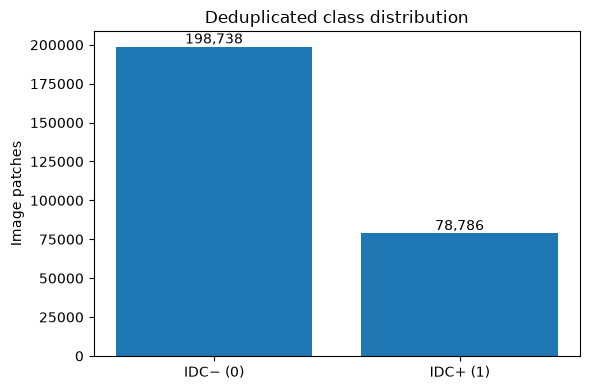

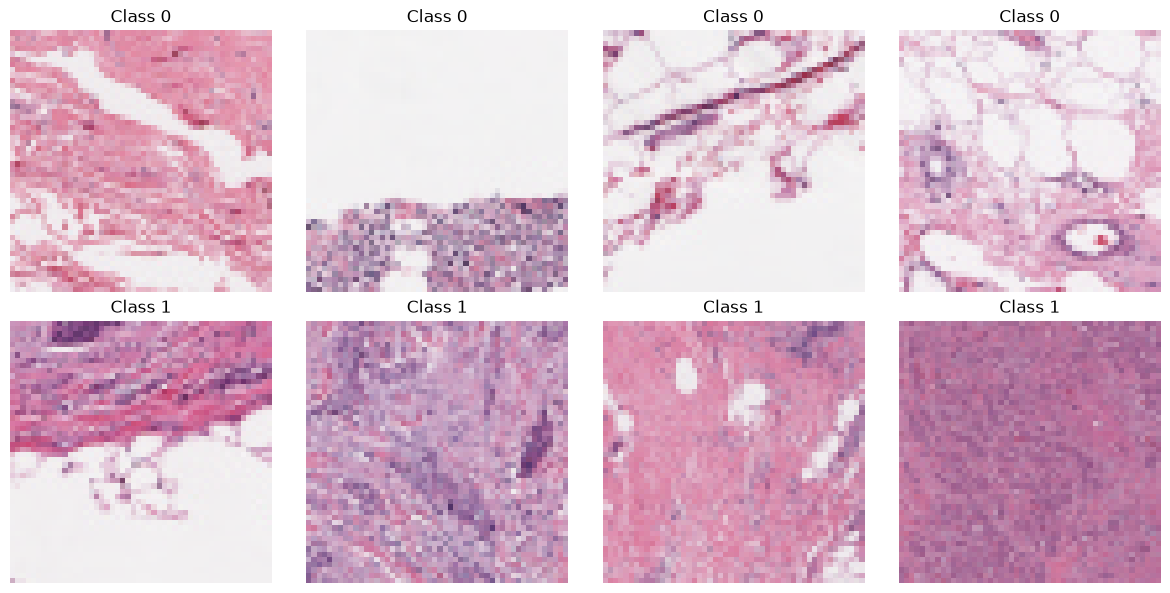

In [5]:
if ANALYSIS_ENABLED:
    print("Unique class counts:\n",images.label.value_counts().sort_index())
    print("Filename-derived groups (unverified as unique patients):",images.patient_id.nunique())
    fig,ax=plt.subplots(figsize=(6,4)); counts=images.label.value_counts().reindex([0,1],fill_value=0)
    bars=ax.bar(["IDC− (0)","IDC+ (1)"],counts.values)
    ax.bar_label(bars,labels=[f"{k:,}" for k in counts.values]);ax.set(ylabel="Image patches",title="Deduplicated class distribution")
    fig.tight_layout();fig.savefig(RESULTS_DIR/"02_class_balance.png",dpi=170);plt.show();plt.close(fig)
    fig,axs=plt.subplots(2,4,figsize=(12,6))
    for cls in [0,1]:
        subset=images[images.label==cls].sample(n=4,replace=len(images[images.label==cls])<4,random_state=SPLIT_SEED)
        for ax, row in zip(axs[cls],subset.itertuples()):
            with Image.open(DATA_ROOT/row.relative_path) as im: ax.imshow(im.convert("RGB"))
            ax.set(title=f"Class {cls}");ax.axis("off")
    fig.tight_layout();fig.savefig(RESULTS_DIR/"03_example_tiles.png",dpi=170);plt.show();plt.close(fig)


## 3. Filename-group-disjoint train/validation/test split (source patient identity not independently verified)

No patient may occur in more than one split.

In [6]:
# Split using source-derived numeric case prefixes (not authenticated clinical patient identities).
if ANALYSIS_ENABLED:
    def patient_split(frame, seed=SPLIT_SEED):
        pt=frame.groupby("patient_id").label.agg(has_positive="max", n_patches="size", n_positive="sum").reset_index()
        if len(pt)<12: raise ValueError("Need at least 12 patient groups for this 3-way evaluation")
        pt["positive_fraction"]=pt.n_positive/pt.n_patches
        if SPLIT_STRATIFICATION_MODE not in ("legacy_has_positive","patient_positive_ratio_bins"):
            raise ValueError("Unsupported SPLIT_STRATIFICATION_MODE")
        if SPLIT_STRATIFICATION_MODE=="patient_positive_ratio_bins":
            pt["ratio_group"]=pd.cut(pt.positive_fraction,bins=[-0.001,0,0.25,0.50,0.75,1.0],labels=False).fillna(0).astype(int)
        def maybe_stratify(table):
            if SPLIT_STRATIFICATION_MODE=="patient_positive_ratio_bins" and "ratio_group" in table:
                v=table.ratio_group.value_counts()
                if len(v)>1 and v.min()>=2:
                    return table.ratio_group
            v=table.has_positive.value_counts()
            return table.has_positive if len(v)==2 and v.min()>=2 else None
        tr,hold=train_test_split(pt,test_size=.30,random_state=seed,stratify=maybe_stratify(pt))
        va,te=train_test_split(hold,test_size=.50,random_state=seed,stratify=maybe_stratify(hold))
        split_map={pid:name for name,part in (("train",tr),("val",va),("test",te)) for pid in part.patient_id}
        out=frame.copy();out["split"]=out.patient_id.map(split_map)
        return out

    def validate_splits(table):
        groups={s:set(table.loc[table.split==s,"patient_id"]) for s in ("train","val","test")}
        assert all(groups[s] for s in groups),"Empty train/validation/test split"
        assert not(groups["train"]&groups["val"] or groups["train"]&groups["test"] or groups["val"]&groups["test"]),"Patient leakage"
        assert all(table.loc[table.split==s,"label"].nunique()==2 for s in groups),"A split is missing one IDC class"

    def subsample_for_quick(table):
        if MODE=="full": return table.reset_index(drop=True)
        caps=({"train":ALL_SMOKE_TRAIN_N,"val":ALL_SMOKE_VAL_N,"test":ALL_SMOKE_TEST_N} if RUN_PROFILE=="all_smoke" else
              ({"train":512,"val":128,"test":128} if RUN_PROFILE=="quick_train" else
              {"train":3000,"val":600,"test":600})); parts=[]
        for k,cap in caps.items():
            part=table[table.split==k]
            if len(part)>cap:
                _,part=train_test_split(part,test_size=cap,stratify=part.label,random_state=SPLIT_SEED)
            parts.append(part)
        return pd.concat(parts,ignore_index=True)

    full_manifest=patient_split(images)
    validate_splits(full_manifest)
    manifest=subsample_for_quick(full_manifest)
    validate_splits(manifest)
    for split_name in ("train","val","test"):
        counts = manifest.loc[manifest.split == split_name, "label"].value_counts()
        print(f"[{split_name}] {len(manifest[manifest.split == split_name])} patches, class counts:", counts.to_dict(), flush=True)
    manifest=manifest.reset_index(drop=True)
    manifest["sample_id"]=np.arange(len(manifest))
    print(manifest.groupby(["split","label"]).size().unstack(fill_value=0))
    print("Patients per split:",manifest.groupby("split").patient_id.nunique().to_dict())
    manifest.to_csv(MANIFEST_DIR/"manifest.csv",index=False,encoding="utf-8-sig")
    identity_rows=manifest[["relative_path","patient_id","label","split","bytes","mtime_ns"]].sort_values("relative_path")
    MANIFEST_ID=hashlib.sha256(identity_rows.to_csv(index=False).encode()).hexdigest()[:16]
    # The legacy MANIFEST_ID above MUST remain unchanged for old checkpoint compatibility.
    content_identity=manifest[["relative_path","patient_id","label","split","bytes"]].sort_values("relative_path")
    MANIFEST_PATH_ID=hashlib.sha256(content_identity.to_csv(index=False).encode()).hexdigest()[:16]
    RUN_META={"mode":MODE,"image_size":IMAGE_SIZE,"split_seed":SPLIT_SEED,
              "manifest_id":MANIFEST_ID,"n_images":len(manifest),"patient_count":manifest.patient_id.nunique(),
              "torch":torch.__version__,"torchvision":__import__("torchvision").__version__,
              "experiment_revision":EXPERIMENT_REVISION}
    from shutil import copy2
    full_experiment_key={"settings":EXPERIMENT_SETTINGS,"manifest_id":MANIFEST_ID,"manifest_path_id":MANIFEST_PATH_ID}
    final_experiment_id=hashlib.sha256(json.dumps(full_experiment_key,sort_keys=True,default=str).encode()).hexdigest()[:12]
    if final_experiment_id != EXPERIMENT_ID:
        previous_root,previous_results,previous_manifest=OUTPUT_ROOT,RESULTS_DIR,MANIFEST_DIR
        EXPERIMENT_ID=final_experiment_id
        OUTPUT_ROOT=PROFILE_ROOT/"experiments"/EXPERIMENT_ID
        RESULTS_DIR=OUTPUT_ROOT/"results"
        MANIFEST_DIR=OUTPUT_ROOT/"manifests"
        RESULTS_DIR.mkdir(parents=True,exist_ok=True)
        MANIFEST_DIR.mkdir(parents=True,exist_ok=True)
        # Previous successful completion metadata is preserved across stages.
        for src,dest in [(previous_results/"01_duplicate_audit.csv",RESULTS_DIR/"01_duplicate_audit.csv"),
                         (previous_results/"duplicate_audit.json",RESULTS_DIR/"duplicate_audit.json"),
                         (previous_manifest/"manifest.csv",MANIFEST_DIR/"manifest.csv"),
                         (previous_root/"experiment_settings.json",OUTPUT_ROOT/"experiment_settings.json")]:
            if src.is_file() and src != dest: copy2(src,dest)
        print("Data-verified experiment ID:",EXPERIMENT_ID,flush=True)
    (OUTPUT_ROOT/"run_metadata.json").write_text(json.dumps(RUN_META,indent=2),encoding="utf-8")
    # Write a new stage activity record without invalidating prior successful stages.
    def write_stage_activity(status, stage=None, details=None):
        stage = stage or RUN_STAGE
        record = {"status": status, "profile": RUN_PROFILE, "stage": stage,
                  "experiment_id": EXPERIMENT_ID, "manifest_id": MANIFEST_ID,
                  "started_at_unix": RUN_STARTED_AT, "updated_at_unix": time.time(),
                  "details": details or {}}
        (RESULTS_DIR / f"RUN_ACTIVITY_{stage.upper()}.json").write_text(
            json.dumps(record, indent=2, default=str), encoding="utf-8")
        (RESULTS_DIR / "RUN_ACTIVITY_CURRENT.json").write_text(
            json.dumps(record, indent=2, default=str), encoding="utf-8")
        return record
    write_stage_activity("RUNNING")
    print("Legacy-compatible manifest ID:",MANIFEST_ID,"| path identity:",MANIFEST_PATH_ID)


[train] 185782 patches, class counts: {0: 131471, 1: 54311}
[val] 40120 patches, class counts: {0: 29140, 1: 10980}
[test] 51622 patches, class counts: {0: 38127, 1: 13495}
label       0      1
split               
test    38127  13495
train  131471  54311
val     29140  10980
Patients per split: {'test': 42, 'train': 195, 'val': 42}
Data-verified experiment ID: eaebd064f2a8
Legacy-compatible manifest ID: 58a37814cee83c15 | path identity: 593c09920676c6be


### Patient-split balance

In [7]:
# Audit patient counts and IDC prevalence across train, validation, and test.
if ANALYSIS_ENABLED:
    ptab=(full_manifest.groupby(["patient_id","split"]).label
          .agg(n_patches="size",n_positive="sum").reset_index())
    ptab["positive_fraction"]=ptab.n_positive/ptab.n_patches
    ptab["has_positive"]=(ptab.n_positive>0)
    write_csv(ptab,"V9_patient_group_split_balance.csv")
    audit=[]
    for split_name,g in ptab.groupby("split"):
        selected=full_manifest[full_manifest.split==split_name]
        audit.append({"split":split_name,"filename_derived_groups":len(g),"patches":int(g.n_patches.sum()),
            "positive_patches":int(g.n_positive.sum()),
            "positive_patch_fraction":float(g.n_positive.sum()/g.n_patches.sum()),
            "median_patient_positive_fraction":float(g.positive_fraction.median()),
            "patient_positive_fraction_q10":float(g.positive_fraction.quantile(.1)),
            "patient_positive_fraction_q90":float(g.positive_fraction.quantile(.9)),
            "median_patches_per_patient":float(g.n_patches.median()),
            "max_patches_per_patient":int(g.n_patches.max()),
            "stratification_mode":SPLIT_STRATIFICATION_MODE})
    split_balance=pd.DataFrame(audit)
    write_csv(split_balance,"V9_patient_split_balance_summary.csv")
    display(split_balance)


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\V9_patient_group_split_balance.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\V9_patient_split_balance_summary.csv


,split,filename_derived_groups,patches,positive_patches,positive_patch_fraction,median_patient_positive_fraction,patient_positive_fraction_q10,patient_positive_fraction_q90,median_patches_per_patient,max_patches_per_patient,stratification_mode
0,test,42,51622,13495,0.261420,0.233461,0.084421,0.577348,1083.5,2302,legacy_has_positive
1,train,195,185782,54311,0.292337,0.266160,0.086193,0.620369,895.0,2395,legacy_has_positive
2,val,42,40120,10980,0.273679,0.323541,0.062820,0.567820,964.0,2216,legacy_has_positive


### Data lineage and grouping identity — source verification gate

The existing `patient_id` field is **parsed from filenames/folders** and must not be described as a source-verified unique patient. All splits and cluster bootstrap procedures are **filename-group-disjoint**; a group label is not an independent adjudicated patient/slide identity. External mapping is optional for running this retrospective methodological analysis, but mandatory before claiming patient-level disjointness. Obtain the mapping from an auditable dataset source rather than generating it from file names.

In [8]:
# Cross-check public source naming, case-folder grouping, patch labels, and split leakage.
# Source: Janowczyk & Madabhushi (2016), DOI: 10.4103/2153-3539.186902.
# Original source tutorial: https://andrewjanowczyk.com/use-case-6-invasive-ductal-carcinoma-idc-segmentation/
# Note: These checks do not authenticate biological patient identities from a hospital registry.
if RUN_PROFILE in ("all_research", "all_smoke"):
    _schema = r"^(?P<source_token>\d+(?:_idx\d+)?)_x(?P<x>\d+)_y(?P<y>\d+)_class(?P<label>[01])\.(?:png|jpg|jpeg|tif|tiff)$"
    # Use the filename column when available. Windows path separators are supported.
    _filenames = images["filename"].astype(str)
    _parsed = _filenames.str.extract(_schema, flags=re.IGNORECASE)
    if _parsed.isna().any(axis=1).any():
        _failed = _filenames[_parsed.isna().any(axis=1)].head(8).tolist()
        raise ValueError(f"DATA PROVENANCE: filename does not match public dataset schema: {_failed}")
    _case_prefix = _parsed.source_token.str.replace(r"_idx\d+$", "", regex=True)
    _folder_case = images.relative_path.astype(str).map(lambda s: s.replace("\\", "/").split("/")[-3])
    if not (_case_prefix.to_numpy() == images.patient_id.astype(str).to_numpy()).all():
        raise RuntimeError("DATA PROVENANCE: source filename case differs from model split group")
    if not (_case_prefix.to_numpy() == _folder_case.to_numpy()).all():
        raise RuntimeError("DATA PROVENANCE: source filename case differs from parent folder")
    if not (_parsed.label.astype(int).to_numpy() == images.label.astype(int).to_numpy()).all():
        raise RuntimeError("DATA PROVENANCE: source filename label differs from data label")
    _case_label_folder = images.relative_path.astype(str).map(lambda s: s.replace("\\", "/").split("/")[-2])
    if not (_case_label_folder.to_numpy() == images.label.astype(str).to_numpy()).all():
        raise RuntimeError("DATA PROVENANCE: class parent folder differs from filename label")
    _source_frame = pd.DataFrame({
        "filename_group_id": images.patient_id.astype(str).to_numpy(),
        "public_source_patient_token": _parsed.source_token.to_numpy(),
        "x": _parsed.x.astype(int).to_numpy(),
        "y": _parsed.y.astype(int).to_numpy(),
        "label": images.label.astype(int).to_numpy(),
    })
    if _source_frame.duplicated(["public_source_patient_token", "x", "y", "label"]).any():
        raise RuntimeError("DATA PROVENANCE: duplicate location in unique manifest")
    if _source_frame.groupby(["public_source_patient_token", "x", "y"]).label.nunique().gt(1).any():
        raise RuntimeError("DATA PROVENANCE: a patch coordinate has conflicting labels")
    _split_source = manifest[["relative_path", "patient_id", "split"]].copy()
    _split_source["public_source_patient_token"] = _split_source.relative_path.astype(str).map(
        lambda s: re.fullmatch(_schema, s.replace("\\", "/").split("/")[-1], flags=re.IGNORECASE).group("source_token"))
    if _split_source.groupby("public_source_patient_token").split.nunique().gt(1).any():
        raise RuntimeError("DATA PROVENANCE: the same public source patient token appears in multiple splits")
    if _split_source.groupby("patient_id").split.nunique().gt(1).any():
        raise RuntimeError("DATA PROVENANCE: the same numeric case group appears in multiple splits")
    _summary = _source_frame.groupby(["filename_group_id", "public_source_patient_token"],
        as_index=False).agg(n_patches=("label", "size"), n_idc_positive=("label", "sum"))
    _summary.to_csv(RESULTS_DIR / "SOURCE_CASE_GROUP_AUDIT.csv", index=False)
    _expected_counts = {0: 198738, 1: 78786}
    _observed_counts = {int(k): int(v) for k, v in images.label.value_counts().items()}
    _dataset_counts_match = bool(len(images) == 277524 and _observed_counts == _expected_counts)
    if RUN_PROFILE == "all_research" and not _dataset_counts_match:
        raise RuntimeError("DATA PROVENANCE: local unique patch/class totals do not match the source description")
    lineage = {
        "status": "PUBLIC_SOURCE_NAMING_AND_SPLIT_INTEGRITY_VERIFIED; BIOLOGICAL_IDENTITY_NOT_INDEPENDENTLY_VERIFIED",
        "source": {
            "kaggle": "https://www.kaggle.com/datasets/paultimothymooney/breast-histopathology-images",
            "original_author": "https://andrewjanowczyk.com/use-case-6-invasive-ductal-carcinoma-idc-segmentation/",
            "paper_doi": "10.4103/2153-3539.186902",
            "reported_whole_mount_slide_count": 162,
            "reported_patch_count": 277524,
            "reported_class_counts": {"0": 198738, "1": 78786},
            "author_described_patient_token_example": "10253_idx5",
        },
        "observed_unique_patches": int(len(images)),
        "observed_case_prefix_groups": int(_source_frame.filename_group_id.nunique()),
        "observed_author_named_patient_tokens": int(_source_frame.public_source_patient_token.nunique()),
        "filename_and_folder_consistent": True,
        "labels_and_patch_coordinates_consistent": True,
        "disjoint_by_case_prefix_and_author_named_token": True,
        "matches_source_patch_and_label_counts": _dataset_counts_match,
        "source_original_slide_to_local_group_mapping_verified": False,
        "independent_biological_patient_identity_verified": False,
        "verified_patient_count": None,
        "verified_slide_count": None,
        "source_162_slides_vs_local_groups_note": (
            "162 source whole-mount slides and the observed case-prefix groups represent different units; "
            "do not interpret group count as the number of unique biological patients or slides."),
        "external_mapping_provided": False,
        "requirements_before_unqualified_patient_level_claims": [
            "obtain and independently inspect an authentic source case/patient-to-slide registry",
            "verify clinical patient-to-slide relationships and original annotation reference standard",
            "document original archive version/hash and applicable reuse rights",
            "obtain ethics/IRB determination and independent scientific manuscript review",
        ],
    }
    if VERIFIED_GROUP_MAPPING_CSV is not None:
        mapping_path = Path(VERIFIED_GROUP_MAPPING_CSV)
        if not mapping_path.is_file():
            raise FileNotFoundError(f"Specified provenance mapping does not exist: {mapping_path}")
        mapping = pd.read_csv(mapping_path, dtype=str).fillna("")
        required = {"filename_group_id", "verified_patient_id", "verified_slide_id", "source_document", "verification_method"}
        if not required.issubset(mapping.columns):
            raise ValueError(f"Provenance mapping requires: {sorted(required)}")
        if mapping[list(required)].apply(lambda col: col.str.strip().eq("")).any().any():
            raise ValueError("Provenance mapping has missing required evidence")
        if mapping.filename_group_id.duplicated().any():
            raise ValueError("The provenance mapping has repeated group rows")
        if set(mapping.filename_group_id) != set(_source_frame.filename_group_id):
            raise ValueError("Provenance mapping must cover every source filename-group prefix exactly once")
        src = _split_source[["patient_id", "split"]].drop_duplicates().merge(mapping,
            left_on="patient_id", right_on="filename_group_id", validate="many_to_one")
        if src.groupby("verified_patient_id").split.nunique().gt(1).any():
            raise RuntimeError("PATIENT LEAKAGE: linked biological case spans multiple splits")
        lineage.update({"external_mapping_provided": True, "mapping_consistency_verified": True,
            "mapping_sha256": hashlib.sha256(mapping_path.read_bytes()).hexdigest(),
            "mapped_patient_id_count": int(mapping.verified_patient_id.nunique()),
            "mapped_slide_id_count": int(mapping.verified_slide_id.nunique()),
            "mapped_biological_identity_requires_independent_registry_review": True})
    (RESULTS_DIR / "SUBMISSION_DATA_LINEAGE.json").write_text(
        json.dumps(lineage, ensure_ascii=False, indent=2), encoding="utf-8")
    print("[SOURCE PROVENANCE] public filename schema, class labels, coordinates and split grouping: VERIFIED")
    print("[SOURCE IDENTITY] source-named patient tokens:", lineage["observed_author_named_patient_tokens"],
          "| numeric case-prefix groups:", lineage["observed_case_prefix_groups"])
    print("[SOURCE IDENTITY] authentic biological patient-to-slide mapping: UNVERIFIED; clinical patient counts not claimed")


[SOURCE PROVENANCE] public filename schema, class labels, coordinates and split grouping: VERIFIED
[SOURCE IDENTITY] source-named patient tokens: 279 | numeric case-prefix groups: 279
[SOURCE IDENTITY] authentic biological patient-to-slide mapping: UNVERIFIED; clinical patient counts not claimed


### Source-identity interpretation and publication boundary

The original [Janowczyk & Madabhushi (2016)](https://doi.org/10.4103/2153-3539.186902) documentation describes filename tokens such as `10253_idx5` as patient IDs and reports **162 source whole-mount slides**. The notebook's `patient_id` field remains a **numeric prefix group** (e.g., `10253`) for checkpoint and split compatibility. These identity units are not interchangeable. The source filename schema and within-split grouping can be checked automatically; **unique biological patient counts and slide-to-patient links cannot be certified** without independent source records. All cluster confidence intervals refer to numeric filename-derived groups, not independently verified individuals. See `SUBMISSION_DATA_LINEAGE.json` and the external `verify_idc_provenance.py` script.

## 4. Datasets, transforms, and model definitions

In [9]:
# Keep attacks in raw [0, 1] pixel space; normalize only inside each model.
if ANALYSIS_ENABLED:
    class IDCPatches(Dataset):
        def __init__(self,df,root,augment=False):
            self.df=df.reset_index(drop=True);self.root=root
            steps=[transforms.Resize((IMAGE_SIZE,IMAGE_SIZE))]
            if augment:
                steps += [transforms.RandomHorizontalFlip(),transforms.RandomVerticalFlip(),
                          transforms.ColorJitter(brightness=.08,contrast=.08,saturation=.05)]
            self.tf=transforms.Compose(steps+[transforms.ToTensor()])
        def __len__(self): return len(self.df)
        def __getitem__(self,idx):
            r=self.df.iloc[idx]
            with Image.open(self.root/r.relative_path) as im: x=self.tf(im.convert("RGB"))
            return x,int(r.label),int(r.sample_id)

    def loader_for(df,split,batch_size=BATCH_SIZE,train=False,seed=TRAIN_SEED):
        part=df[df.split==split].reset_index(drop=True)
        ds=IDCPatches(part,DATA_ROOT,augment=train)
        sampler=None
        if train:
            freq=part.label.value_counts().to_dict()
            weights=torch.tensor([1.0/freq[y] for y in part.label],dtype=torch.double)
            gen=torch.Generator().manual_seed(int(seed))
            sampler=WeightedRandomSampler(weights,num_samples=len(part),replacement=True,generator=gen)
        return DataLoader(ds,batch_size=batch_size,sampler=sampler,shuffle=False,
                          num_workers=NUM_WORKERS,pin_memory=DEVICE.type=="cuda")

    MEAN_IMAGENET=(.485,.456,.406);STD_IMAGENET=(.229,.224,.225)
    class PixelSpaceModel(nn.Module):
        def __init__(self,backbone,mean=(.5,.5,.5),std=(.5,.5,.5)):
            super().__init__();self.backbone=backbone
            self.register_buffer("mean",torch.tensor(mean).view(1,3,1,1))
            self.register_buffer("std",torch.tensor(std).view(1,3,1,1))
        def forward(self,x): return self.backbone((x-self.mean)/self.std)

    class SmallCNN(nn.Module):
        def __init__(self):
            super().__init__()
            self.features=nn.Sequential(nn.Conv2d(3,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                nn.Conv2d(64,128,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d(1))
            self.head=nn.Sequential(nn.Flatten(),nn.Linear(128,64),nn.ReLU(),nn.Dropout(.2),nn.Linear(64,2))
        def forward(self,x):return self.head(self.features(x))

    def construct_model(name,pretrained=None):
        if name=="cnn": return PixelSpaceModel(SmallCNN())
        if name.startswith("resnet18"):
            use_pt=name.endswith("pretrained")
            weights=tvmodels.ResNet18_Weights.DEFAULT if use_pt and pretrained is not False else None
            net=tvmodels.resnet18(weights=weights)
            net.fc=nn.Linear(net.fc.in_features,2)
            return PixelSpaceModel(net,MEAN_IMAGENET,STD_IMAGENET) if use_pt else PixelSpaceModel(net)
        if name=="mobilenetv3_small_pretrained":
            weights=tvmodels.MobileNet_V3_Small_Weights.DEFAULT if pretrained is not False else None
            net=tvmodels.mobilenet_v3_small(weights=weights)
            net.classifier[-1]=nn.Linear(net.classifier[-1].in_features,2)
            return PixelSpaceModel(net,MEAN_IMAGENET,STD_IMAGENET)
        if name=="efficientnet_b0_pretrained":
            weights=tvmodels.EfficientNet_B0_Weights.DEFAULT if pretrained is not False else None
            net=tvmodels.efficientnet_b0(weights=weights)
            net.classifier[-1]=nn.Linear(net.classifier[-1].in_features,2)
            return PixelSpaceModel(net,MEAN_IMAGENET,STD_IMAGENET)
        if name=="densenet121_pretrained":
            weights=tvmodels.DenseNet121_Weights.DEFAULT if pretrained is not False else None
            net=tvmodels.densenet121(weights=weights)
            net.classifier=nn.Linear(net.classifier.in_features,2)
            return PixelSpaceModel(net,MEAN_IMAGENET,STD_IMAGENET)
        if name=="convnext_tiny_pretrained":
            weights=tvmodels.ConvNeXt_Tiny_Weights.DEFAULT if pretrained is not False else None
            net=tvmodels.convnext_tiny(weights=weights)
            net.classifier[-1]=nn.Linear(net.classifier[-1].in_features,2)
            return PixelSpaceModel(net,MEAN_IMAGENET,STD_IMAGENET)
        raise ValueError(name)

    train_loader=loader_for(manifest,"train",train=True)
    val_loader=loader_for(manifest,"val")
    test_loader=loader_for(manifest,"test")
    xx,yy,ids=next(iter(train_loader))
    assert xx.shape[1:]==(3,IMAGE_SIZE,IMAGE_SIZE)
    assert 0<=float(xx.min()) and float(xx.max())<=1
    print("Batch:",xx.shape,"labels:",Counter(yy.tolist()))


Batch: torch.Size([32, 3, 128, 128]) labels: Counter({0: 17, 1: 15})


## 5. Baselines and checkpoint reuse

Checkpoint reuse requires a matching dataset manifest and training configuration.

In [10]:
# Reload only checkpoints that match the dataset manifest and model settings.
if ANALYSIS_ENABLED:
    def key_hash(config):
        return hashlib.sha256(json.dumps(config, sort_keys=True, default=str).encode()).hexdigest()[:16]

    def load_ckpt(path, name):
        ck = torch.load(path, map_location="cpu", weights_only=True)
        model = construct_model(name, pretrained=False)
        model.load_state_dict(ck["state_dict"], strict=True)
        return model.to(DEVICE).eval()

    def predict_frame(model, loader):
        model.eval(); rows=[]
        with torch.no_grad():
            for x,y,ids in loader:
                probs=torch.softmax(model(x.to(DEVICE)), dim=1)[:,1].cpu().numpy()
                rows.extend(zip(ids.tolist(), y.tolist(), probs.tolist()))
        ans=pd.DataFrame(rows, columns=["sample_id","y","p"])
        return ans.merge(manifest[["sample_id","patient_id","split","relative_path"]],
                         on="sample_id", how="left", validate="one_to_one")

    def binary_scores(y, p, threshold=.5):
        y=np.asarray(y,dtype=int); p=np.asarray(p,dtype=float)
        pred=(p>=threshold).astype(int)
        tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
        out={"n":len(y),"accuracy":accuracy_score(y,pred),
             "precision":precision_score(y,pred,zero_division=0),
             "recall":recall_score(y,pred,zero_division=0),
             "specificity":tn/max(tn+fp,1), "false_negative_rate":fn/max(fn+tp,1),
             "f1":f1_score(y,pred,zero_division=0),
             "roc_auc":float("nan"),"pr_auc":float("nan"),
             "brier":brier_score_loss(y,p),
             "tn":int(tn),"fp":int(fp),"fn":int(fn),"tp":int(tp)}
        if len(np.unique(y))==2:
            out["roc_auc"]=roc_auc_score(y,p)
            out["pr_auc"]=average_precision_score(y,p)
        return out

    def validation_thresholds(val_pred, target_recall=TARGET_RECALL):
        """Select thresholds from validation labels ONLY; tie-breaking is deterministic.

        Policies returned here are reused in Section 6A, attack evaluation, and saved
        comparisons; never tune a threshold using attacked or clean test labels.
        """
        y=np.asarray(val_pred.y,dtype=int)
        p=np.asarray(val_pred.p,dtype=float)
        grid=np.unique(np.round(np.r_[0.0,np.linspace(.001,.999,501),1.0],6))
        order=np.argsort(p); ranked_p=p[order]; ranked_y=y[order]
        cum_pos=np.r_[0,np.cumsum(ranked_y)]
        indices=np.searchsorted(ranked_p,grid,side="left")
        fn=cum_pos[indices].astype(float)
        tp=(y.sum()-fn).astype(float)
        fp=(len(y)-indices-tp).astype(float)
        tn=(indices-fn).astype(float)
        f1vals=np.divide(2*tp,2*tp+fp+fn,out=np.zeros_like(tp),where=(2*tp+fp+fn)>0)
        precision=np.divide(tp,tp+fp,out=np.zeros_like(tp),where=(tp+fp)>0)
        recall=np.divide(tp,tp+fn,out=np.zeros_like(tp),where=(tp+fn)>0)
        specificity=np.divide(tn,tn+fp,out=np.zeros_like(tp),where=(tn+fp)>0)
        f1thr=float(grid[int(np.argmax(f1vals))])
        candidates=[(float(precision[k]),float(specificity[k]),float(grid[k]))
                    for k in range(len(grid)) if recall[k]+1e-12 >= target_recall]
        if not candidates:
            raise ValueError("Validation recall target cannot be met (check validation labels).")
        return {"default_0.50":0.5,"validation_F1":f1thr,
                f"validation_recall_at_least_{target_recall:.0%}":max(candidates)[2]}

    def baseline_config(name, seed=TRAIN_SEED):
        epochs=MAX_EPOCHS[name]
        lr=3e-4 if name in ("cnn","resnet18_scratch") else 1e-4
        return {"manifest_id":MANIFEST_ID,"model":name,"seed":seed,"image_size":IMAGE_SIZE,
                "epochs":epochs,"lr":lr,"patience":PATIENCE,"optimizer":"AdamW",
                "weight_decay":1e-4,"balanced_sampling":True,
                "augmentation":"flip/colorjitter_v1","batch_size":BATCH_SIZE,
                "pretrained":name.endswith("pretrained"),
                "experiment_revision":EXPERIMENT_REVISION,
                "torch_version":str(torch.__version__),
                "torchvision_version":torchvision.__version__}

    def find_matching_checkpoint(name, config):
        # An exact config match is mandatory: file name alone is never enough.
        expected=f"baseline_{name}_{key_hash(config)}.pt"
        candidate_differences=[]
        candidate_paths = list(CANDIDATE_CHECKPOINT_FILES)
        for folder in CHECKPOINT_SEARCH_DIRS:
            if folder.is_dir():
                candidate_paths.extend(folder.glob(f"baseline_{name}_*.pt"))
        seen = set()
        for path in candidate_paths:
            path = Path(path).resolve()
            if path in seen or not path.is_file() or not path.name.startswith(f"baseline_{name}_"):
                continue
            seen.add(path)
            try:
                checkpoint=torch.load(path,map_location="cpu",weights_only=True)
                prior=checkpoint.get("config",{})
                if path.name == expected and prior == config and "state_dict" in checkpoint:
                    print("Compatible checkpoint found:",path)
                    return path
                changed={key:(prior.get(key,"<missing>"),config.get(key,"<missing>"))
                         for key in sorted(set(prior)|set(config)) if prior.get(key)!=config.get(key)}
                candidate_differences.append((str(path),changed))
            except Exception as exc:
                print("Unreadable checkpoint:",path,"|",repr(exc))
        if candidate_differences:
            print("Checkpoints found but strict metadata did not match:")
            for file,diff in candidate_differences[:3]:
                print(" -",file,"| different settings:",diff)
        return None

    def train_baseline(name, seed=TRAIN_SEED):
        seed_everything(seed)
        cfg=baseline_config(name,seed)
        signature=key_hash(cfg)
        target=CHECKPOINT_DIR/f"baseline_{name}_{signature}.pt"
        saved=find_matching_checkpoint(name,cfg) if REUSE_CHECKPOINTS else None
        if RUN_STAGE == "analyses" and saved is None:
            raise FileNotFoundError(f"RUN_STAGE=analyses requires a matching baseline checkpoint for {name}. "
                                    f"Run baseline_only first, then rerun with analyses. Expected: {target}")
        if saved is not None:
            print(f"[{name}] Checkpoint reused; no training performed.", flush=True)
            return load_ckpt(saved,name),saved
        if TRAIN_POLICY == "reuse_only":
            candidates=[str(p) for p in CANDIDATE_CHECKPOINT_FILES if p.name.startswith(f"baseline_{name}_")]
            if not candidates:
                candidates=[str(p) for folder in CHECKPOINT_SEARCH_DIRS if folder.is_dir()
                            for p in folder.glob(f"baseline_{name}_*.pt")]
            raise FileNotFoundError(
                f"No exactly compatible .pt checkpoint for {name}.\n"
                f"Expected filename: {target.name}\n"
                f"Checked checkpoint directories: {list(map(str,CHECKPOINT_SEARCH_DIRS))}\n"
                f"Discovered other candidate files: {candidates[:15]}\n"
                "Training was NOT started. If you have the old .pt file, put its full path "
                "in EXTRA_CHECKPOINT_FILES at Section 0, and restart from Section 0. "
                "If it does not exist anywhere, the trained weights cannot be recovered from a CSV. "
                "Select RUN_PROFILE='quick_train' ONLY if you intentionally want a new small training run.")
        if MODE == "full" and DEVICE.type == "cpu" and not ALLOW_FULL_CPU_TRAINING:
            raise RuntimeError("Full CPU training is blocked. Use a CUDA-enabled PyTorch environment "
                               "or explicitly set ALLOW_FULL_CPU_TRAINING=True in Section 0.")
        print(f"[{name}] Starting intentionally requested training: {cfg['epochs']} epochs; {DEVICE}.",flush=True)
        model=construct_model(name).to(DEVICE)
        optimizer=torch.optim.AdamW(model.parameters(),lr=cfg["lr"],weight_decay=1e-4)
        train_loader=loader_for(manifest,"train",train=True,seed=seed)
        history=[]; best=-float("inf"); stale=0
        for epoch in range(1,cfg["epochs"]+1):
            t0=time.perf_counter(); model.train();total_loss=0.0
            print(f"[{name}] Epoch {epoch}/{cfg['epochs']} started ({len(train_loader)} batches)",flush=True)
            progress_step=max(1, len(train_loader)//4)
            for batch_number,(x,y,_) in enumerate(train_loader, start=1):
                x=x.to(DEVICE); y=y.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss=F.cross_entropy(model(x),y)
                loss.backward(); optimizer.step()
                total_loss+=float(loss.item())*len(y)
                if SHOW_EPOCH_PROGRESS and (batch_number % progress_step == 0 or batch_number == len(train_loader)):
                    print(f"[{name}] epoch {epoch}: batch {batch_number}/{len(train_loader)}, "
                          f"elapsed={time.perf_counter()-t0:.1f}s",flush=True)
            valid=predict_frame(model,val_loader)
            auc=binary_scores(valid.y,valid.p)["roc_auc"]
            score=float(auc) if np.isfinite(auc) else -float("inf")
            history.append({"epoch":epoch,"loss":total_loss/len(train_loader.dataset),
                            "val_roc_auc":auc,"seconds":time.perf_counter()-t0})
            print(f"{name}: epoch {epoch}/{cfg['epochs']}, loss={history[-1]['loss']:.4f}, "
                  f"val_auc={auc:.4f}, seconds={history[-1]['seconds']:.1f}",flush=True)
            if epoch==1 or score>best+1e-5:
                best=score;stale=0
                torch.save({"state_dict":model.state_dict(),"config":cfg,"epoch":epoch},target)
                print("Checkpoint saved:",target,flush=True)
            else:
                stale+=1
                if stale>=PATIENCE:
                    print("Early stopping",flush=True);break
        write_csv(pd.DataFrame(history),f"history_{name}_{signature}.csv")
        return load_ckpt(target,name),target

    model_dict={}; baseline_predictions={}; base_rows=[]; checkpoint_paths={}
    try:
        for model_name in BASELINE_MODELS:
            print("\n>>> BASELINE:",model_name,"|",TRAIN_POLICY,flush=True)
            model,cp=train_baseline(model_name)
            model_dict[model_name]=model;checkpoint_paths[model_name]=cp
            val_pred=predict_frame(model,val_loader); test_pred=predict_frame(model,test_loader)
            baseline_predictions[model_name]={"val":val_pred,"test":test_pred}
            selected=validation_thresholds(val_pred)
            for policy in ("default_0.50", "validation_F1"):
                threshold=selected[policy]
                base_rows.append({"model":model_name,"threshold_rule":policy,"threshold":threshold,
                                  "mode":MODE,**binary_scores(test_pred.y,test_pred.p,threshold)})
            write_csv(test_pred,f"test_predictions_{model_name}.csv")
    except FileNotFoundError as exc:
        if TRAIN_POLICY != "reuse_only":
            raise
        ANALYSIS_ENABLED = False
        RECOVERY_REASON = str(exc)
        model_dict.clear(); baseline_predictions.clear(); base_rows.clear(); checkpoint_paths.clear()
        print("\nRECOVERY REPORT: No compatible CNN weights found.")
        print(RECOVERY_REASON)
        print("Other analyses will be safely skipped; no new model training was started.")

    if ANALYSIS_ENABLED:
        baseline_table=pd.DataFrame(base_rows)
        write_csv(baseline_table,"baseline_model_comparison.csv")
        display(baseline_table)
        print("All selected baselines loaded / evaluated:",list(model_dict))



>>> BASELINE: cnn | train_missing
Compatible checkpoint found: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\checkpoints\baseline_cnn_bf38200951cd68ed.pt
[cnn] Checkpoint reused; no training performed.
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\test_predictions_cnn.csv

>>> BASELINE: resnet18_pretrained | train_missing
Compatible checkpoint found: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\checkpoints\baseline_resnet18_pretrained_7df5baa1e148a458.pt
[resnet18_pretrained] Checkpoint reused; no training performed.
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\test_predictions_resnet18_pretrained.csv

>>> BASELINE: mobilenetv3_small_pretrained | train_missing
Compatible checkpoint found: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\checkpoints\baseline_mobilenetv3_small_pretrained_82989cbf1659dc79.p

,model,threshold_rule,threshold,mode,n,accuracy,precision,recall,specificity,false_negative_rate,f1,roc_auc,pr_auc,brier,tn,fp,fn,tp
0,cnn,default_0.50,0.500000,full,51622,0.853512,0.662825,0.894850,0.838881,0.105150,0.761556,0.937381,0.838553,0.106956,31984,6143,1419,12076
1,cnn,validation_F1,0.729540,full,51622,0.879354,0.760410,0.786217,0.912319,0.213783,0.773098,0.937381,0.838553,0.106956,34784,3343,2885,10610
2,resnet18_pretrained,default_0.50,0.500000,full,51622,0.863895,0.678219,0.912116,0.846828,0.087884,0.777967,0.951429,0.888557,0.098121,32287,5840,1186,12309
3,resnet18_pretrained,validation_F1,0.679640,full,51622,0.893960,0.768422,0.850760,0.909251,0.149240,0.807498,0.951429,0.888557,0.098121,34667,3460,2014,11481
4,mobilenetv3_small_pretrained,default_0.50,0.500000,full,51622,0.884371,0.728782,0.888255,0.882996,0.111745,0.800655,0.951185,0.878931,0.086916,33666,4461,1508,11987
5,mobilenetv3_small_pretrained,validation_F1,0.595808,full,51622,0.892197,0.758508,0.862097,0.902851,0.137903,0.806992,0.951185,0.878931,0.086916,34423,3704,1861,11634


All selected baselines loaded / evaluated: ['cnn', 'resnet18_pretrained', 'mobilenetv3_small_pretrained']


### Staged execution checkpoint

In [11]:
if ANALYSIS_ENABLED and RUN_STAGE in ("baseline_only", "split_stability"):
    if RUN_STAGE == "baseline_only":
        stage_marker = {"profile": RUN_PROFILE, "stage": RUN_STAGE,
            "baseline_models": list(model_dict), "manifest_id": MANIFEST_ID,
            "experiment_id": EXPERIMENT_ID,
            "checkpoint_paths": {k: str(v) for k, v in checkpoint_paths.items()},
            "baseline_outputs_complete": (RESULTS_DIR / "baseline_model_comparison.csv").is_file(),
            "not_a_full_research_completion": True}
        (RESULTS_DIR / "V9_STAGE_BASELINE_ONLY.json").write_text(
            json.dumps(stage_marker, indent=2), encoding="utf-8")
        write_stage_activity("COMPLETED", details=stage_marker)
        print("[BASELINE COMPLETE] Baselines saved; advanced analyses intentionally skipped.")
    else:
        print("[SPLIT STABILITY] Loading primary models succeeded; alternate splits run later.")
    ANALYSIS_ENABLED = False

### Baseline IDC-positive recall audit

In [12]:
# Report IDC-positive recall collapse even when overall accuracy looks acceptable.
if ANALYSIS_ENABLED:
    baseline_readiness_rows=[]
    for model_name,pair in baseline_predictions.items():
        p=pair["test"]
        y=p.y.to_numpy(dtype=int)
        pred=(p.p.to_numpy(dtype=float)>=0.5).astype(int)
        positive=y==1
        negative=y==0
        n_correct_positive=int((pred[positive]==1).sum())
        positive_recall=float((pred[positive]==1).mean()) if positive.any() else np.nan
        negative_recall=float((pred[negative]==0).mean()) if negative.any() else np.nan
        warning=[]
        if len(p)<500: warning.append("SMALL_TEST_SAMPLE")
        if positive.sum()<MIN_CLEAN_CORRECT_POSITIVE_N: warning.append("TOO_FEW_POSITIVE_PATCHES")
        if positive_recall==0: warning.append("IDC_POSITIVE_RECALL_COLLAPSE")
        if len(np.unique(pred))==1: warning.append("SINGLE_PREDICTED_CLASS")
        if MODE=="quick": warning.append("QUICK_TEST_NOT_RESEARCH")
        baseline_readiness_rows.append({
            "model":model_name,"test_n":len(y),"test_positive_n":int(positive.sum()),
            "test_negative_n":int(negative.sum()),"predicted_positive_n":int((pred==1).sum()),
            "correct_positive_n":n_correct_positive,
            "positive_recall_default_0p5":positive_recall,
            "negative_specificity_default_0p5":negative_recall,
            "warnings":";".join(warning),
            "research_claim_status":"PRELIMINARY_ONLY" if warning else "REQUIRES_STRONG_ATTACK_AND_REPEATED_VALIDATION"
        })
    baseline_readiness_table=pd.DataFrame(baseline_readiness_rows)
    write_csv(baseline_readiness_table,"baseline_class_collapse_and_readiness.csv")
    display(baseline_readiness_table)
    if baseline_readiness_table.warnings.str.contains("IDC_POSITIVE_RECALL_COLLAPSE").any():
        print("[WARNING] At least one baseline detects no IDC+ patches at threshold 0.5."
              " Attack/defense accuracy does not establish meaningful positive-class robustness.")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\baseline_class_collapse_and_readiness.csv


,model,test_n,test_positive_n,test_negative_n,predicted_positive_n,correct_positive_n,positive_recall_default_0p5,negative_specificity_default_0p5,warnings,research_claim_status
0,cnn,51622,13495,38127,18219,12076,0.894850,0.838881,,REQUIRES_STRONG_ATTACK_AND_REPEATED_VALIDATION
1,resnet18_pretrained,51622,13495,38127,18149,12309,0.912116,0.846828,,REQUIRES_STRONG_ATTACK_AND_REPEATED_VALIDATION
2,mobilenetv3_small_pretrained,51622,13495,38127,16448,11987,0.888255,0.882996,,REQUIRES_STRONG_ATTACK_AND_REPEATED_VALIDATION


## 6. Baseline performance, calibration, and thresholds

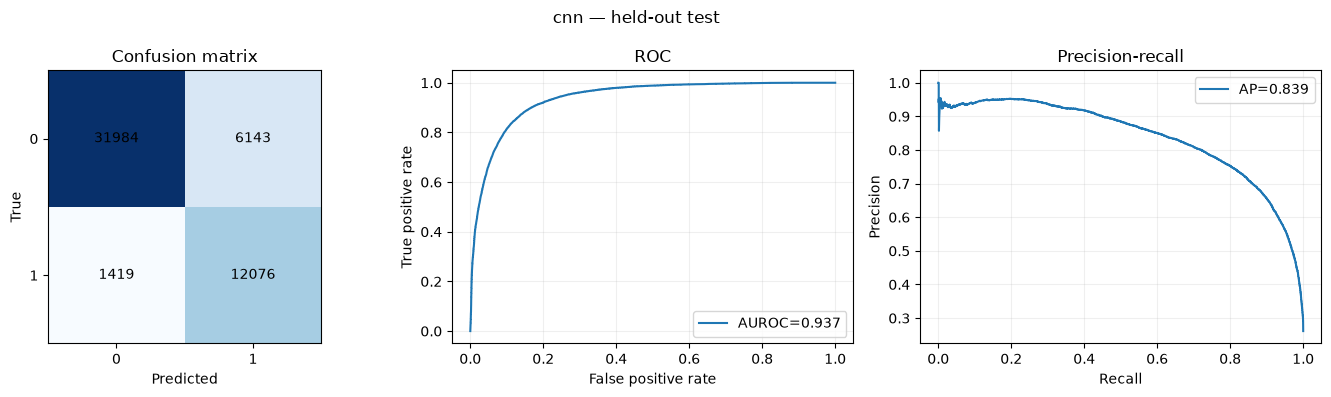

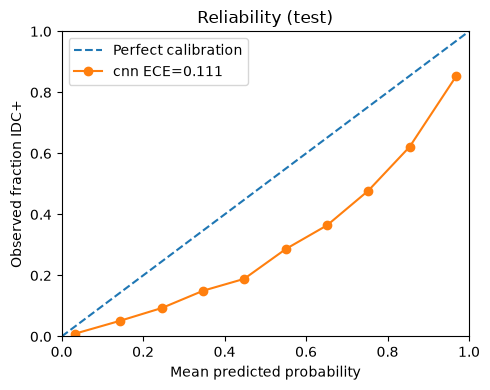

Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\false_negatives_cnn.csv


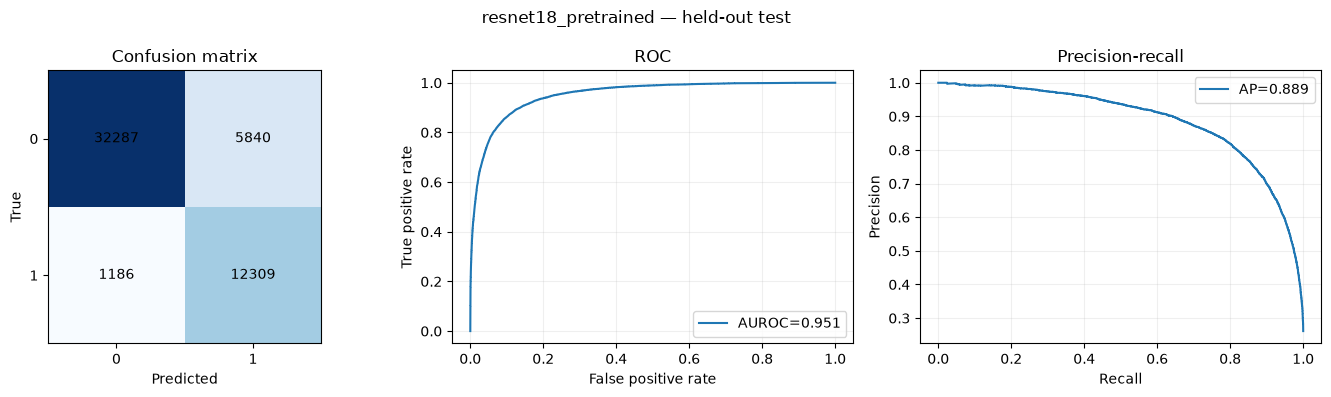

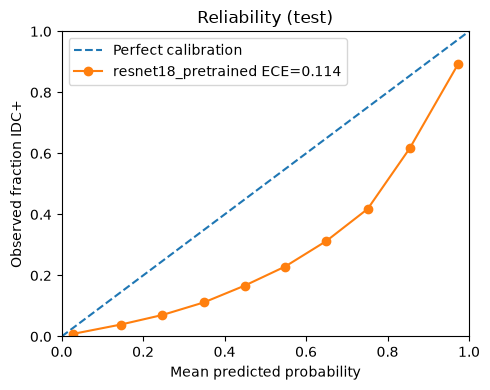

Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\false_negatives_resnet18_pretrained.csv


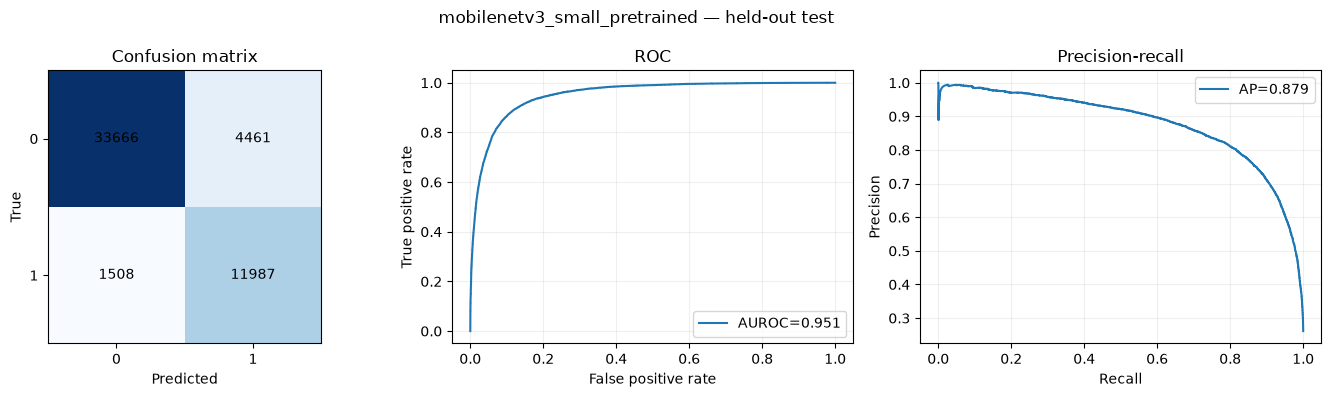

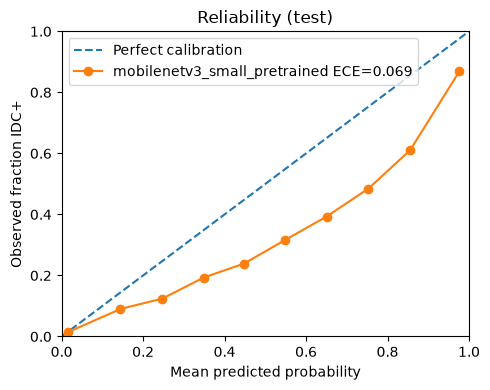

Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\false_negatives_mobilenetv3_small_pretrained.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\patient_cluster_bootstrap_CI.csv


,model,threshold_policy,threshold,metric,estimate,ci_lower,ci_upper,patients,patches
0,cnn,default_0.50,0.500000,accuracy,0.853512,0.819500,0.881183,42,51622
1,cnn,default_0.50,0.500000,recall,0.894850,0.868000,0.921378,42,51622
2,cnn,default_0.50,0.500000,f1,0.761556,0.707315,0.813909,42,51622
3,cnn,validation_F1,0.729540,accuracy,0.879354,0.852689,0.902285,42,51622
4,cnn,validation_F1,0.729540,recall,0.786217,0.734702,0.834704,42,51622
5,cnn,validation_F1,0.729540,f1,0.773098,0.724355,0.819185,42,51622
6,cnn,validation_F1,0.729540,roc_auc,0.937381,0.917669,0.952878,42,51622
7,cnn,validation_F1,0.729540,pr_auc,0.838553,0.775573,0.888965,42,51622
8,cnn,validation_recall_at_least_90%,0.316368,accuracy,0.807040,0.769738,0.839280,42,51622
9,cnn,validation_recall_at_least_90%,0.316368,recall,0.941386,0.921861,0.957917,42,51622


In [13]:
if ANALYSIS_ENABLED:
    def ece(y,p,bins=10):
        y=np.asarray(y);p=np.asarray(p);edges=np.linspace(0,1,bins+1)
        total=0
        for k in range(bins):
            mask=(p>=edges[k]) & ((p<=edges[k+1]) if k==bins-1 else (p<edges[k+1]))
            if mask.any(): total+=mask.mean()*abs(p[mask].mean()-y[mask].mean())
        return float(total)

    def plot_model_diagnostics(model_name, pred):
        y=pred.y.to_numpy();p=pred.p.to_numpy()
        cm=confusion_matrix(y,p>=.5,labels=[0,1])
        fig,axs=plt.subplots(1,3,figsize=(14,4))
        axs[0].imshow(cm,cmap="Blues")
        for r in range(2):
            for c in range(2):axs[0].text(c,r,str(cm[r,c]),ha="center",va="center")
        axs[0].set(xticks=[0,1],yticks=[0,1],xlabel="Predicted",ylabel="True",title="Confusion matrix")
        if len(np.unique(y))==2:
            fpr,tpr,_=roc_curve(y,p);r,pr,_=precision_recall_curve(y,p)
            axs[1].plot(fpr,tpr,label=f"AUROC={roc_auc_score(y,p):.3f}")
            axs[2].plot(pr,r,label=f"AP={average_precision_score(y,p):.3f}")
        for ax,title,xlabel,ylabel in [(axs[1],"ROC","False positive rate","True positive rate"),
                                       (axs[2],"Precision-recall","Recall","Precision")]:
            ax.set(title=title,xlabel=xlabel,ylabel=ylabel);ax.legend(loc="best");ax.grid(alpha=.2)
        fig.suptitle(model_name+" — held-out test");fig.tight_layout()
        fig.savefig(RESULTS_DIR/f"diagnostic_{model_name}.png",dpi=160);plt.show();plt.close(fig)

        cuts=np.linspace(0,1,11);parts=[]
        for b in range(10):
            mask=(p>=cuts[b]) & ((p<=cuts[b+1]) if b==9 else (p<cuts[b+1]))
            if mask.sum():parts.append((p[mask].mean(),y[mask].mean(),int(mask.sum())))
        if parts:
            fig,ax=plt.subplots(figsize=(5,4));xx,yy,nn=np.array(parts).T
            ax.plot([0,1],[0,1],"--",label="Perfect calibration")
            ax.plot(xx,yy,"o-",label=f"{model_name} ECE={ece(y,p):.3f}")
            ax.set(xlabel="Mean predicted probability",ylabel="Observed fraction IDC+",xlim=(0,1),ylim=(0,1),title="Reliability (test)")
            ax.legend();fig.tight_layout();fig.savefig(RESULTS_DIR/f"calibration_{model_name}.png",dpi=160);plt.show();plt.close(fig)
        fn=pred[(pred.y==1)&(pred.p<.5)].sort_values("p")
        write_csv(fn.head(100),f"false_negatives_{model_name}.csv")

    def cluster_bootstrap(frame,metric="accuracy",threshold=0.5,reps=BOOTSTRAP_N,seed=SPLIT_SEED):
        # Patient is the bootstrap sampling unit, not the image patch.
        rng=np.random.default_rng(seed)
        groups={k:part for k,part in frame.groupby("patient_id")}
        pts=np.array(list(groups),dtype=object)
        if len(pts)<2: return (float("nan"),float("nan"))
        values=[]
        for _ in range(reps):
            drawn=rng.choice(pts,size=len(pts),replace=True)
            boot=pd.concat([groups[p] for p in drawn],ignore_index=True)
            s=binary_scores(boot.y,boot.p,threshold).get(metric)
            if s is not None and np.isfinite(s): values.append(s)
        return tuple(np.percentile(values,[2.5,97.5])) if values else (float("nan"),float("nan"))

    def paired_patient_ci(a,b,metric="accuracy",threshold_a=0.5,threshold_b=None,
                          iterations=PAIRED_BOOTSTRAP_N,seed=SPLIT_SEED):
        # Thresholds come from each model's validation set, never the test set.
        threshold_a = float(threshold_a)
        threshold_b = threshold_a if threshold_b is None else float(threshold_b)
        cols=["sample_id","patient_id","y","p"]
        aa=a[cols].rename(columns={"p":"p_a"})
        bb=b[cols].rename(columns={"p":"p_b"}).drop(columns=["y","patient_id"])
        joined=aa.merge(bb,on="sample_id",validate="one_to_one")
        assert len(joined)==len(a)==len(b), "Expected exactly the same patch IDs"
        joined["acc_a"]=(joined.y==(joined.p_a>=threshold_a)).astype(float)
        joined["acc_b"]=(joined.y==(joined.p_b>=threshold_b)).astype(float)
        joined["tp_a"]=(joined.y.eq(1)&joined.p_a.ge(threshold_a)).astype(float)
        joined["tp_b"]=(joined.y.eq(1)&joined.p_b.ge(threshold_b)).astype(float)
        joined["pos"]=joined.y.eq(1).astype(float)
        grp=joined.groupby("patient_id").agg(n=("y","size"),a=("acc_a","sum"),b=("acc_b","sum"),
            tp_a=("tp_a","sum"),tp_b=("tp_b","sum"),pos=("pos","sum"))
        vals=grp[["n","a","b","tp_a","tp_b","pos"]].to_numpy(dtype=float)
        rng=np.random.default_rng(seed); draw=rng.integers(0,len(vals),size=(iterations,len(vals)))
        totals=vals[draw].sum(axis=1)
        if metric=="accuracy": diff=(totals[:,2]-totals[:,1])/totals[:,0]
        elif metric=="recall":
            totals=totals[totals[:,5]>0]
            diff=(totals[:,4]-totals[:,3])/totals[:,5]
        else: raise ValueError(metric)
        est=(joined.acc_b.mean()-joined.acc_a.mean()) if metric=="accuracy" else (
            joined.tp_b.sum()-joined.tp_a.sum())/max(joined.pos.sum(),1)
        if not len(diff): return float(est),float("nan"),float("nan")
        lower,upper=np.quantile(diff,[.025,.975])
        return float(est),float(lower),float(upper)

    ci_rows=[]
    for name,bundle in baseline_predictions.items():
        pred=bundle["test"]
        plot_model_diagnostics(name,pred)
        policies=validation_thresholds(bundle["val"])
        for policy, threshold in policies.items():
            for metric in ("accuracy", "recall", "f1", "roc_auc", "pr_auc"):
                # Rank metrics do not depend on the decision threshold.
                if metric in ("roc_auc", "pr_auc") and policy != "validation_F1":
                    continue
                lo,hi=cluster_bootstrap(pred,metric,threshold=threshold)
                ci_rows.append({"model":name,"threshold_policy":policy,
                    "threshold":float(threshold),"metric":metric,
                    "estimate":binary_scores(pred.y,pred.p,threshold)[metric],
                    "ci_lower":lo,"ci_upper":hi,"patients":pred.patient_id.nunique(),
                    "patches":len(pred)})
    ci_df=pd.DataFrame(ci_rows)
    write_csv(ci_df,"patient_cluster_bootstrap_CI.csv")
    display(ci_df)


### Validation-selected decision thresholds

Select thresholds on validation data; never tune against the test set.

In [14]:
# Fit calibration on validation predictions; do not tune using the test set.
if ANALYSIS_ENABLED:
    from scipy.optimize import minimize_scalar

    def temperature_fit(val_pred):
        p=np.clip(np.asarray(val_pred.p,dtype=float),1e-6,1-1e-6)
        logits=np.log(p)-np.log1p(-p);y=np.asarray(val_pred.y,dtype=float)
        def neg_loglik(log_t):
            z=logits/np.exp(log_t)
            return float(np.mean(np.logaddexp(0,z)-y*z))
        opt=minimize_scalar(neg_loglik,bounds=(np.log(.25),np.log(8.0)),method="bounded")
        if not opt.success: raise RuntimeError("Temperature optimization failed")
        return float(np.exp(opt.x))

    def temperature_apply(p,temp):
        p=np.clip(np.asarray(p,dtype=float),1e-6,1-1e-6)
        z=(np.log(p)-np.log1p(-p))/temp
        return np.where(z>=0,1/(1+np.exp(-np.abs(z))),np.exp(z)/(1+np.exp(z)))

    threshold_rows=[];calibration_rows=[]
    for name,pred_bundle in baseline_predictions.items():
        val=pred_bundle["val"].copy();test=pred_bundle["test"].copy()
        chosen_policies=validation_thresholds(val)
        for policy,t in chosen_policies.items():
            threshold_rows.append({"model":name,"policy":policy,"threshold":float(t),
              "validation_recall":recall_score(val.y,val.p>=t,zero_division=0),
              "split":"held_out_test",**binary_scores(test.y,test.p,float(t))})
        if RUN_CALIBRATION:
            temp=temperature_fit(val)
            test_cal=temperature_apply(test.p,temp)
            val_cal=temperature_apply(val.p,temp)
            calibration_rows.extend([
              {"model":name,"probability":"raw","temp":1.0,"test_ece":ece(test.y,test.p),
               "test_brier":brier_score_loss(test.y,test.p),"val_ece":ece(val.y,val.p)},
              {"model":name,"probability":"temperature_scaled","temp":temp,
               "test_ece":ece(test.y,test_cal),"test_brier":brier_score_loss(test.y,test_cal),
               "val_ece":ece(val.y,val_cal)}])
            save=test[["sample_id","patient_id","y","p"]].copy()
            save["calibrated_p"]=test_cal
            write_csv(save,f"test_temperature_calibrated_{name}.csv")
    threshold_table=pd.DataFrame(threshold_rows)
    write_csv(threshold_table,"validation_threshold_policies.csv")
    display(threshold_table[["model","policy","threshold","validation_recall","accuracy","recall","specificity","fn"]])
    if RUN_CALIBRATION:
        calibration_table=pd.DataFrame(calibration_rows)
        write_csv(calibration_table,"calibration_temperature_scaling.csv")
        display(calibration_table)


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\test_temperature_calibrated_cnn.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\test_temperature_calibrated_resnet18_pretrained.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\test_temperature_calibrated_mobilenetv3_small_pretrained.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\validation_threshold_policies.csv


,model,policy,threshold,validation_recall,accuracy,recall,specificity,fn
0,cnn,default_0.50,0.500000,0.857650,0.853512,0.894850,0.838881,1419
1,cnn,validation_F1,0.729540,0.761384,0.879354,0.786217,0.912319,2885
2,cnn,validation_recall_at_least_90%,0.316368,0.900455,0.807040,0.941386,0.759488,791
3,resnet18_pretrained,default_0.50,0.500000,0.863024,0.863895,0.912116,0.846828,1186
4,resnet18_pretrained,validation_F1,0.679640,0.785155,0.893960,0.850760,0.909251,2014
5,resnet18_pretrained,validation_recall_at_least_90%,0.384232,0.900546,0.833598,0.939163,0.796234,821
6,mobilenetv3_small_pretrained,default_0.50,0.500000,0.831967,0.884371,0.888255,0.882996,1508
7,mobilenetv3_small_pretrained,validation_F1,0.595808,0.800364,0.892197,0.862097,0.902851,1861
8,mobilenetv3_small_pretrained,validation_recall_at_least_90%,0.240520,0.900000,0.839351,0.941534,0.803184,789


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\calibration_temperature_scaling.csv


,model,probability,temp,test_ece,test_brier,val_ece
0,cnn,raw,1.000000,0.111307,0.106956,0.101196
1,cnn,temperature_scaled,1.215187,0.119070,0.106584,0.104168
2,resnet18_pretrained,raw,1.000000,0.113798,0.098121,0.091563
3,resnet18_pretrained,temperature_scaled,1.196886,0.120719,0.098154,0.097581
4,mobilenetv3_small_pretrained,raw,1.000000,0.068752,0.086916,0.062193
5,mobilenetv3_small_pretrained,temperature_scaled,1.451474,0.078473,0.085482,0.055667


### Calibration before and after temperature scaling

In [15]:
# Check both ECE and Brier score because calibration metrics may disagree.
if ANALYSIS_ENABLED:
    calibration_quality_rows=[]
    if RUN_CALIBRATION:
        for model_name, group in calibration_table.groupby("model"):
            raw=group[group.probability=="raw"].iloc[0]
            scaled=group[group.probability=="temperature_scaled"].iloc[0]
            d_ece=float(scaled.test_ece-raw.test_ece)
            d_brier=float(scaled.test_brier-raw.test_brier)
            calibration_quality_rows.append({
                "model":model_name,
                "delta_test_ece_scaled_minus_raw":d_ece,
                "delta_test_brier_scaled_minus_raw":d_brier,
                "ece_improved":bool(d_ece<0),"brier_improved":bool(d_brier<0),
                "both_improved":bool(d_ece<0 and d_brier<0),
                "interpretation":"METRICS_DISAGREE" if (d_ece<0)!=(d_brier<0) else
                                 "BOTH_IMPROVED" if d_ece<0 and d_brier<0 else "NOT_BOTH_IMPROVED",
                "caution":"Do not choose recalibration using test labels"
            })
        calibration_quality_table=pd.DataFrame(calibration_quality_rows)
        write_csv(calibration_quality_table,"calibration_before_after_metric_disagreement.csv")
        display(calibration_quality_table)
    else:
        print("Calibration audit not evaluated: RUN_CALIBRATION=False")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\calibration_before_after_metric_disagreement.csv


,model,delta_test_ece_scaled_minus_raw,delta_test_brier_scaled_minus_raw,ece_improved,brier_improved,both_improved,interpretation,caution
0,cnn,0.007763,-0.000372,False,True,False,METRICS_DISAGREE,Do not choose recalibration using test labels
1,mobilenetv3_small_pretrained,0.009721,-0.001434,False,True,False,METRICS_DISAGREE,Do not choose recalibration using test labels
2,resnet18_pretrained,0.006922,0.000033,False,False,False,NOT_BOTH_IMPROVED,Do not choose recalibration using test labels


### Hypothetical false-negative cost sensitivity

In [16]:
# False-negative cost ratios are hypothetical sensitivity checks, not clinical advice.
if ANALYSIS_ENABLED:
    if RUN_COST_SCENARIOS:
        scenario_rows=[]
        for model_name, frames in baseline_predictions.items():
            val=frames["val"]; test=frames["test"]
            candidates=np.unique(np.r_[0.0, np.round(np.linspace(.001,.999,501),6), 1.0])
            y=np.asarray(val.y,dtype=int);p=np.asarray(val.p,dtype=float)
            order=np.argsort(p); ranked_p=p[order]; ranked_y=y[order]
            cum_pos=np.r_[0,np.cumsum(ranked_y)]
            indices=np.searchsorted(ranked_p,candidates,side="left")
            fn=cum_pos[indices].astype(float)
            tp=(y.sum()-fn).astype(float)
            fp=(len(y)-indices-tp).astype(float)
            for fn_cost in COST_RATIO_GRID:
                costs=float(fn_cost)*fn+fp
                winner_idx=np.where(np.isclose(costs,np.min(costs)))[0][-1]
                chosen=float(candidates[winner_idx])
                test_met=binary_scores(test.y,test.p,chosen)
                scenario_rows.append({"model":model_name,"assumed_FN_cost":float(fn_cost),
                    "assumed_FP_cost":1.0,"validation_chosen_threshold":chosen,
                    "test_scenario_cost":float(fn_cost)*test_met["fn"]+test_met["fp"],
                    **test_met})
        scenario_table=pd.DataFrame(scenario_rows)
        write_csv(scenario_table,"validation_selected_hypothetical_cost_scenarios.csv")
        display(scenario_table[["model","assumed_FN_cost","validation_chosen_threshold",
            "accuracy","recall","specificity","fn","fp"]])
    else:
        print("Hypothetical cost scenarios: not evaluated")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\validation_selected_hypothetical_cost_scenarios.csv


,model,assumed_FN_cost,validation_chosen_threshold,accuracy,recall,specificity,fn,fp
0,cnn,1.0,0.749500,0.879935,0.771249,0.918404,3087,3111
1,cnn,3.0,0.549900,0.861474,0.877732,0.855719,1650,5501
2,cnn,5.0,0.444112,0.842296,0.910634,0.818108,1206,6935
3,cnn,10.0,0.240520,0.777924,0.957392,0.714402,575,10889
4,resnet18_pretrained,1.0,0.775448,0.901476,0.798147,0.938049,2724,2362
5,resnet18_pretrained,3.0,0.515968,0.867692,0.908188,0.853359,1239,5591
6,resnet18_pretrained,5.0,0.356288,0.824164,0.945091,0.781362,741,8336
7,resnet18_pretrained,10.0,0.166668,0.727829,0.977103,0.639599,309,13741
8,mobilenetv3_small_pretrained,1.0,0.749500,0.898919,0.804446,0.932358,2639,2579
9,mobilenetv3_small_pretrained,3.0,0.396208,0.870966,0.910856,0.856847,1203,5458


## 7. White-box FGSM and PGD attacks

Compare matched held-out samples, frozen thresholds, and clean-correct eligibility.

In [17]:
# Constrain FGSM and PGD perturbations to the selected L-infinity budget.
if ANALYSIS_ENABLED:
    def fgsm_attack(model,x,y,eps):
        if eps==0:return x.detach()
        x0=x.detach();inp=x0.clone().requires_grad_(True)
        grad=torch.autograd.grad(F.cross_entropy(model(inp),y),inp)[0]
        return (x0+eps*grad.sign()).clamp(0,1).detach()

    def pgd_attack(model,x,y,eps,steps=20,restarts=1):
        if eps==0:return x.detach()
        x0=x.detach()
        alpha=max(eps*2/max(steps,1),1/255)
        best=x0.clone();best_losses=torch.full((len(x0),),-float("inf"),device=x0.device)
        for _ in range(restarts):
            cur=(x0+torch.empty_like(x0).uniform_(-eps,eps)).clamp(0,1).detach()
            for _step in range(steps):
                inp=cur.detach().requires_grad_(True)
                grad=torch.autograd.grad(F.cross_entropy(model(inp),y),inp)[0]
                cur=inp.detach()+alpha*grad.sign()
                cur=torch.max(torch.min(cur,x0+eps),x0-eps).clamp(0,1).detach()
            with torch.no_grad():
                losses=F.cross_entropy(model(cur),y,reduction="none")
                take=losses>best_losses
                best_losses=torch.where(take,losses,best_losses)
                best=torch.where(take[:,None,None,None],cur,best)
        return best.detach()

    def choose_subset(table,split,max_n,seed=SPLIT_SEED):
        part=table[table.split==split].copy()
        if max_n is not None and len(part)>max_n:
            _,part=train_test_split(part,test_size=max_n,stratify=part.label,random_state=seed)
        return part.reset_index(drop=True)

    def loader_subset(subset,batch=ATTACK_BATCH_SIZE):
        return DataLoader(IDCPatches(subset,DATA_ROOT,augment=False),batch_size=batch,
                          shuffle=False,num_workers=NUM_WORKERS)

    attack_subset=choose_subset(manifest,"test",ATTACK_N)
    attack_loader=loader_subset(attack_subset)
    print("Attack subset N:",len(attack_subset),"patients:",attack_subset.patient_id.nunique())

    def attack_predictions(model,loader,method="Clean",eps=0,steps=PGD_STEPS,restarts=PGD_RESTARTS):
        model.eval();rows=[];linfs=[];l2s=[]
        for x,y,idx in loader:
            x=x.to(DEVICE);y=y.to(DEVICE)
            if method=="Clean" or eps==0: xa=x
            elif method=="FGSM":
                with torch.enable_grad():xa=fgsm_attack(model,x,y,eps)
            elif method=="PGD":
                with torch.enable_grad():xa=pgd_attack(model,x,y,eps,steps,restarts)
            else: raise ValueError(method)
            diff=(xa-x).detach().flatten(1)
            if eps>0:
                assert float(diff.abs().amax())<=eps+1e-5, "L∞ constraint violation"
                assert float(xa.min())>=-1e-6 and float(xa.max())<=1+1e-6
            with torch.no_grad():
                pa=torch.softmax(model(xa),dim=1)[:,1].cpu().tolist()
                pc=torch.softmax(model(x),dim=1)[:,1].cpu().tolist()
            rows.extend(zip(idx.tolist(),y.cpu().tolist(),pa,pc))
            linfs.extend(diff.abs().amax(dim=1).cpu().tolist())
            l2s.extend(diff.norm(p=2,dim=1).cpu().tolist())
        out=pd.DataFrame(rows,columns=["sample_id","y","p","clean_p"])
        out=out.merge(manifest[["sample_id","patient_id","split","relative_path"]],on="sample_id",how="left",validate="one_to_one")
        out["linf"]=linfs;out["l2"]=l2s
        return out

    def attack_summary(pred,model_name,attack,eps,steps=0,restarts=0):
        met=binary_scores(pred.y,pred.p)
        c=(pred.clean_p>=.5).to_numpy()==pred.y.to_numpy()
        bad=(pred.p>=.5).to_numpy()!=pred.y.to_numpy()
        met.update({"model":model_name,"attack":attack,"epsilon":eps,
                    "steps":steps,"restarts":restarts,"initially_correct_n":int(c.sum()),
                    "success_given_clean_correct":float(bad[c].mean()) if c.any() else float("nan"),
                    "max_linf":float(pred.linf.max()),"mean_l2":float(pred.l2.mean()),
                    "patients":int(pred.patient_id.nunique())})
        return met

    attack_records=[];attack_prediction_frames={}
    for model_name,model in model_dict.items():
        for eps in EPS_GRID:
            methods=["Clean"] if eps==0 else ["FGSM","PGD"]
            for method in methods:
                pred=attack_predictions(model,attack_loader,method,eps)
                steps=PGD_STEPS if method=="PGD" else (1 if method=="FGSM" else 0)
                restarts=PGD_RESTARTS if method=="PGD" else 0
                name=f"{model_name}_{method}_{round(eps*255)}_255"
                attack_prediction_frames[name]=pred
                if RUN_SAVE_ATTACK_PREDICTIONS:
                    write_csv(pred,f"patch_attack_{name}.csv")
                attack_records.append(attack_summary(pred,model_name,method,eps,steps,restarts))
                print(model_name,method,f"eps={eps*255:.0f}/255",f"accuracy={attack_records[-1]['accuracy']:.3f}")
    attack_results=pd.DataFrame(attack_records)
    write_csv(attack_results,"FGSM_PGD_epsilon_sweep.csv")
    display(attack_results[["model","attack","epsilon","n","accuracy","recall","false_negative_rate",
                            "success_given_clean_correct","max_linf"]])


Attack subset N: 51622 patients: 42
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\patch_attack_cnn_Clean_0_255.csv
cnn Clean eps=0/255 accuracy=0.854
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\patch_attack_cnn_FGSM_2_255.csv
cnn FGSM eps=2/255 accuracy=0.292
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\patch_attack_cnn_PGD_2_255.csv
cnn PGD eps=2/255 accuracy=0.137
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\patch_attack_cnn_FGSM_4_255.csv
cnn FGSM eps=4/255 accuracy=0.108
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\patch_attack_cnn_PGD_4_255.csv
cnn PGD eps=4/255 accuracy=0.033
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\re

,model,attack,epsilon,n,accuracy,recall,false_negative_rate,success_given_clean_correct,max_linf
0,cnn,Clean,0.000000,51622,0.853512,0.894850,0.105150,0.000000,0.000000
1,cnn,FGSM,0.007843,51622,0.292007,0.290848,0.709152,0.657876,0.007843
2,cnn,PGD,0.007843,51622,0.137151,0.100185,0.899815,0.839310,0.007843
3,cnn,FGSM,0.015686,51622,0.108113,0.117747,0.882253,0.874512,0.015686
4,cnn,PGD,0.015686,51622,0.032854,0.004372,0.995628,0.961507,0.015686
5,cnn,FGSM,0.031373,51622,0.105071,0.264617,0.735383,0.884408,0.031373
6,cnn,PGD,0.031373,51622,0.009047,0.000000,1.000000,0.989401,0.031373
7,resnet18_pretrained,Clean,0.000000,51622,0.863915,0.912116,0.087884,0.000000,0.000000
8,resnet18_pretrained,FGSM,0.007843,51622,0.090969,0.052093,0.947907,0.894701,0.007843
9,resnet18_pretrained,PGD,0.007843,51622,0.001162,0.000000,1.000000,0.998655,0.007843


### Attacks evaluated at validation-selected thresholds

In [18]:
# Fix decision thresholds on validation data before evaluating adversarial examples.
if ANALYSIS_ENABLED:
    frozen_thresholds = {name:validation_thresholds(bundle["val"]) for name,bundle in baseline_predictions.items()}
    threshold_attack_rows=[]
    for model_name in model_dict:
        for key, pr in attack_prediction_frames.items():
            if not key.startswith(model_name + "_"):
                continue
            suffix=key[len(model_name)+1:]
            meth=next((m for m in ("Clean","FGSM","PGD") if suffix.startswith(m+"_")),None)
            if meth is None: continue
            eps_token=int(suffix.split("_")[-2])
            yy=pr.y.to_numpy(dtype=int)
            for policy,thr in frozen_thresholds[model_name].items():
                pclean=pr.clean_p.to_numpy(dtype=float)
                padv=pr.p.to_numpy(dtype=float)
                original_correct=(pclean>=thr)==yy
                eligible_pos=(yy==1)&(pclean>=thr)
                flipped_pos=eligible_pos&(padv<thr)
                attacks_on_clean_correct=original_correct & ((padv>=thr)!=yy)
                threshold_attack_rows.append({
                    "model":model_name,"attack":meth,"epsilon_x255":eps_token,
                    "threshold_policy":policy,"threshold":float(thr),
                    "positive_n":int((yy==1).sum()),"clean_correct_positive_n":int(eligible_pos.sum()),
                    "new_false_negatives_n":int(flipped_pos.sum()),
                    "new_fn_given_clean_correct_positive":float(flipped_pos.sum()/eligible_pos.sum()) if eligible_pos.any() else np.nan,
                    "overall_clean_correct_n":int(original_correct.sum()),
                    "success_given_clean_correct":float(attacks_on_clean_correct.sum()/original_correct.sum()) if original_correct.any() else np.nan,
                    "min_positive_support_ok":bool(eligible_pos.sum()>=MIN_CLEAN_CORRECT_POSITIVE_N),
                    **binary_scores(yy,padv,float(thr))})
    frozen_threshold_attack_df=pd.DataFrame(threshold_attack_rows)
    write_csv(frozen_threshold_attack_df,"attack_frozen_validation_threshold_comparison.csv")
    display(frozen_threshold_attack_df[["model","attack","epsilon_x255","threshold_policy","n","recall","false_negative_rate","new_false_negatives_n","clean_correct_positive_n"]].head(30))


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\attack_frozen_validation_threshold_comparison.csv


,model,attack,epsilon_x255,threshold_policy,n,recall,false_negative_rate,new_false_negatives_n,clean_correct_positive_n
0,cnn,Clean,0,default_0.50,51622,0.894850,0.105150,0,12076
1,cnn,Clean,0,validation_F1,51622,0.786217,0.213783,0,10610
2,cnn,Clean,0,validation_recall_at_least_90%,51622,0.941386,0.058614,0,12704
3,cnn,FGSM,2,default_0.50,51622,0.290848,0.709152,8151,12076
4,cnn,FGSM,2,validation_F1,51622,0.102408,0.897592,9228,10610
5,cnn,FGSM,2,validation_recall_at_least_90%,51622,0.459133,0.540867,6508,12704
6,cnn,PGD,2,default_0.50,51622,0.100185,0.899815,10724,12076
7,cnn,PGD,2,validation_F1,51622,0.030974,0.969026,10192,10610
8,cnn,PGD,2,validation_recall_at_least_90%,51622,0.177918,0.822082,10303,12704
9,cnn,FGSM,4,default_0.50,51622,0.117747,0.882253,10539,12076


### PGD convergence and attack-strength sensitivity

The same held-out patches and frozen validation thresholds are evaluated at increasing PGD steps. Each comparison reports patch counts and patient-cluster uncertainty; a plateau does not establish immunity to stronger attacks. Full runs use a capped, explicitly reported subset because the all-test PGD sweep is evaluated separately.

Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\PGD_CONVERGENCE_STRENGTH.csv


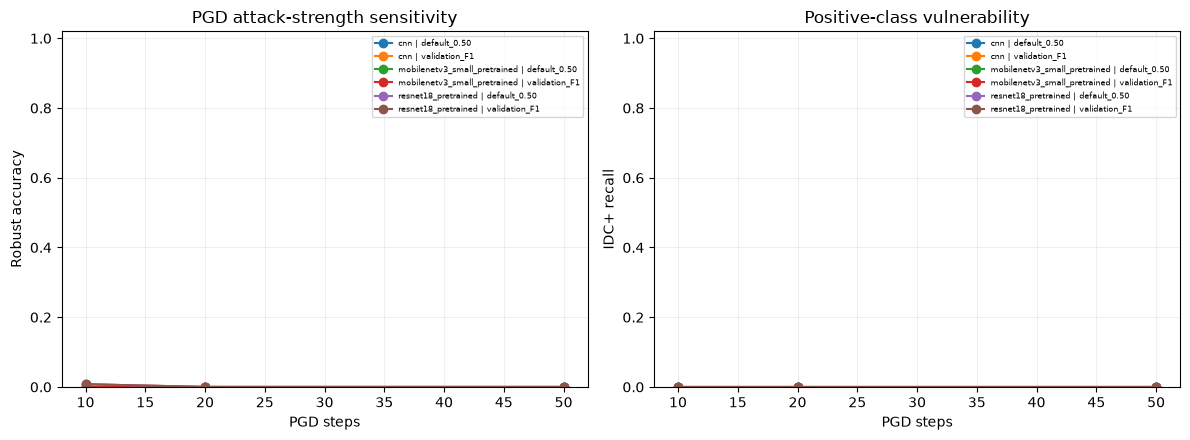

,model,threshold_policy,steps,n,pgd_accuracy,pgd_recall,new_fn_n
0,cnn,default_0.50,10,128,0.000000,0.0,26
1,cnn,validation_F1,10,128,0.007812,0.0,24
2,cnn,default_0.50,20,128,0.000000,0.0,26
3,cnn,validation_F1,20,128,0.000000,0.0,24
4,cnn,default_0.50,50,128,0.000000,0.0,26
5,cnn,validation_F1,50,128,0.000000,0.0,24
6,resnet18_pretrained,default_0.50,10,128,0.007812,0.0,28
7,resnet18_pretrained,validation_F1,10,128,0.007812,0.0,21
8,resnet18_pretrained,default_0.50,20,128,0.000000,0.0,28
9,resnet18_pretrained,validation_F1,20,128,0.000000,0.0,21


In [19]:
# Fixed epsilon, same held-out patches, increasing PGD iterations.
if ANALYSIS_ENABLED and RUN_PGD_CONVERGENCE:
    pgd_conv_subset = choose_subset(manifest, "test", PGD_CONVERGENCE_N, seed=SPLIT_SEED + 921)
    pgd_conv_loader = loader_subset(pgd_conv_subset)
    pgd_convergence_rows = []
    for model_name, model in model_dict.items():
        frozen = frozen_thresholds[model_name]
        for steps in PGD_CONVERGENCE_STEPS:
            torch.manual_seed(TRAIN_SEED + 921)
            pred = attack_predictions(model, pgd_conv_loader, "PGD", PGD_CONVERGENCE_EPS,
                                      steps=int(steps), restarts=PGD_CONVERGENCE_RESTARTS)
            clean = pred[["sample_id", "patient_id", "y", "clean_p"]].rename(columns={"clean_p": "p"})
            attacked = pred[["sample_id", "patient_id", "y", "p"]]
            for policy in ("default_0.50", "validation_F1"):
                threshold = float(frozen[policy])
                current = binary_scores(pred.y, pred.p, threshold)
                original = binary_scores(pred.y, pred.clean_p, threshold)
                y = pred.y.to_numpy(dtype=int)
                clean_ok = (pred.clean_p.to_numpy() >= threshold) == y
                flipped = (pred.p.to_numpy() >= threshold) != y
                clean_tp = (y == 1) & (pred.clean_p.to_numpy() >= threshold)
                new_fn = clean_tp & (pred.p.to_numpy() < threshold)
                delta, low, high = paired_patient_ci(
                    clean, attacked, metric="recall", threshold_a=threshold, threshold_b=threshold)
                pgd_convergence_rows.append({
                    "model": model_name, "threshold_policy": policy, "threshold": threshold,
                    "steps": int(steps), "restarts": int(PGD_CONVERGENCE_RESTARTS),
                    "epsilon": float(PGD_CONVERGENCE_EPS), "n": len(pred),
                    "n_patients": int(pred.patient_id.nunique()),
                    "positive_n": int((y == 1).sum()), "clean_accuracy": original["accuracy"],
                    "pgd_accuracy": current["accuracy"], "clean_recall": original["recall"],
                    "pgd_recall": current["recall"], "pgd_false_negative_rate": current["false_negative_rate"],
                    "new_fn_n": int(new_fn.sum()), "clean_correct_positive_n": int(clean_tp.sum()),
                    "clean_correct_n": int(clean_ok.sum()),
                    "attack_success_given_clean_correct": float(flipped[clean_ok].mean()) if clean_ok.any() else np.nan,
                    "recall_change_pgd_minus_clean": delta,
                    "recall_change_ci95_low": low, "recall_change_ci95_high": high,
                    "max_linf": float(pred.linf.max()),
                })
    pgd_convergence_table = pd.DataFrame(pgd_convergence_rows)
    write_csv(pgd_convergence_table, "PGD_CONVERGENCE_STRENGTH.csv")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for (model_name, policy), group in pgd_convergence_table.groupby(["model", "threshold_policy"]):
        data = group.sort_values("steps")
        axes[0].plot(data.steps, data.pgd_accuracy, marker="o", label=f"{model_name} | {policy}")
        axes[1].plot(data.steps, data.pgd_recall, marker="o", label=f"{model_name} | {policy}")
    axes[0].set(xlabel="PGD steps", ylabel="Robust accuracy", title="PGD attack-strength sensitivity", ylim=(0, 1.02))
    axes[1].set(xlabel="PGD steps", ylabel="IDC+ recall", title="Positive-class vulnerability", ylim=(0, 1.02))
    for ax in axes:
        ax.grid(alpha=0.2)
        ax.legend(fontsize=6)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "PGD_CONVERGENCE_STRENGTH.png", dpi=155)
    plt.show(); plt.close(fig)
    display(pgd_convergence_table[["model", "threshold_policy", "steps", "n", "pgd_accuracy", "pgd_recall", "new_fn_n"]])
else:
    print("[SKIPPED] PGD convergence: disabled or analyses not running.")

### Class-specific attack success

In [20]:
# Compute attack success only among patches classified correctly before attack.
if ANALYSIS_ENABLED:
    classwise_attack_rows=[]
    for key,pred in attack_prediction_frames.items():
        attack_name=("Clean" if "_Clean_" in key else "FGSM" if "_FGSM_" in key else "PGD")
        model_name=next((n for n in model_dict if key.startswith(n+"_")), "unknown")
        epsilon_x255=int(key.rsplit("_",2)[-2])
        y=pred.y.to_numpy(dtype=int)
        clean=(pred.clean_p.to_numpy()>=.5).astype(int)
        attack=(pred.p.to_numpy()>=.5).astype(int)
        initially_correct=clean==y
        positive=y==1
        negative=y==0
        new_fn=positive & (clean==1) & (attack==0)
        eligible_positive=positive & initially_correct
        eligible_all=initially_correct
        classwise_attack_rows.append({
            "model":model_name,"attack":attack_name,"epsilon_x255":epsilon_x255,
            "n":len(y),"n_idc_positive":int(positive.sum()),"n_idc_negative":int(negative.sum()),
            "idc_positive_recall":float((attack[positive]==1).mean()) if positive.any() else np.nan,
            "idc_negative_specificity":float((attack[negative]==0).mean()) if negative.any() else np.nan,
            "attack_induced_new_false_negatives":int(new_fn.sum()),
            "clean_correct_n":int(eligible_all.sum()),
            "clean_correct_positive_n":int(eligible_positive.sum()),
            "attack_success_given_clean_correct":float((attack[eligible_all]!=y[eligible_all]).mean()) if eligible_all.any() else np.nan,
            "new_fn_fraction_given_clean_correct_positive":float(new_fn[eligible_positive].mean()) if eligible_positive.any() else np.nan,
            "positive_attack_evidence":("SUFFICIENT_FOR_PRELIMINARY_ANALYSIS" if eligible_positive.sum() >= MIN_CLEAN_CORRECT_POSITIVE_N
                                        else "INCONCLUSIVE_TOO_FEW_CLEAN_CORRECT_POSITIVES"),
        })
    classwise_attack_table=pd.DataFrame(classwise_attack_rows)
    write_csv(classwise_attack_table,"classwise_attack_robustness.csv")
    display(classwise_attack_table[["model","attack","epsilon_x255","n_idc_positive",
        "idc_positive_recall","idc_negative_specificity","attack_induced_new_false_negatives",
        "clean_correct_positive_n","new_fn_fraction_given_clean_correct_positive","positive_attack_evidence"]])


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\classwise_attack_robustness.csv


,model,attack,epsilon_x255,n_idc_positive,idc_positive_recall,idc_negative_specificity,attack_induced_new_false_negatives,clean_correct_positive_n,new_fn_fraction_given_clean_correct_positive,positive_attack_evidence
0,cnn,Clean,0,13495,0.894850,0.838881,0,12076,0.000000,SUFFICIENT_FOR_PRELIMINARY_ANALYSIS
1,cnn,FGSM,2,13495,0.290848,0.292417,8151,12076,0.674975,SUFFICIENT_FOR_PRELIMINARY_ANALYSIS
2,cnn,PGD,2,13495,0.100185,0.150235,10724,12076,0.888042,SUFFICIENT_FOR_PRELIMINARY_ANALYSIS
3,cnn,FGSM,4,13495,0.117747,0.104703,10539,12076,0.872723,SUFFICIENT_FOR_PRELIMINARY_ANALYSIS
4,cnn,PGD,4,13495,0.004372,0.042935,12017,12076,0.995114,SUFFICIENT_FOR_PRELIMINARY_ANALYSIS
5,cnn,FGSM,8,13495,0.264617,0.048601,8836,12076,0.731699,SUFFICIENT_FOR_PRELIMINARY_ANALYSIS
6,cnn,PGD,8,13495,0.000000,0.012249,12076,12076,1.000000,SUFFICIENT_FOR_PRELIMINARY_ANALYSIS
7,resnet18_pretrained,Clean,0,13495,0.912116,0.846854,0,12309,0.000000,SUFFICIENT_FOR_PRELIMINARY_ANALYSIS
8,resnet18_pretrained,FGSM,2,13495,0.052093,0.104729,11606,12309,0.942887,SUFFICIENT_FOR_PRELIMINARY_ANALYSIS
9,resnet18_pretrained,PGD,2,13495,0.000000,0.001574,12309,12309,1.000000,SUFFICIENT_FOR_PRELIMINARY_ANALYSIS


### Newly induced false negatives

In [21]:
# Track newly induced false negatives rather than all existing errors.
if ANALYSIS_ENABLED:
    if RUN_FN_FLIP_ANALYSIS:
        flip_rows=[]; flip_examples=[]
        for row in attack_results.itertuples():
            if row.attack == "Clean": continue
            base_key=f"{row.model}_Clean_0_255"
            attacked_key=f"{row.model}_{row.attack}_{round(row.epsilon*255)}_255"
            if base_key not in attack_prediction_frames or attacked_key not in attack_prediction_frames:
                continue
            base=attack_prediction_frames[base_key][["sample_id","patient_id","y","p"]].rename(columns={"p":"p_clean"})
            adversarial=attack_prediction_frames[attacked_key][["sample_id","y","p"]].rename(columns={"p":"p_adv"})
            joined=base.merge(adversarial.drop(columns=["y"]),on="sample_id",validate="one_to_one")
            if len(joined)!=len(base) or len(joined)!=len(adversarial):
                raise RuntimeError("Attack flip comparison requires identical sample IDs")
            joined["clean_correct"]=((joined.p_clean>=.5).astype(int)==joined.y)
            joined["adv_correct"]=((joined.p_adv>=.5).astype(int)==joined.y)
            joined["new_false_negative"]=(joined.y.eq(1) & joined.p_clean.ge(.5) & joined.p_adv.lt(.5))
            joined["preexisting_false_negative"]=(joined.y.eq(1) & joined.p_clean.lt(.5))
            joined["new_false_positive"]=(joined.y.eq(0) & joined.p_clean.lt(.5) & joined.p_adv.ge(.5))
            eligible=(joined.y.eq(1)&joined.p_clean.ge(.5)).sum()
            flip_rows.append({"model":row.model,"attack":row.attack,"epsilon":row.epsilon,
                "n":len(joined),"clean_correct_n":int(joined.clean_correct.sum()),
                "newly_wrong_n":int((joined.clean_correct&~joined.adv_correct).sum()),
                "recovered_n":int((~joined.clean_correct&joined.adv_correct).sum()),
                "positive_clean_correct_n":int(eligible),
                "new_false_negative_n":int(joined.new_false_negative.sum()),
                "new_fn_rate_given_clean_true_positive":(joined.new_false_negative.sum()/eligible if eligible else float("nan")),
                "preexisting_false_negative_n":int(joined.preexisting_false_negative.sum()),
                "new_false_positive_n":int(joined.new_false_positive.sum())})
            if len(flip_examples)<1000:
                ex=joined[joined.new_false_negative].head(40).copy()
                ex["model"]=row.model;ex["attack"]=row.attack;ex["epsilon"]=row.epsilon
                flip_examples.append(ex)
        flips=pd.DataFrame(flip_rows)
        if len(flips):
            write_csv(flips,"attack_induced_false_negative_flips.csv")
            display(flips)
        if flip_examples:
            write_csv(pd.concat(flip_examples,ignore_index=True),"attack_induced_false_negative_examples.csv")
    else:
        print("Attack-induced error flips: not evaluated")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\attack_induced_false_negative_flips.csv


,model,attack,epsilon,n,clean_correct_n,newly_wrong_n,recovered_n,positive_clean_correct_n,new_false_negative_n,new_fn_rate_given_clean_true_positive,preexisting_false_negative_n,new_false_positive_n
0,cnn,FGSM,0.007843,51622,44060,28986,0,12076,8151,0.674975,1419,20835
1,cnn,PGD,0.007843,51622,44060,36980,0,12076,10724,0.888042,1419,26256
2,cnn,FGSM,0.015686,51622,44060,38531,52,12076,10539,0.872723,1419,27992
3,cnn,PGD,0.015686,51622,44060,42364,0,12076,12017,0.995114,1419,30347
4,cnn,FGSM,0.031373,51622,44060,38967,331,12076,8836,0.731699,1419,30131
5,cnn,PGD,0.031373,51622,44060,43593,0,12076,12076,1.000000,1419,31517
6,resnet18_pretrained,FGSM,0.007843,51622,44597,39901,0,12309,11606,0.942887,1186,28295
7,resnet18_pretrained,PGD,0.007843,51622,44597,44537,0,12309,12309,1.000000,1186,32228
8,resnet18_pretrained,FGSM,0.015686,51622,44597,40651,0,12309,11543,0.937769,1186,29108
9,resnet18_pretrained,PGD,0.015686,51622,44597,44585,0,12309,12309,1.000000,1186,32276


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\attack_induced_false_negative_examples.csv


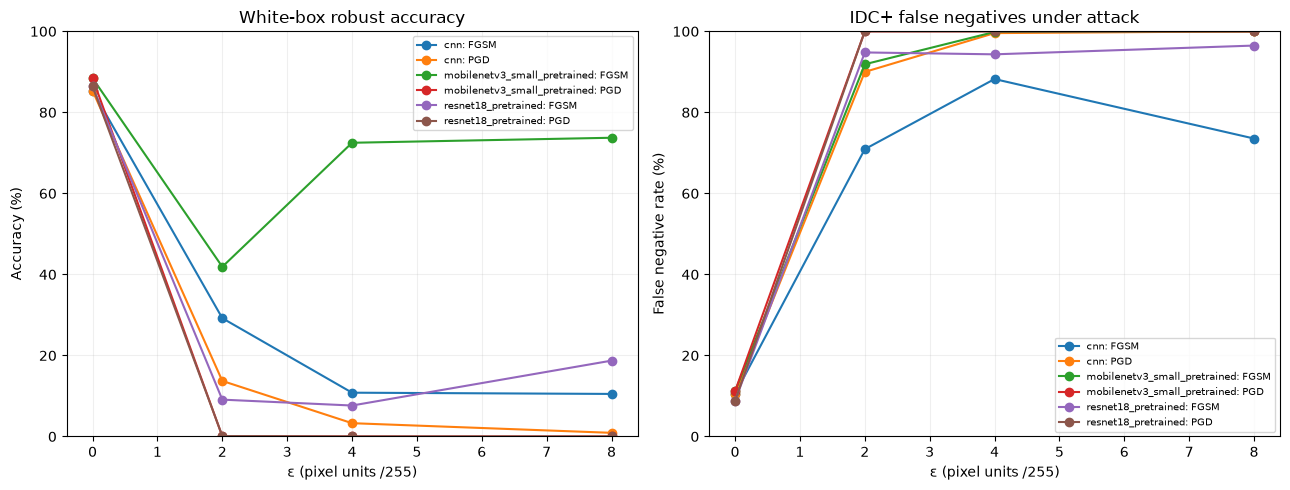

In [22]:
if ANALYSIS_ENABLED:
    fig,axs=plt.subplots(1,2,figsize=(13,5))
    for (name,attack),g in attack_results.groupby(["model","attack"]):
        if attack=="Clean":continue
        zero=attack_results[(attack_results.model==name)&(attack_results.attack=="Clean")].copy()
        frame=pd.concat([zero,g]).sort_values("epsilon")
        axs[0].plot(frame.epsilon*255,100*frame.accuracy,marker="o",label=f"{name}: {attack}")
        axs[1].plot(frame.epsilon*255,100*frame.false_negative_rate,marker="o",label=f"{name}: {attack}")
    axs[0].set(xlabel="ε (pixel units /255)",ylabel="Accuracy (%)",title="White-box robust accuracy")
    axs[1].set(xlabel="ε (pixel units /255)",ylabel="False negative rate (%)",title="IDC+ false negatives under attack")
    for ax in axs:ax.set_ylim(0,100);ax.grid(alpha=.2);ax.legend(fontsize=7)
    fig.tight_layout();fig.savefig(RESULTS_DIR/"attack_epsilon_accuracy_FNR.png",dpi=170);plt.show();plt.close(fig)


In [23]:
# Assess prediction confidence and calibration after perturbation.
if ANALYSIS_ENABLED:
    attack_calibration_rows=[]; attack_threshold_rows=[]
    if RUN_ATTACK_CALIBRATION:
        for model_name in model_dict:
            temperature=temperature_fit(baseline_predictions[model_name]["val"]) if RUN_CALIBRATION else 1.0
            val=baseline_predictions[model_name]["val"]
            thresholds={"fixed_0p5":0.5,
                        "validation_F1":float(threshold_table[(threshold_table.model==model_name)&
                            (threshold_table.policy=="validation_F1")].threshold.iloc[0]),
                        "validation_recall_target":float(threshold_table[(threshold_table.model==model_name)&
                            (threshold_table.policy.str.startswith("validation_recall_at_least"))].threshold.iloc[0])}
            for key,pred in attack_prediction_frames.items():
                if not key.startswith(model_name+"_"): continue
                eps_tag=key.split("_")[-2]
                attack="Clean" if "_Clean_" in key else ("FGSM" if "_FGSM_" in key else "PGD")
                for variant,probs in (("raw",pred.p.to_numpy()),
                                      ("validation_temp_scaled",temperature_apply(pred.p,temperature))):
                    y=pred.y.to_numpy(); predicted=probs>=0.5
                    error=predicted!=y
                    confidence=np.maximum(probs,1-probs)
                    fn=(y==1)&(~predicted)
                    attack_calibration_rows.append({
                        "model":model_name,"attack":attack,"epsilon_x255":int(eps_tag),
                        "calibration":variant,"temperature":temperature if variant!="raw" else 1.0,
                        "n":len(y),"ece":ece(y,probs),"brier":brier_score_loss(y,probs),
                        "accuracy":float((~error).mean()),
                        "wrong_high_confidence_0p9_n":int((error&(confidence>=0.9)).sum()),
                        "false_negative_n":int(fn.sum()),
                        "high_confidence_false_negative_0p9_n":int((fn&(confidence>=0.9)).sum()),
                        "mean_confidence_of_errors":float(confidence[error].mean()) if error.any() else np.nan})
                for policy,t in thresholds.items():
                    attack_threshold_rows.append({"model":model_name,"attack":attack,
                        "epsilon_x255":int(eps_tag),"threshold_policy":policy,
                        "threshold":t,**binary_scores(pred.y,pred.p,t)})
        adversarial_calibration_table=pd.DataFrame(attack_calibration_rows)
        write_csv(adversarial_calibration_table,"adversarial_calibration_and_confident_errors.csv")
        write_csv(pd.DataFrame(attack_threshold_rows),"attack_validation_threshold_policies.csv")
        display(adversarial_calibration_table[["model","attack","epsilon_x255","calibration","ece",
                                              "brier","false_negative_n","high_confidence_false_negative_0p9_n"]])
    else:
        adversarial_calibration_table=pd.DataFrame()
        print("Adversarial calibration not evaluated")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\adversarial_calibration_and_confident_errors.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\attack_validation_threshold_policies.csv


,model,attack,epsilon_x255,calibration,ece,brier,false_negative_n,high_confidence_false_negative_0p9_n
0,cnn,Clean,0,raw,0.111307,0.106956,1419,199
1,cnn,Clean,0,validation_temp_scaled,0.119070,0.106584,1419,117
2,cnn,FGSM,2,raw,0.526602,0.524834,9570,3471
3,cnn,FGSM,2,validation_temp_scaled,0.501243,0.496659,9570,2583
4,cnn,PGD,2,raw,0.745677,0.708915,12143,8228
5,cnn,PGD,2,validation_temp_scaled,0.722777,0.673903,12143,7108
6,cnn,FGSM,4,raw,0.758621,0.726381,11906,4745
7,cnn,FGSM,4,validation_temp_scaled,0.735903,0.693390,11906,3568
8,cnn,PGD,4,raw,0.947183,0.937424,13436,13041
9,cnn,PGD,4,validation_temp_scaled,0.939348,0.925457,13436,12899


### Paired patient-bootstrap attack intervals

In [24]:
# Paired cluster bootstrap uses each model's validation-selected decision rule.
if ANALYSIS_ENABLED:
    paired_attack_rows = []
    if RUN_PAIRED_BOOTSTRAP:
        for model_name in model_dict:
            baseline_key = f"{model_name}_Clean_0_255"
            if baseline_key not in attack_prediction_frames:
                continue
            ref = attack_prediction_frames[baseline_key]
            for key, attacked in attack_prediction_frames.items():
                if not key.startswith(model_name + "_") or key == baseline_key:
                    continue
                for policy in ("default_0.50", "validation_F1"):
                    threshold = float(frozen_thresholds[model_name][policy])
                    for metric in ("accuracy", "recall"):
                        delta, low, high = paired_patient_ci(
                            ref, attacked, metric=metric, threshold_a=threshold, threshold_b=threshold)
                        paired_attack_rows.append({"model": model_name, "attack_result": key,
                            "threshold_policy": policy, "threshold": threshold,
                            "metric": metric, "attack_minus_clean": delta,
                            "lower_95": low, "upper_95": high,
                            "n_patches": len(ref), "n_patients": ref.patient_id.nunique()})
        if paired_attack_rows:
            paired_attack_table = pd.DataFrame(paired_attack_rows)
            write_csv(paired_attack_table, "paired_patient_CI_attack_minus_clean.csv")
            display(paired_attack_table.head(20))
        else:
            print("No paired attack comparisons were available.")
    architecture_rows = []
    if RUN_PAIRED_BOOTSTRAP and len(model_dict) > 1 and "cnn" in model_dict:
        reference = baseline_predictions["cnn"]["test"]
        for name in model_dict:
            if name == "cnn":
                continue
            candidate = baseline_predictions[name]["test"]
            for policy in ("default_0.50", "validation_F1"):
                threshold_a = float(frozen_thresholds["cnn"][policy])
                threshold_b = float(frozen_thresholds[name][policy])
                for metric in ("accuracy", "recall"):
                    delta, low, high = paired_patient_ci(reference, candidate, metric=metric,
                        threshold_a=threshold_a, threshold_b=threshold_b)
                    architecture_rows.append({"reference": "cnn", "comparison": name,
                        "threshold_policy": policy, "reference_threshold": threshold_a,
                        "comparison_threshold": threshold_b, "metric": metric,
                        "difference_vs_cnn": delta, "lower_95": low, "upper_95": high,
                        "n_patches": len(reference), "n_patients": reference.patient_id.nunique()})
        architecture_comparison = pd.DataFrame(architecture_rows)
        write_csv(architecture_comparison, "paired_patient_CI_model_comparison.csv")
        display(architecture_comparison)

Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\paired_patient_CI_attack_minus_clean.csv


,model,attack_result,threshold_policy,threshold,metric,attack_minus_clean,lower_95,upper_95,n_patches,n_patients
0,cnn,cnn_FGSM_2_255,default_0.50,0.50000,accuracy,-0.561505,-0.601939,-0.520190,51622,42
1,cnn,cnn_FGSM_2_255,default_0.50,0.50000,recall,-0.604001,-0.668936,-0.537505,51622,42
2,cnn,cnn_FGSM_2_255,validation_F1,0.72954,accuracy,-0.501511,-0.555780,-0.446211,51622,42
3,cnn,cnn_FGSM_2_255,validation_F1,0.72954,recall,-0.683809,-0.727231,-0.631449,51622,42
4,cnn,cnn_PGD_2_255,default_0.50,0.50000,accuracy,-0.716361,-0.749530,-0.683261,51622,42
5,cnn,cnn_PGD_2_255,default_0.50,0.50000,recall,-0.794665,-0.836565,-0.739894,51622,42
6,cnn,cnn_PGD_2_255,validation_F1,0.72954,accuracy,-0.666150,-0.716447,-0.617682,51622,42
7,cnn,cnn_PGD_2_255,validation_F1,0.72954,recall,-0.755243,-0.799981,-0.700840,51622,42
8,cnn,cnn_FGSM_4_255,default_0.50,0.50000,accuracy,-0.745399,-0.775728,-0.713223,51622,42
9,cnn,cnn_FGSM_4_255,default_0.50,0.50000,recall,-0.777103,-0.818186,-0.724890,51622,42


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\paired_patient_CI_model_comparison.csv


,reference,comparison,threshold_policy,reference_threshold,comparison_threshold,metric,difference_vs_cnn,lower_95,upper_95,n_patches,n_patients
0,cnn,resnet18_pretrained,default_0.50,0.50000,0.500000,accuracy,0.010383,-0.005823,0.027154,51622,42
1,cnn,resnet18_pretrained,default_0.50,0.50000,0.500000,recall,0.017266,-0.004275,0.041252,51622,42
2,cnn,resnet18_pretrained,validation_F1,0.72954,0.679640,accuracy,0.014606,0.002979,0.028669,51622,42
3,cnn,resnet18_pretrained,validation_F1,0.72954,0.679640,recall,0.064542,0.033500,0.099496,51622,42
4,cnn,mobilenetv3_small_pretrained,default_0.50,0.50000,0.500000,accuracy,0.030859,0.017995,0.044462,51622,42
5,cnn,mobilenetv3_small_pretrained,default_0.50,0.50000,0.500000,recall,-0.006595,-0.025053,0.010745,51622,42
6,cnn,mobilenetv3_small_pretrained,validation_F1,0.72954,0.595808,accuracy,0.012843,0.003512,0.024657,51622,42
7,cnn,mobilenetv3_small_pretrained,validation_F1,0.72954,0.595808,recall,0.075880,0.051612,0.105054,51622,42


### Cross-model attack transferability

Cross-model transferability: models ['cnn', 'resnet18_pretrained', 'mobilenetv3_small_pretrained'] patches 256
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\cross_model_attack_transferability.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\cross_model_transferability_patch_predictions.csv


,source_model,target_model,attack,n,clean_accuracy,adversarial_accuracy,accuracy_drop,new_false_negative_n
0,cnn,cnn,FGSM,256,0.906250,0.089844,0.816406,48
1,cnn,resnet18_pretrained,FGSM,256,0.878906,0.468750,0.410156,55
2,cnn,mobilenetv3_small_pretrained,FGSM,256,0.894531,0.738281,0.156250,57
3,cnn,cnn,PGD,256,0.906250,0.011719,0.894531,52
4,cnn,resnet18_pretrained,PGD,256,0.878906,0.269531,0.609375,54
5,cnn,mobilenetv3_small_pretrained,PGD,256,0.894531,0.742188,0.152344,56
6,resnet18_pretrained,cnn,FGSM,256,0.906250,0.578125,0.328125,4
7,resnet18_pretrained,resnet18_pretrained,FGSM,256,0.878906,0.371094,0.507812,55
8,resnet18_pretrained,mobilenetv3_small_pretrained,FGSM,256,0.894531,0.746094,0.148438,54
9,resnet18_pretrained,cnn,PGD,256,0.906250,0.707031,0.199219,22


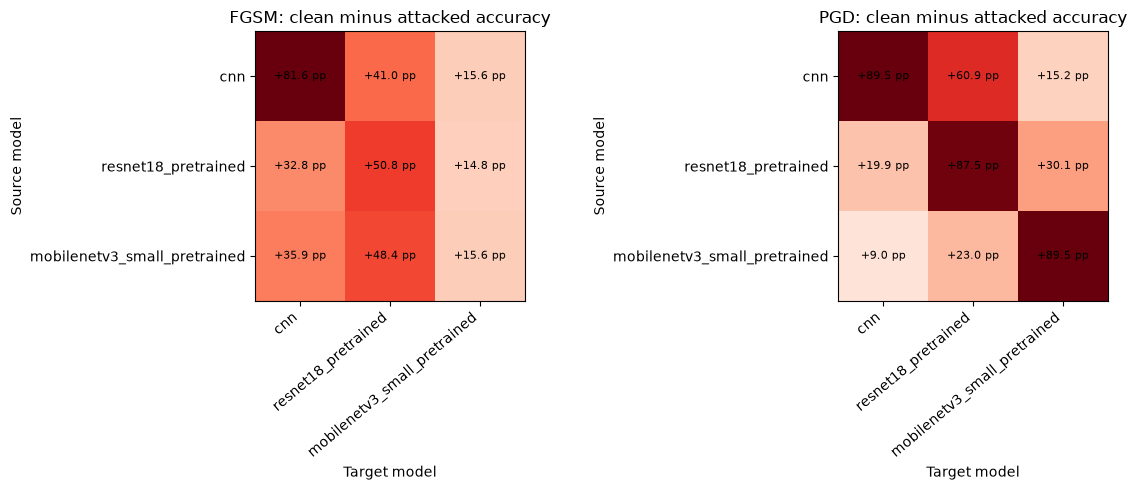

In [25]:
# Measure whether an attack created for one model transfers to other models.
if ANALYSIS_ENABLED:
    if RUN_TRANSFERABILITY and len(model_dict) >= 2:
        transfer_subset=choose_subset(manifest,"test",TRANSFER_ATTACK_N,seed=SPLIT_SEED+19)
        transfer_loader=loader_subset(transfer_subset,batch=ATTACK_BATCH_SIZE)
        transfer_rows=[]; transfer_details=[]
        eps=float(DEFENSE_EPS)
        print("Cross-model transferability: models",list(model_dict),"patches",len(transfer_subset),flush=True)
        for source_name, source_model in model_dict.items():
            source_model.eval()
            for method in TRANSFER_ATTACK_METHODS:
                observed={target:[] for target in model_dict}
                linf_values=[]
                for x,y,ids in transfer_loader:
                    x=x.to(DEVICE); y=y.to(DEVICE)
                    with torch.enable_grad():
                        if method=="FGSM": xa=fgsm_attack(source_model,x,y,eps)
                        elif method=="PGD": xa=pgd_attack(source_model,x,y,eps,TRANSFER_PGD_STEPS,1)
                        else: raise ValueError("Unsupported transfer method "+str(method))
                    observed_linf=(xa-x).flatten(1).abs().amax(1)
                    assert float(observed_linf.max())<=eps+1e-5
                    linf_values.extend(observed_linf.detach().cpu().tolist())
                    with torch.no_grad():
                        for target_name,target_model in model_dict.items():
                            target_model.eval()
                            pc=torch.softmax(target_model(x),dim=1)[:,1].cpu().tolist()
                            pa=torch.softmax(target_model(xa),dim=1)[:,1].cpu().tolist()
                            observed[target_name].extend(zip(ids.tolist(),y.cpu().tolist(),pc,pa))
                for target_name,obs in observed.items():
                    frame=pd.DataFrame(obs,columns=["sample_id","y","p_clean","p_adv"])
                    frame=frame.merge(transfer_subset[["sample_id","patient_id"]],on="sample_id",validate="one_to_one")
                    if len(frame)!=len(transfer_subset):
                        raise RuntimeError("Missing transferability test observations")
                    decision_threshold=float(frozen_thresholds[target_name]["validation_F1"])
                    clean=binary_scores(frame.y,frame.p_clean,decision_threshold)
                    attacked=binary_scores(frame.y,frame.p_adv,decision_threshold)
                    eligible=((frame.p_clean>=decision_threshold).astype(int)==frame.y)
                    adv_wrong=((frame.p_adv>=decision_threshold).astype(int)!=frame.y)
                    true_pos=frame.y.eq(1)&frame.p_clean.ge(decision_threshold)
                    new_fn=true_pos&frame.p_adv.lt(decision_threshold)
                    paired={"accuracy_ci_low":float("nan"),"accuracy_ci_high":float("nan"),
                            "recall_ci_low":float("nan"),"recall_ci_high":float("nan")}
                    if RUN_PAIRED_BOOTSTRAP:
                        a=frame[["sample_id","patient_id","y","p_clean"]].rename(columns={"p_clean":"p"})
                        b=frame[["sample_id","patient_id","y","p_adv"]].rename(columns={"p_adv":"p"})
                        _,low,high=paired_patient_ci(a,b,"accuracy",threshold_a=decision_threshold)
                        paired.update(accuracy_ci_low=low,accuracy_ci_high=high)
                        _,low,high=paired_patient_ci(a,b,"recall",threshold_a=decision_threshold)
                        paired.update(recall_ci_low=low,recall_ci_high=high)
                    transfer_rows.append({"source_model":source_name,"target_model":target_name,
                        "pair_type":"white_box" if source_name==target_name else "transfer",
                        "threshold_policy":"validation_F1", "threshold":decision_threshold,
                        "attack":method,"epsilon":eps,"n":len(frame),
                        "n_patients":int(frame.patient_id.nunique()),
                        "clean_accuracy":clean["accuracy"],"adversarial_accuracy":attacked["accuracy"],
                        "accuracy_drop":clean["accuracy"]-attacked["accuracy"],
                        "clean_recall":clean["recall"],"adversarial_recall":attacked["recall"],
                        "recall_drop":clean["recall"]-attacked["recall"],
                        "eligible_clean_correct_n":int(eligible.sum()),
                        "attack_success_given_clean_correct":float(adv_wrong[eligible].mean()) if eligible.any() else float("nan"),
                        "clean_true_positive_n":int(true_pos.sum()),
                        "new_false_negative_n":int(new_fn.sum()),
                        "mean_linf":float(np.mean(linf_values)),"max_linf":float(np.max(linf_values)),
                        **paired})
                    if RUN_SAVE_ATTACK_PREDICTIONS:
                        f=frame.copy();f["source_model"]=source_name;f["target_model"]=target_name;f["attack"]=method
                        transfer_details.append(f)
        transfer_table=pd.DataFrame(transfer_rows)
        write_csv(transfer_table,"cross_model_attack_transferability.csv")
        if transfer_details:
            write_csv(pd.concat(transfer_details,ignore_index=True),"cross_model_transferability_patch_predictions.csv")
        display(transfer_table[["source_model","target_model","attack","n","clean_accuracy",
            "adversarial_accuracy","accuracy_drop","new_false_negative_n"]])
        fig,axes=plt.subplots(1,len(TRANSFER_ATTACK_METHODS),figsize=(6*len(TRANSFER_ATTACK_METHODS),5),squeeze=False)
        names=list(model_dict)
        for ax,method in zip(axes[0],TRANSFER_ATTACK_METHODS):
            sub=transfer_table[transfer_table.attack==method]
            grid=sub.pivot(index="source_model",columns="target_model",values="accuracy_drop").reindex(index=names,columns=names)
            ax.imshow(grid.values.astype(float),cmap="Reds",vmin=0,vmax=max(.01,float(np.nanmax(grid.values))))
            ax.set_xticks(range(len(names)),names,rotation=40,ha="right")
            ax.set_yticks(range(len(names)),names)
            ax.set(title=f"{method}: clean minus attacked accuracy",xlabel="Target model",ylabel="Source model")
            for i in range(len(names)):
                for j in range(len(names)):
                    ax.text(j,i,f"{grid.iloc[i,j]*100:+.1f} pp",ha="center",va="center",fontsize=8)
        fig.tight_layout();fig.savefig(RESULTS_DIR/"cross_model_attack_transferability_heatmap.png",dpi=170)
        plt.show();plt.close(fig)
    else:
        print("Cross-model transferability NOT EVALUATED (requires RUN_TRANSFERABILITY=True and >=2 trained models).")


## 8. Adversarial fine-tuning and defense evaluation

Defense checkpoint reused: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\checkpoints\defense_cnn_clean_control_4885f99399b57c96.pt
Defense checkpoint reused: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\checkpoints\defense_cnn_fgsm_training_3d395e8b2dc6bb2a.pt
Defense checkpoint reused: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\checkpoints\defense_cnn_pgd_training_d9cb4dac3c631908.pt
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\patch_defense_baseline_cnn_Clean.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\patch_defense_baseline_cnn_FGSM.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\patch_defense_baseline_cnn_PGD.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\patch_def

,model,attack,accuracy,recall,false_negative_rate,success_given_clean_correct
0,baseline_cnn,Clean,0.853512,0.894850,0.105150,0.000000
1,baseline_cnn,FGSM,0.105071,0.264617,0.735383,0.884408
2,baseline_cnn,PGD,0.009066,0.000000,1.000000,0.989378
3,clean_control,Clean,0.858878,0.887143,0.112857,0.000000
4,clean_control,FGSM,0.084363,0.173768,0.826232,0.909872
5,clean_control,PGD,0.006780,0.000000,1.000000,0.992106
6,fgsm_training,Clean,0.859808,0.893738,0.106262,0.000000
7,fgsm_training,FGSM,0.992368,0.997036,0.002964,0.001735
8,fgsm_training,PGD,0.002286,0.000000,1.000000,0.997341
9,pgd_training,Clean,0.790012,0.776658,0.223342,0.000000


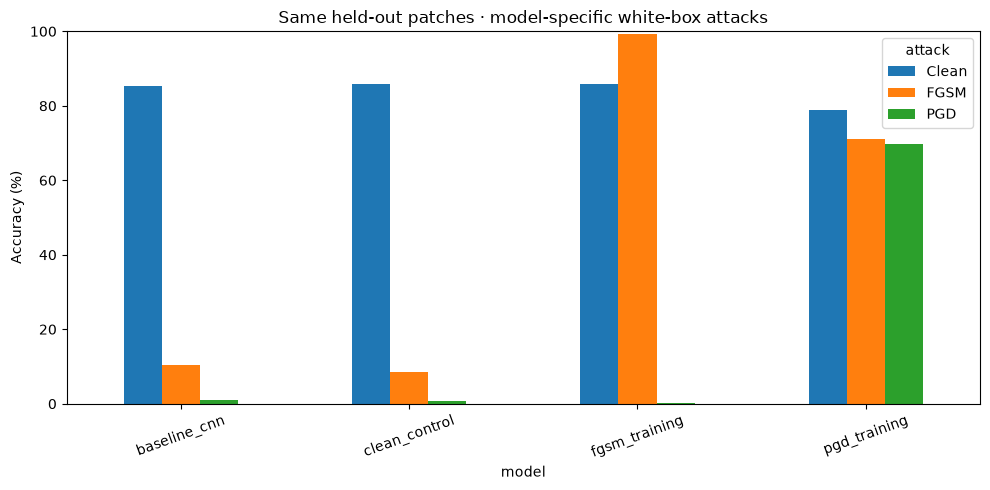

In [26]:
# Use matched evaluation data to compare clean, FGSM, and PGD fine-tuning.
if ANALYSIS_ENABLED:
    def defense_finetune(kind):
        assert kind in ("clean_control","fgsm_training","pgd_training")
        parent=checkpoint_paths["cnn"]
        cfg={"manifest_id":MANIFEST_ID,"kind":kind,"parent":parent.name,
             "seed":TRAIN_SEED,"epochs":DEFENSE_EPOCHS,"lr":1e-4,"epsilon":DEFENSE_EPS,
             "pgd_steps_train":3 if MODE=="quick" else 7,
             "clean_fraction":.5,"image_size":IMAGE_SIZE,"batch_size":BATCH_SIZE,
             "experiment_revision":EXPERIMENT_REVISION,
             "torch_version":str(torch.__version__),"torchvision_version":__import__("torchvision").__version__}
        path=CHECKPOINT_DIR/f"defense_cnn_{kind}_{key_hash(cfg)}.pt"
        if REUSE_CHECKPOINTS:
            for folder in CHECKPOINT_SEARCH_DIRS:
                candidate=folder/path.name
                if candidate.exists():
                    ck=torch.load(candidate,map_location="cpu",weights_only=True)
                    if ck.get("config")==cfg:
                        print("Defense checkpoint reused:",candidate)
                        return load_ckpt(candidate,"cnn")
        if TRAIN_POLICY == "reuse_only":
            raise FileNotFoundError(f"Missing compatible defense checkpoint for {kind}. "
                                    "Choose a training profile to create defense weights deliberately.")
        if DEVICE.type == "cpu" and MODE == "full" and not ALLOW_FULL_CPU_TRAINING:
            raise RuntimeError("Full CPU defense training blocked until explicitly approved")
        seed_everything(TRAIN_SEED)
        model=load_ckpt(parent,"cnn")
        opt=torch.optim.AdamW(model.parameters(),lr=1e-4,weight_decay=1e-4)
        tr=loader_for(manifest,"train",train=True)
        best=-1;hist=[]
        for ep in range(1,DEFENSE_EPOCHS+1):
            if DEVICE.type=="cuda": torch.cuda.synchronize()
            epoch_start=time.perf_counter()
            model.train();total=0
            for x,y,_ in tr:
                x=x.to(DEVICE);y=y.to(DEVICE)
                if kind!="clean_control":
                    model.eval()
                    with torch.enable_grad():
                        adv=(fgsm_attack(model,x,y,DEFENSE_EPS) if kind=="fgsm_training" else
                             pgd_attack(model,x,y,DEFENSE_EPS,cfg["pgd_steps_train"],restarts=1))
                    model.train()
                opt.zero_grad(set_to_none=True)
                if kind=="clean_control": loss=F.cross_entropy(model(x),y)
                else:loss=.5*F.cross_entropy(model(x),y)+.5*F.cross_entropy(model(adv),y)
                loss.backward();opt.step();total+=float(loss.item())*len(y)
            val=predict_frame(model,val_loader)
            score=binary_scores(val.y,val.p)["roc_auc"]
            if DEVICE.type=="cuda": torch.cuda.synchronize()
            elapsed_seconds=time.perf_counter()-epoch_start
            hist.append({"epoch":ep,"loss":total/len(tr.dataset),"val_auc":score,
                         "training_seconds_including_validation":elapsed_seconds})
            print(f"{kind}: epoch {ep}/{DEFENSE_EPOCHS}: val_AUC={score:.4f}")
            if score>best:
                best=score
                torch.save({"state_dict":model.state_dict(),"config":cfg,"epoch":ep},path)
        write_csv(pd.DataFrame(hist),f"defense_history_{kind}_{key_hash(cfg)}.csv")
        return load_ckpt(path,"cnn")

    defense_models={"baseline_cnn":model_dict["cnn"]}
    if RUN_DEFENSE:
        for defense in ("clean_control","fgsm_training","pgd_training"):
            defense_models[defense]=defense_finetune(defense)
        defense_records=[]; defense_pred_frames={}
        for name,model in defense_models.items():
            for attack_name in ("Clean","FGSM","PGD"):
                eps=0 if attack_name=="Clean" else DEFENSE_EPS
                pr=attack_predictions(model,attack_loader,attack_name,eps)
                defense_pred_frames[(name,attack_name)]=pr
                if RUN_SAVE_ATTACK_PREDICTIONS:
                    write_csv(pr,f"patch_defense_{name}_{attack_name}.csv")
                defense_records.append(attack_summary(pr,name,attack_name,eps,
                          PGD_STEPS if attack_name=="PGD" else (1 if attack_name=="FGSM" else 0),
                          PGD_RESTARTS if attack_name=="PGD" else 0))
        defense_results=pd.DataFrame(defense_records)
        write_csv(defense_results,"defense_clean_vs_adversarial_training.csv")
        display(defense_results[["model","attack","accuracy","recall","false_negative_rate","success_given_clean_correct"]])
        fig,ax=plt.subplots(figsize=(10,5))
        pivot=defense_results.pivot(index="model",columns="attack",values="accuracy")
        (pivot*100).plot.bar(ax=ax)
        ax.set(ylabel="Accuracy (%)",title="Same held-out patches · model-specific white-box attacks",ylim=(0,100))
        ax.tick_params(axis="x",rotation=20);fig.tight_layout()
        fig.savefig(RESULTS_DIR/"defense_tradeoff.png",dpi=170);plt.show();plt.close(fig)
    else:
        defense_pred_frames={}
        defense_results=pd.DataFrame()
        print("NOT EVALUATED — defenses disabled in configuration")


### Validation-based defense thresholds

In [27]:
# Choose each defense model’s threshold from validation data only.
if ANALYSIS_ENABLED and RUN_DEFENSE:
    defense_policy_rows=[]
    defense_frozen_thresholds = {}
    for model_name,model in defense_models.items():
        if model_name=="baseline_cnn":
            validation=baseline_predictions["cnn"]["val"]
        else:
            validation=predict_frame(model,val_loader)
        thresholds=validation_thresholds(validation)
        defense_frozen_thresholds[model_name]=thresholds
        for attack_method in ("Clean","FGSM","PGD"):
            pr=defense_pred_frames[(model_name,attack_method)]
            for policy,thr in thresholds.items():
                y=pr.y.to_numpy(dtype=int)
                true_pos=(y==1)
                prior_correct_pos=true_pos&(pr.clean_p.to_numpy()>=thr)
                new_fn=prior_correct_pos&(pr.p.to_numpy()<thr)
                defense_policy_rows.append({"model":model_name,"attack":attack_method,
                    "threshold_policy":policy,"threshold":thr,
                    "clean_correct_positive_n":int(prior_correct_pos.sum()),
                    "new_false_negative_n":int(new_fn.sum()),
                    "eligible_positive_support":bool(prior_correct_pos.sum()>=MIN_CLEAN_CORRECT_POSITIVE_N),
                    **binary_scores(y,pr.p.to_numpy(),thr)})
    defense_policy_df=pd.DataFrame(defense_policy_rows)
    write_csv(defense_policy_df,"defense_validation_threshold_classwise.csv")
    display(defense_policy_df[["model","attack","threshold_policy","accuracy","recall","fn","clean_correct_positive_n"]])
else:
    print("[NOT RUN] Defense threshold comparison requires RUN_DEFENSE=True.")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\defense_validation_threshold_classwise.csv


,model,attack,threshold_policy,accuracy,recall,fn,clean_correct_positive_n
0,baseline_cnn,Clean,default_0.50,0.853512,0.894850,1419,12076
1,baseline_cnn,Clean,validation_F1,0.879354,0.786217,2885,10610
2,baseline_cnn,Clean,validation_recall_at_least_90%,0.807040,0.941386,791,12704
3,baseline_cnn,FGSM,default_0.50,0.105071,0.264617,9924,12076
4,baseline_cnn,FGSM,validation_F1,0.096354,0.105002,12078,10610
5,baseline_cnn,FGSM,validation_recall_at_least_90%,0.152241,0.494405,6823,12704
6,baseline_cnn,PGD,default_0.50,0.009066,0.000000,13495,12076
7,baseline_cnn,PGD,validation_F1,0.013948,0.000000,13495,10610
8,baseline_cnn,PGD,validation_recall_at_least_90%,0.003971,0.000519,13488,12704
9,clean_control,Clean,default_0.50,0.858878,0.887143,1523,11972


In [28]:
# Flag defense comparisons when the clean model fails to detect IDC-positive patches.
if ANALYSIS_ENABLED:
    defense_quality_rows=[]
    if RUN_DEFENSE:
        for model_name in defense_models:
            clean_pred=defense_pred_frames[(model_name,"Clean")]
            pos=clean_pred[clean_pred.y==1]
            clean_correct_pos=int((pos.clean_p>=.5).sum())
            for attack_name in ("Clean", "FGSM", "PGD"):
                current=defense_pred_frames[(model_name,attack_name)]
                positive=current[current.y==1]
                pos_recall=float((positive.p>=.5).mean()) if len(positive) else np.nan
                support_ok=bool(clean_correct_pos >= MIN_CLEAN_CORRECT_POSITIVE_N)
                viable=bool(support_ok and len(positive)>0 and (pos_recall>0))
                defense_quality_rows.append({
                    "model":model_name,"attack":attack_name,
                    "total_n":len(current),"idc_positive_n":len(positive),
                    "clean_correct_idc_positive_n":clean_correct_pos,
                    "attack_idc_positive_recall":pos_recall,
                    "scientific_interpretation":("PRELIMINARY_ONLY" if viable else "INCONCLUSIVE_LOW_SUPPORT_OR_RECALL_COLLAPSE"),
                    "note":"All smoke results remain exploratory even when PRELIMINARY_ONLY"
                })
        defense_quality_table=pd.DataFrame(defense_quality_rows)
        write_csv(defense_quality_table,"defense_evidence_quality.csv")
        display(defense_quality_table)
        if (defense_quality_table.scientific_interpretation != "PRELIMINARY_ONLY").any():
            print("[CAUTION] Defense accuracy is measured, but cannot substantiate robustness when IDC+ recall collapses or clean-correct positives are too few.")
    else:
        print("Defense quality audit not evaluated: RUN_DEFENSE=False")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\defense_evidence_quality.csv


,model,attack,total_n,idc_positive_n,clean_correct_idc_positive_n,attack_idc_positive_recall,scientific_interpretation,note
0,baseline_cnn,Clean,51622,13495,12076,0.894850,PRELIMINARY_ONLY,All smoke results remain exploratory even when...
1,baseline_cnn,FGSM,51622,13495,12076,0.264617,PRELIMINARY_ONLY,All smoke results remain exploratory even when...
2,baseline_cnn,PGD,51622,13495,12076,0.000000,INCONCLUSIVE_LOW_SUPPORT_OR_RECALL_COLLAPSE,All smoke results remain exploratory even when...
3,clean_control,Clean,51622,13495,11972,0.887143,PRELIMINARY_ONLY,All smoke results remain exploratory even when...
4,clean_control,FGSM,51622,13495,11972,0.173768,PRELIMINARY_ONLY,All smoke results remain exploratory even when...
5,clean_control,PGD,51622,13495,11972,0.000000,INCONCLUSIVE_LOW_SUPPORT_OR_RECALL_COLLAPSE,All smoke results remain exploratory even when...
6,fgsm_training,Clean,51622,13495,12061,0.893738,PRELIMINARY_ONLY,All smoke results remain exploratory even when...
7,fgsm_training,FGSM,51622,13495,12061,0.997036,PRELIMINARY_ONLY,All smoke results remain exploratory even when...
8,fgsm_training,PGD,51622,13495,12061,0.000000,INCONCLUSIVE_LOW_SUPPORT_OR_RECALL_COLLAPSE,All smoke results remain exploratory even when...
9,pgd_training,Clean,51622,13495,10481,0.776658,PRELIMINARY_ONLY,All smoke results remain exploratory even when...


[CAUTION] Defense accuracy is measured, but cannot substantiate robustness when IDC+ recall collapses or clean-correct positives are too few.


In [29]:
# Compare matched defense outcomes under the same validation-only threshold policies.
if ANALYSIS_ENABLED:
    if RUN_DEFENSE and RUN_PAIRED_BOOTSTRAP:
        comparison_rows=[]
        for attack_name in ("Clean","FGSM","PGD"):
            for variant in ("clean_control","fgsm_training","pgd_training"):
                ref=defense_pred_frames[("baseline_cnn",attack_name)]
                cur=defense_pred_frames[(variant,attack_name)]
                for policy in ("default_0.50","validation_F1"):
                    baseline_threshold=float(defense_frozen_thresholds["baseline_cnn"][policy])
                    candidate_threshold=float(defense_frozen_thresholds[variant][policy])
                    for metric in ("accuracy","recall"):
                        estimate,lower,upper=paired_patient_ci(ref,cur,metric,
                            threshold_a=baseline_threshold,threshold_b=candidate_threshold)
                        comparison_rows.append({"attack":attack_name,"comparator":variant,
                            "threshold_policy":policy,"baseline_threshold":baseline_threshold,
                            "defense_threshold":candidate_threshold,"metric":metric,
                            "difference_vs_original":estimate,"lower_95":lower,"upper_95":upper,
                            "patient_count":ref.patient_id.nunique(),"n":len(ref)})
        paired_df=pd.DataFrame(comparison_rows)
        write_csv(paired_df,"paired_patient_bootstrap_defense_differences.csv")
        display(paired_df.head(20))
    else:
        print("Matched defense confidence intervals not evaluated (flags disabled)")

Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\paired_patient_bootstrap_defense_differences.csv


,attack,comparator,threshold_policy,baseline_threshold,defense_threshold,metric,difference_vs_original,lower_95,upper_95,patient_count,n
0,Clean,clean_control,default_0.50,0.50000,0.500000,accuracy,0.005366,-0.002312,0.013155,42,51622
1,Clean,clean_control,default_0.50,0.50000,0.500000,recall,-0.007707,-0.015472,0.000003,42,51622
2,Clean,clean_control,validation_F1,0.72954,0.663672,accuracy,-0.000194,-0.008452,0.006971,42,51622
3,Clean,clean_control,validation_F1,0.72954,0.663672,recall,0.032382,0.018454,0.047243,42,51622
4,Clean,fgsm_training,default_0.50,0.50000,0.500000,accuracy,0.006296,-0.000452,0.013159,42,51622
5,Clean,fgsm_training,default_0.50,0.50000,0.500000,recall,-0.001112,-0.012069,0.009402,42,51622
6,Clean,fgsm_training,validation_F1,0.72954,0.651696,accuracy,0.003158,-0.003932,0.010284,42,51622
7,Clean,fgsm_training,validation_F1,0.72954,0.651696,recall,0.044165,0.025674,0.063430,42,51622
8,Clean,pgd_training,default_0.50,0.50000,0.500000,accuracy,-0.063500,-0.090130,-0.034540,42,51622
9,Clean,pgd_training,default_0.50,0.50000,0.500000,recall,-0.118192,-0.163850,-0.073902,42,51622


## 9. Additional attacks and robustness studies

In [30]:
# Measure model parameters and inference latency on the current hardware.
if ANALYSIS_ENABLED:
    efficiency=[]
    for name,model in model_dict.items():
        params=sum(p.numel() for p in model.parameters())
        x=torch.rand(1,3,IMAGE_SIZE,IMAGE_SIZE,device=DEVICE)
        model.eval()
        with torch.no_grad():
            for _ in range(2): model(x)
            if DEVICE.type=="cuda":torch.cuda.synchronize()
            start=time.perf_counter()
            for _ in range(10):model(x)
            if DEVICE.type=="cuda":torch.cuda.synchronize()
        efficiency.append({"model":name,"parameters_millions":params/1e6,
                           "forward_ms_per_tile_batch1":1000*(time.perf_counter()-start)/10,
                           "device":str(DEVICE),"image_size":IMAGE_SIZE})
    efficiency_df=pd.DataFrame(efficiency)
    write_csv(efficiency_df,"model_parameter_and_latency.csv")
    display(efficiency_df)

    if RUN_EXTRA_ANALYSES:
        stress=[]
        stress_models={"cnn":model_dict["cnn"]}
        if RUN_DEFENSE: stress_models["pgd_training"]=defense_models["pgd_training"]
        stress_subset = choose_subset(manifest,"test",PGD_CONVERGENCE_N,seed=SPLIT_SEED+921)
        stress_loader = loader_subset(stress_subset)
        for name,model in stress_models.items():
            for steps,restarts in ((10,1),(20,2),(50,3)):
                pred=attack_predictions(model,stress_loader,"PGD",DEFENSE_EPS,steps,restarts)
                stress.append(attack_summary(pred,name,"PGD",DEFENSE_EPS,steps,restarts))
        stress_df=pd.DataFrame(stress)
        write_csv(stress_df,"strong_PGD_steps_restarts.csv")
        display(stress_df[["model","steps","restarts","accuracy","recall","max_linf"]])

        distortions=[]
        for name,model in model_dict.items():
            model.eval()
            for transform_name in ("dark_0.8", "bright_1.2", "contrast_0.7"):
                records=[]
                for x,y,idx in attack_loader:
                    x=x.to(DEVICE)
                    if transform_name=="dark_0.8": x=(x*.8).clamp(0,1)
                    elif transform_name=="bright_1.2":x=(x*1.2).clamp(0,1)
                    else:x=((x-.5)*.7+.5).clamp(0,1)
                    with torch.no_grad():p=torch.softmax(model(x),1)[:,1].cpu().tolist()
                    records.extend(zip(y.tolist(),p))
                yy,pp=np.array(records).T
                distortions.append({"model":name,"distortion":transform_name,**binary_scores(yy,pp)})
        distortion_df=pd.DataFrame(distortions)
        write_csv(distortion_df,"brightness_contrast_corruption.csv")
        display(distortion_df[["model","distortion","accuracy","recall"]])
    else:
        print("Extra PGD/corruption analyses not evaluated. Set RUN_EXTRA_ANALYSES=True to enable.")

    if REPEAT_MODEL_SEEDS:
        seed_rows=[]
        for model_name in BASELINE_MODELS:
            primary=baseline_predictions[model_name]["test"]
            seed_rows.append({"model":model_name,"seed":TRAIN_SEED,"run":"primary",
                              **binary_scores(primary.y, primary.p)})
            for extra_seed in REPEAT_MODEL_SEEDS:
                print(f"[SEED REPEAT] {model_name}: seed {extra_seed}", flush=True)
                repeat_model,_=train_baseline(model_name,seed=int(extra_seed))
                out=predict_frame(repeat_model,test_loader)
                seed_rows.append({"model":model_name,"seed":int(extra_seed),"run":"repeat",
                                  **binary_scores(out.y,out.p)})
                del repeat_model
                if DEVICE.type=="cuda":torch.cuda.empty_cache()
        seed_df=pd.DataFrame(seed_rows)
        write_csv(seed_df,"repeat_all_model_seeds.csv")
        summary=seed_df.groupby("model")[["accuracy","recall","f1","roc_auc","pr_auc"]].agg(["mean","std"])
        write_csv(summary.reset_index(),"repeat_all_model_seeds_summary.csv")
        display(seed_df)
    else:
        print("[SKIPPED] Repeated training seeds disabled; primary model evaluation is still available.")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\model_parameter_and_latency.csv


,model,parameters_millions,forward_ms_per_tile_batch1,device,image_size
0,cnn,0.101634,0.58588,cuda,128
1,resnet18_pretrained,11.177538,3.32144,cuda,128
2,mobilenetv3_small_pretrained,1.519906,2.97089,cuda,128


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\strong_PGD_steps_restarts.csv


,model,steps,restarts,accuracy,recall,max_linf
0,cnn,10,1,0.00000,0.000000,0.031373
1,cnn,20,2,0.00000,0.000000,0.031373
2,cnn,50,3,0.00000,0.000000,0.031373
3,pgd_training,10,1,0.71875,0.636364,0.031373
4,pgd_training,20,2,0.71875,0.636364,0.031373
5,pgd_training,50,3,0.71875,0.636364,0.031373


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\brightness_contrast_corruption.csv


,model,distortion,accuracy,recall
0,cnn,dark_0.8,0.828988,0.858911
1,cnn,bright_1.2,0.855062,0.783698
2,cnn,contrast_0.7,0.833056,0.880697
3,resnet18_pretrained,dark_0.8,0.847797,0.920711
4,resnet18_pretrained,bright_1.2,0.869862,0.743016
5,resnet18_pretrained,contrast_0.7,0.850083,0.897592
6,mobilenetv3_small_pretrained,dark_0.8,0.861319,0.897147
7,mobilenetv3_small_pretrained,bright_1.2,0.875344,0.759837
8,mobilenetv3_small_pretrained,contrast_0.7,0.862132,0.892182


[SEED REPEAT] cnn: seed 43
Compatible checkpoint found: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\checkpoints\baseline_cnn_5bdbd3887bbd263a.pt
[cnn] Checkpoint reused; no training performed.
[SEED REPEAT] cnn: seed 44
Compatible checkpoint found: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\checkpoints\baseline_cnn_d7e9b444dfe91045.pt
[cnn] Checkpoint reused; no training performed.
[SEED REPEAT] resnet18_pretrained: seed 43
Compatible checkpoint found: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\checkpoints\baseline_resnet18_pretrained_d8621c6a29b92bc4.pt
[resnet18_pretrained] Checkpoint reused; no training performed.
[SEED REPEAT] resnet18_pretrained: seed 44
Compatible checkpoint found: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\checkpoints\baseline_resnet18_pretrained_028225e388017766.pt
[resnet18_pretrained] Checkpoint reused; no training performed.
[SEED REPEAT] mobilenetv3_small_pretrain

,model,seed,run,n,accuracy,precision,recall,specificity,false_negative_rate,f1,roc_auc,pr_auc,brier,tn,fp,fn,tp
0,cnn,42,primary,51622,0.853512,0.662825,0.894850,0.838881,0.105150,0.761556,0.937381,0.838553,0.106956,31984,6143,1419,12076
1,cnn,43,repeat,51622,0.870520,0.703886,0.871212,0.870276,0.128788,0.778661,0.941420,0.852950,0.094191,33181,4946,1738,11757
2,cnn,44,repeat,51622,0.871198,0.703653,0.876399,0.869358,0.123601,0.780583,0.941628,0.857972,0.094045,33146,4981,1668,11827
3,resnet18_pretrained,42,primary,51622,0.863895,0.678219,0.912116,0.846828,0.087884,0.777967,0.951429,0.888557,0.098121,32287,5840,1186,12309
4,resnet18_pretrained,43,repeat,51622,0.868157,0.688710,0.904483,0.855299,0.095517,0.781985,0.947969,0.863854,0.095886,32610,5517,1289,12206
5,resnet18_pretrained,44,repeat,51622,0.886366,0.741899,0.866914,0.893252,0.133086,0.799549,0.949331,0.875143,0.082588,34057,4070,1796,11699
6,mobilenetv3_small_pretrained,42,primary,51622,0.884371,0.728782,0.888255,0.882996,0.111745,0.800655,0.951185,0.878931,0.086916,33666,4461,1508,11987
7,mobilenetv3_small_pretrained,43,repeat,51622,0.882666,0.725476,0.886699,0.881239,0.113301,0.798026,0.950160,0.875720,0.086319,33599,4528,1529,11966
8,mobilenetv3_small_pretrained,44,repeat,51622,0.878869,0.719881,0.878474,0.879010,0.121526,0.791309,0.946438,0.866352,0.089602,33514,4613,1640,11855


### Model efficiency and input resolution

In [31]:
# Resolution tests resize the same image; they cannot recover missing tissue detail.
if ANALYSIS_ENABLED:
    efficiency_join=[]
    for name in model_dict:
        e=efficiency_df[efficiency_df.model==name].iloc[0]
        clean=attack_prediction_frames.get(f"{name}_Clean_0_255")
        pgd=attack_prediction_frames.get(f"{name}_PGD_8_255")
        if clean is None or pgd is None: continue
        assert list(clean.sample_id)==list(pgd.sample_id),"Efficiency comparison must use identical patch IDs"
        clean_score=binary_scores(clean.y,clean.p)
        robust_score=binary_scores(pgd.y,pgd.p)
        efficiency_join.append({"model":name,"n_matched":len(clean),"patients":int(clean.patient_id.nunique()),
            "parameters_millions":float(e.parameters_millions),
            "forward_ms_per_tile_batch1":float(e.forward_ms_per_tile_batch1),
            "clean_accuracy":clean_score["accuracy"],"clean_positive_recall":clean_score["recall"],
            "pgd_8_255_accuracy":robust_score["accuracy"],"pgd_positive_recall":robust_score["recall"],
            "pgd_accuracy_drop":clean_score["accuracy"]-robust_score["accuracy"],
            "evaluation_type":"WHITE_BOX_MODEL_SPECIFIC"})
    model_efficiency_table=pd.DataFrame(efficiency_join)
    write_csv(model_efficiency_table,"robustness_vs_model_efficiency.csv")
    display(model_efficiency_table)
    if RUN_INPUT_RESOLUTION_INFERENCE:
        rows=[]
        resolution_subset=choose_subset(manifest,"test",min(24,len(manifest[manifest.split=="test"])),seed=SPLIT_SEED+712)
        for size in sorted(set([IMAGE_SIZE,128,224])):
            class FixedSizeDataset(IDCPatches):
                def __init__(self,df,root,resolution):
                    super().__init__(df,root,augment=False)
                    self.tf=transforms.Compose([transforms.Resize((resolution,resolution)),transforms.ToTensor()])
            dl=DataLoader(FixedSizeDataset(resolution_subset,DATA_ROOT,size),batch_size=min(8,ATTACK_BATCH_SIZE),shuffle=False,num_workers=0)
            for name,model in model_dict.items():
                ys=[];probs=[]
                with torch.no_grad():
                    for x,y,_ in dl:
                        pr=torch.softmax(model(x.to(DEVICE)),dim=1)[:,1].cpu().tolist()
                        ys.extend(y.tolist());probs.extend(pr)
                rows.append({"model":name,"inference_size":size,"training_image_size":IMAGE_SIZE,
                     "same_trained_weights":True,"n":len(ys),"patients":int(resolution_subset.patient_id.nunique()),
                     **binary_scores(ys,probs)})
        resolution_table=pd.DataFrame(rows)
        write_csv(resolution_table,"fixed_weight_input_resolution_sensitivity.csv")
        display(resolution_table[["model","inference_size","n","accuracy","recall","roc_auc"]])
    else:
        print("[SKIPPED] Optional fixed-weight input resolution inference sensitivity")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\robustness_vs_model_efficiency.csv


,model,n_matched,patients,parameters_millions,forward_ms_per_tile_batch1,clean_accuracy,clean_positive_recall,pgd_8_255_accuracy,pgd_positive_recall,pgd_accuracy_drop,evaluation_type
0,cnn,51622,42,0.101634,0.58588,0.853512,0.894850,0.009047,0.0,0.844466,WHITE_BOX_MODEL_SPECIFIC
1,resnet18_pretrained,51622,42,11.177538,3.32144,0.863915,0.912116,0.000174,0.0,0.863740,WHITE_BOX_MODEL_SPECIFIC
2,mobilenetv3_small_pretrained,51622,42,1.519906,2.97089,0.884371,0.888255,0.000000,0.0,0.884371,WHITE_BOX_MODEL_SPECIFIC


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\fixed_weight_input_resolution_sensitivity.csv


,model,inference_size,n,accuracy,recall,roc_auc
0,cnn,128,24,1.000000,1.0,1.0
1,resnet18_pretrained,128,24,0.916667,1.0,1.0
2,mobilenetv3_small_pretrained,128,24,0.958333,1.0,1.0
3,cnn,224,24,0.833333,1.0,1.0
4,resnet18_pretrained,224,24,0.958333,1.0,1.0
5,mobilenetv3_small_pretrained,224,24,1.000000,1.0,1.0


### Targeted IDC-positive → IDC-negative attacks

In [32]:
# A targeted attack attempts to move true IDC-positive patches to the negative class.
if ANALYSIS_ENABLED:
    def targeted_fgsm(model,x,eps,target_label=0):
        target=torch.full((len(x),),int(target_label),dtype=torch.long,device=x.device)
        x0=x.detach(); z=x0.clone().requires_grad_(True)
        g=torch.autograd.grad(F.cross_entropy(model(z),target),z)[0]
        return (x0-eps*g.sign()).clamp(0,1).detach()

    def targeted_pgd(model,x,eps,steps=PGD_STEPS,restarts=PGD_RESTARTS,target_label=0):
        x0=x.detach();target=torch.full((len(x),),target_label,device=x.device,dtype=torch.long)
        best=x0.clone();best_score=torch.full((len(x),),float("inf"),device=x.device)
        alpha=max(eps*2/max(steps,1),1/255)
        for _ in range(restarts):
            z=(x0+torch.empty_like(x0).uniform_(-eps,eps)).clamp(0,1).detach()
            for _ in range(steps):
                z=z.detach().requires_grad_(True)
                g=torch.autograd.grad(F.cross_entropy(model(z),target),z)[0]
                z=(z.detach()-alpha*g.sign()).clamp(0,1)
                z=torch.maximum(torch.minimum(z,x0+eps),x0-eps).detach()
            with torch.no_grad():
                l=F.cross_entropy(model(z),target,reduction="none")
                use=l<best_score
                best=torch.where(use[:,None,None,None],z,best)
                best_score=torch.minimum(l,best_score)
        return best.detach()

    if RUN_TARGETED_ATTACK:
        positive_pool=manifest[(manifest.split=="test")&(manifest.label==1)]
        pos_subset=choose_subset(positive_pool,"test",TARGETED_N)
        pos_loader=loader_subset(pos_subset)
        target_rows=[];target_preds=[]
        models_to_test={"cnn":model_dict["cnn"]}
        if RUN_DEFENSE: models_to_test["pgd_training"]=defense_models["pgd_training"]
        for name,model in models_to_test.items():
            for method in ("FGSM_target_0","PGD_target_0"):
                rows=[]
                for x,y,ids in pos_loader:
                    assert (y==1).all()
                    x=x.to(DEVICE)
                    with torch.no_grad(): clean=torch.softmax(model(x),1)[:,1]
                    with torch.enable_grad():
                        xa=(targeted_fgsm(model,x,DEFENSE_EPS) if method.startswith("FGSM") else
                            targeted_pgd(model,x,DEFENSE_EPS))
                    assert float((xa-x).abs().max()) <= DEFENSE_EPS+1e-5
                    with torch.no_grad(): p=torch.softmax(model(xa),1)[:,1]
                    rows.extend(zip(ids.tolist(),clean.cpu().tolist(),p.cpu().tolist()))
                detail=pd.DataFrame(rows,columns=["sample_id","clean_p","attacked_p"])
                detail=detail.merge(pos_subset[["sample_id","patient_id"]],on="sample_id",validate="one_to_one")
                detail["clean_correct"]=detail.clean_p.ge(.5)
                detail["converted_to_negative"]=detail.attacked_p.lt(.5)
                eligible=detail[detail.clean_correct]
                target_rows.append({"model":name,"attack":method,"eps":DEFENSE_EPS,"positive_n":len(detail),
                    "clean_correct_positive_n":len(eligible),"clean_recall":detail.clean_correct.mean(),
                    "targeted_conversion_given_clean_correct":eligible.converted_to_negative.mean() if len(eligible) else float("nan"),
                    "attacked_recall":detail.attacked_p.ge(.5).mean()})
                detail["model"]=name;detail["attack"]=method
                target_preds.append(detail)
        write_csv(pd.DataFrame(target_rows),"targeted_positive_to_negative_summary.csv")
        write_csv(pd.concat(target_preds,ignore_index=True),"targeted_positive_to_negative_patch_predictions.csv")
        display(pd.DataFrame(target_rows))
    else:
        print("Targeted positive-to-negative attacks not evaluated; RUN_TARGETED_ATTACK=False")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\targeted_positive_to_negative_summary.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\targeted_positive_to_negative_patch_predictions.csv


,model,attack,eps,positive_n,clean_correct_positive_n,clean_recall,targeted_conversion_given_clean_correct,attacked_recall
0,cnn,FGSM_target_0,0.031373,512,453,0.884766,0.710817,0.279297
1,cnn,PGD_target_0,0.031373,512,453,0.884766,1.000000,0.000000
2,pgd_training,FGSM_target_0,0.031373,512,408,0.796875,0.120098,0.701172
3,pgd_training,PGD_target_0,0.031373,512,408,0.796875,0.144608,0.681641


In [33]:
if ANALYSIS_ENABLED and RUN_TARGETED_ATTACK:
    targeted_policy_rows=[]
    policies_by_model={"cnn":frozen_thresholds["cnn"]}
    if RUN_DEFENSE and "pgd_training" in defense_models:
        policies_by_model["pgd_training"]=validation_thresholds(predict_frame(defense_models["pgd_training"],val_loader))
    for df in target_preds:
        name=str(df.model.iloc[0]);attack=str(df.attack.iloc[0])
        for policy,threshold in policies_by_model[name].items():
            eligible=df.clean_p.to_numpy()>=threshold
            new_negative=eligible & (df.attacked_p.to_numpy()<threshold)
            targeted_policy_rows.append({"model":name,"attack":attack,"threshold_policy":policy,
                "threshold":float(threshold),"positive_n":len(df),
                "clean_correct_positive_n":int(eligible.sum()),
                "attack_induced_false_negative_n":int(new_negative.sum()),
                "attack_success_on_clean_correct_positive":float(new_negative.sum()/eligible.sum()) if eligible.any() else np.nan,
                "interpretation":"DESCRIPTIVE_ONLY" if eligible.sum()>=MIN_CLEAN_CORRECT_POSITIVE_N else "INCONCLUSIVE_LOW_SUPPORT"})
    targeted_threshold_df=pd.DataFrame(targeted_policy_rows)
    write_csv(targeted_threshold_df,"targeted_FN_frozen_validation_thresholds.csv")
    display(targeted_threshold_df)
else:
    print("[SKIPPED] Targeted threshold policies (targeted attack disabled)")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\targeted_FN_frozen_validation_thresholds.csv


,model,attack,threshold_policy,threshold,positive_n,clean_correct_positive_n,attack_induced_false_negative_n,attack_success_on_clean_correct_positive,interpretation
0,cnn,FGSM_target_0,default_0.50,0.500000,512,453,322,0.710817,DESCRIPTIVE_ONLY
1,cnn,FGSM_target_0,validation_F1,0.729540,512,399,359,0.899749,DESCRIPTIVE_ONLY
2,cnn,FGSM_target_0,validation_recall_at_least_90%,0.316368,512,477,212,0.444444,DESCRIPTIVE_ONLY
3,cnn,PGD_target_0,default_0.50,0.500000,512,453,453,1.000000,DESCRIPTIVE_ONLY
4,cnn,PGD_target_0,validation_F1,0.729540,512,399,399,1.000000,DESCRIPTIVE_ONLY
5,cnn,PGD_target_0,validation_recall_at_least_90%,0.316368,512,477,476,0.997904,DESCRIPTIVE_ONLY
6,pgd_training,FGSM_target_0,default_0.50,0.500000,512,408,49,0.120098,DESCRIPTIVE_ONLY
7,pgd_training,FGSM_target_0,validation_F1,0.488024,512,415,52,0.125301,DESCRIPTIVE_ONLY
8,pgd_training,FGSM_target_0,validation_recall_at_least_90%,0.316368,512,474,31,0.065401,DESCRIPTIVE_ONLY
9,pgd_training,PGD_target_0,default_0.50,0.500000,512,408,59,0.144608,DESCRIPTIVE_ONLY


### Spatial error mapping

Visualize patch-coordinate outcomes; do not interpret these as validated whole-slide reconstructions.

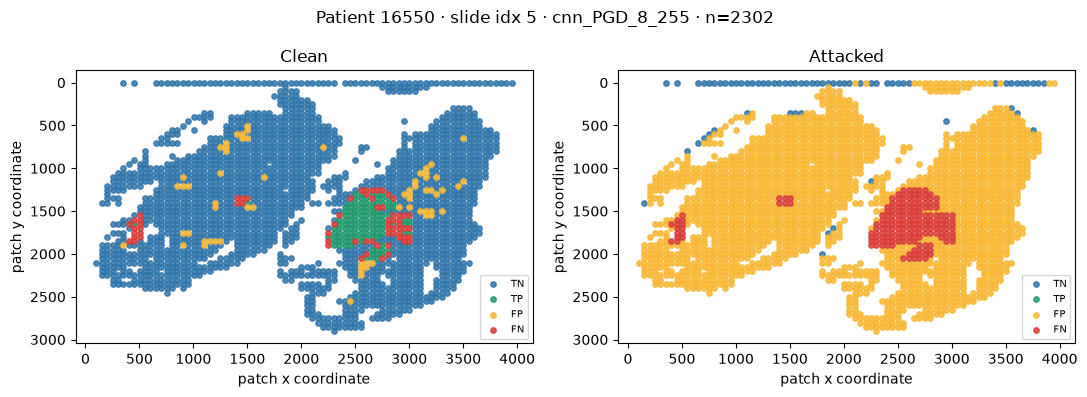

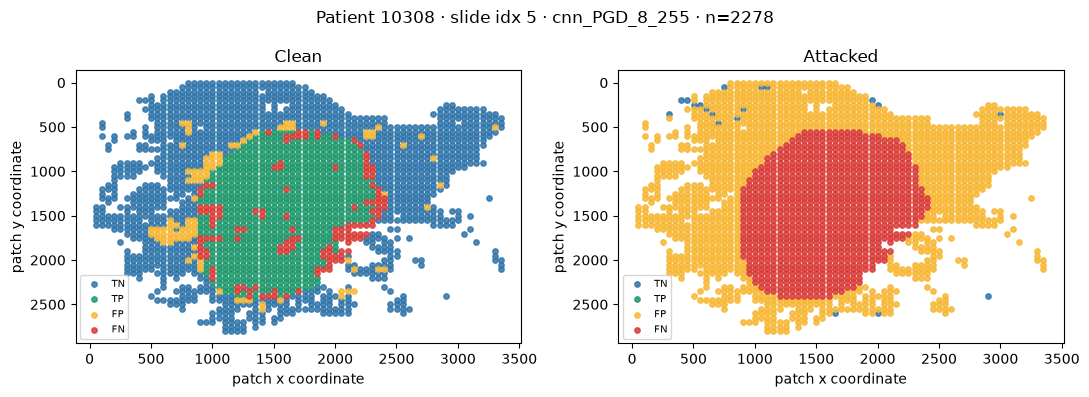

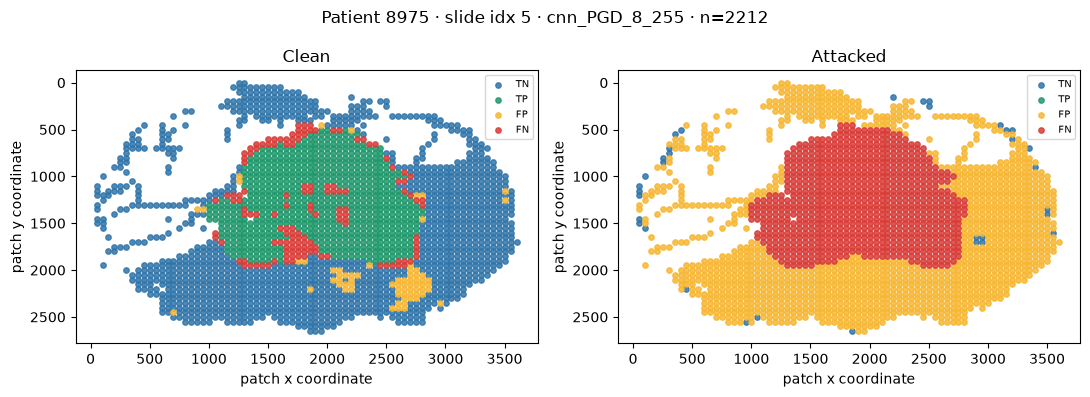

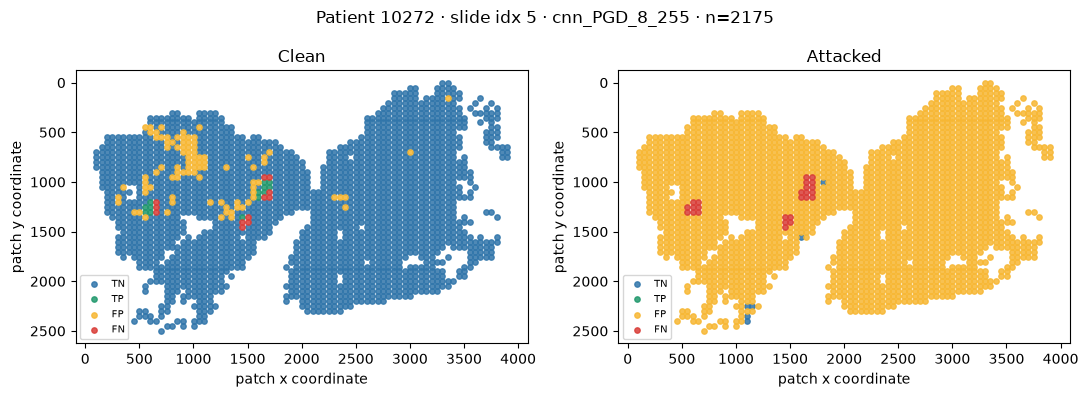

Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\spatial_clean_vs_pgd_patch_outcomes.csv
Spatial coordinate coverage: 51622 of 51622 | displayed slides: 4


In [34]:
# Patch coordinates are approximate and must not be described as full-slide validation.
if ANALYSIS_ENABLED:
    def spatial_fields(relative_path):
        stem=Path(relative_path).stem
        m=re.search(r"(?:_idx(?P<slide>\d+))?_x(?P<x>\d+)_y(?P<y>\d+)_class[01]$",stem)
        if m is None: return (None,np.nan,np.nan)
        return (m.group("slide") if m.group("slide") is not None else "unspecified",
                int(m.group("x")),int(m.group("y")))

    def spatial_plot(table,title,filename):
        fig,axs=plt.subplots(1,2,figsize=(11,4))
        categories={"TN":"#3075aa","TP":"#20986c","FP":"#f7b733","FN":"#d93c37"}
        for ax,(label,dfi) in zip(axs,[("Clean",table),("Attacked",table)]):
            column="clean_outcome" if label=="Clean" else "attacked_outcome"
            for cat,color in categories.items():
                sub=dfi[dfi[column]==cat]
                ax.scatter(sub.patch_x,sub.patch_y,s=15,color=color,alpha=.85,label=cat)
            ax.invert_yaxis();ax.set(xlabel="patch x coordinate",ylabel="patch y coordinate",title=label)
            ax.legend(fontsize=7,loc="best")
        fig.suptitle(title);fig.tight_layout();fig.savefig(RESULTS_DIR/filename,dpi=180)
        plt.show();plt.close(fig)

    def label_outcomes(y,prob,threshold=.5):
        y=np.asarray(y,dtype=int); pred=np.asarray(prob)>=threshold
        return np.select([(~pred)&(y==0),pred&(y==1),pred&(y==0),(~pred)&(y==1)],
                         ["TN","TP","FP","FN"],default="UNKNOWN")

    if RUN_SPATIAL_MAPPING:
        plotted=0
        selected_names=[k for k in attack_prediction_frames if k.startswith("cnn_PGD_") and k.endswith("8_255")]
        if not selected_names: raise RuntimeError("No CNN PGD eps=8/255 result found. Include 8/255 in EPS_GRID")
        attack_name=selected_names[0];attack_df=attack_prediction_frames[attack_name].copy()
        sp=attack_df.relative_path.apply(spatial_fields).apply(pd.Series)
        sp.columns=["slide_idx","patch_x","patch_y"]
        attack_df=pd.concat([attack_df.reset_index(drop=True),sp.reset_index(drop=True)],axis=1)
        attack_df=attack_df.dropna(subset=["patch_x","patch_y","slide_idx"]).copy()
        attack_df["clean_outcome"]=label_outcomes(attack_df.y,attack_df.clean_p,frozen_thresholds["cnn"]["validation_F1"])
        attack_df["attacked_outcome"]=label_outcomes(attack_df.y,attack_df.p,frozen_thresholds["cnn"]["validation_F1"])
        groupby=["patient_id","slide_idx"]
        counts=attack_df.groupby(groupby).size().sort_values(ascending=False)
        for (pid,slide),n in counts.head(4).items():
            if n<2:continue
            part=attack_df[(attack_df.patient_id==pid)&(attack_df.slide_idx==slide)]
            spatial_plot(part,f"Patient {pid} · slide idx {slide} · {attack_name} · n={n}",
                         f"spatial_patient_{pid}_slide_{slide}.png")
            plotted+=1
        write_csv(attack_df,"spatial_clean_vs_pgd_patch_outcomes.csv")
        if RUN_ALL_REQUESTED and (attack_df.empty or plotted==0):
            raise RuntimeError("Spatial mapping cannot be completed with the selected patches: no 2+ coordinate-coded patches on the same patient/slide. Increase ATTACK_N or check IDC filename coordinates.")
        print("Spatial coordinate coverage:",len(attack_df),"of",len(attack_subset),
              "| displayed slides:",plotted)
    else:
        print("Spatial patch error maps not evaluated; RUN_SPATIAL_MAPPING=False")


### Approximate H&E stain variation

Synthetic stain shifts do not establish cross-institutional generalization.

In [35]:
# Synthetic stain shifts test sensitivity, not cross-hospital generalization.
if ANALYSIS_ENABLED:
    _HE=torch.tensor([[.65,.07],[.70,.99],[.29,.11]],dtype=torch.float32)
    _HE=_HE/_HE.norm(dim=0,keepdim=True)

    def approximate_he_shift(x,h_scale=1.0,e_scale=1.0):
        H=_HE.to(device=x.device,dtype=x.dtype)
        OD=-torch.log(x.clamp(min=1/255,max=1))
        conc=torch.einsum("sc,bcxy->bsxy",torch.linalg.pinv(H),OD).clamp(min=0)
        reconstructed=torch.einsum("cs,bsxy->bcxy",H,conc)
        residual=OD-reconstructed
        scaling=torch.tensor([h_scale,e_scale],device=x.device,dtype=x.dtype).view(1,2,1,1)
        shifted=(residual+torch.einsum("cs,bsxy->bcxy",H,conc*scaling))
        return torch.exp(-shifted).clamp(0,1)

    if RUN_STAIN_SENSITIVITY:
        subset=choose_subset(manifest,"test",STAIN_EVAL_N)
        stain_loader=loader_subset(subset)
        stain_conditions={"reference":(1.0,1.0),"H_low":(.8,1.0),"H_high":(1.2,1.0),
                          "E_low":(1.0,.8),"E_high":(1.0,1.2),"H_low_E_high":(.8,1.2)}
        he_rows=[];patch_rows=[]
        for model_name,model in model_dict.items():
            model.eval()
            for condition,(h,e) in stain_conditions.items():
                rows=[]
                for x,y,ids in stain_loader:
                    x=x.to(DEVICE)
                    with torch.no_grad(): pp=torch.softmax(model(approximate_he_shift(x,h,e)),1)[:,1].cpu()
                    rows.extend(zip(ids.tolist(),y.tolist(),pp.tolist()))
                table=pd.DataFrame(rows,columns=["sample_id","y","p"])
                table["model"]=model_name;table["shift"]=condition
                patch_rows.append(table)
                he_rows.append({"model":model_name,"shift":condition,"h_scale":h,"e_scale":e,
                                **binary_scores(table.y,table.p)})
        stain_results=pd.DataFrame(he_rows)
        write_csv(stain_results,"approximate_he_shift_robustness.csv")
        write_csv(pd.concat(patch_rows,ignore_index=True),"approximate_he_shift_patch_predictions.csv")
        display(stain_results[["model","shift","accuracy","recall","false_negative_rate"]])
    else:
        print("Approximate H&E sensitivity analysis not evaluated; RUN_STAIN_SENSITIVITY=False")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\approximate_he_shift_robustness.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\approximate_he_shift_patch_predictions.csv


,model,shift,accuracy,recall,false_negative_rate
0,cnn,reference,0.841797,0.865672,0.134328
1,cnn,H_low,0.832031,0.791045,0.208955
2,cnn,H_high,0.837891,0.947761,0.052239
3,cnn,E_low,0.818359,0.910448,0.089552
4,cnn,E_high,0.851562,0.813433,0.186567
5,cnn,H_low_E_high,0.835938,0.679104,0.320896
6,resnet18_pretrained,reference,0.869141,0.925373,0.074627
7,resnet18_pretrained,H_low,0.869141,0.843284,0.156716
8,resnet18_pretrained,H_high,0.855469,0.947761,0.052239
9,resnet18_pretrained,E_low,0.802734,0.962687,0.037313


## 10. Grad-CAM examples

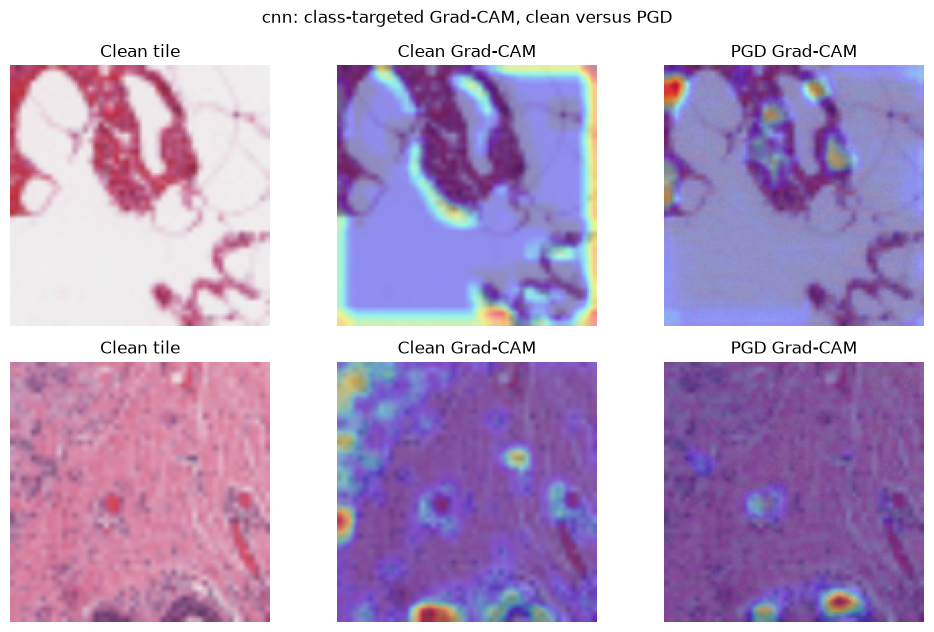

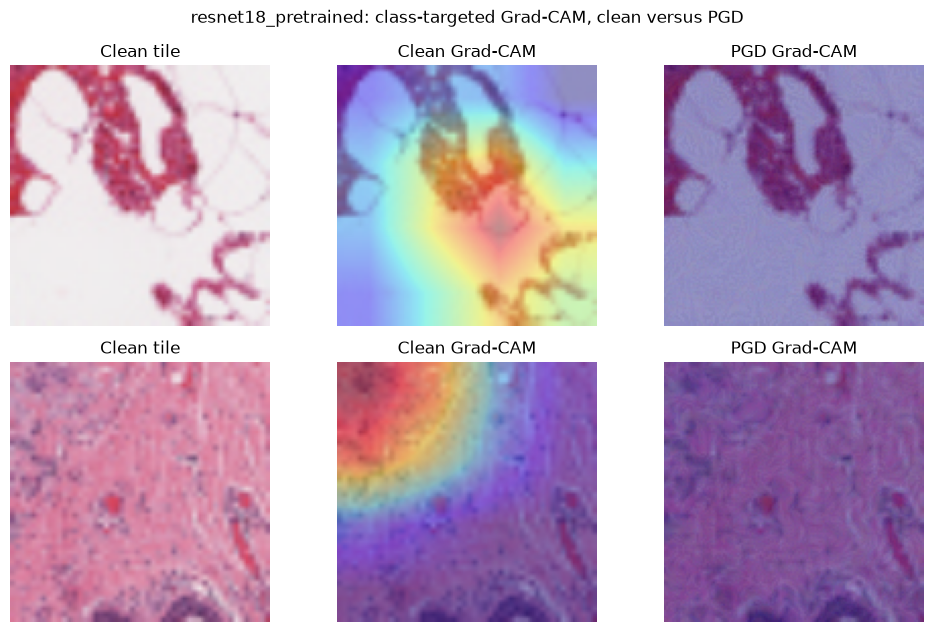

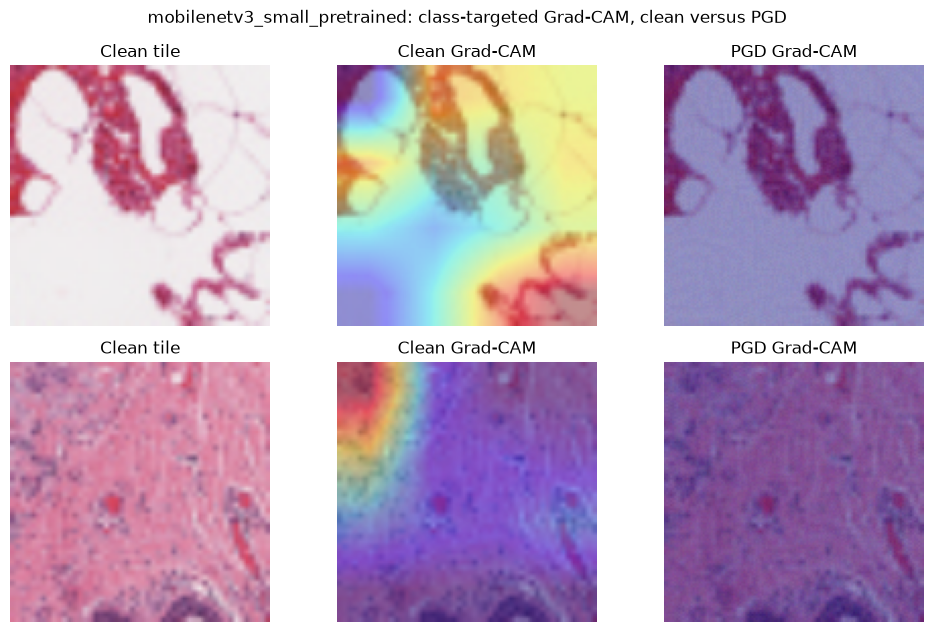

In [36]:
# Use Grad-CAM as a qualitative comparison, not causal evidence of model reasoning.
if ANALYSIS_ENABLED:
    def gradcam_heatmap(model,x,target_class=1):
        backbone=model.backbone
        if isinstance(backbone,SmallCNN): layer=backbone.features[6]
        elif hasattr(backbone,"layer4"):layer=backbone.layer4[-1].conv2
        elif hasattr(backbone,"features"):
            convs=[m for m in backbone.features.modules() if isinstance(m,nn.Conv2d)]
            layer=convs[-1]
        else:raise ValueError("No suitable convolution found")
        activations=[]
        handle=layer.register_forward_hook(lambda module,inputs,output: activations.append(output))
        try:
            inp=x.unsqueeze(0).to(DEVICE).detach().requires_grad_(True)
            with torch.enable_grad():
                logits=model(inp)
                feat=activations[0]
                gradient=torch.autograd.grad(logits[0,target_class],feat)[0]
                heat=F.relu((gradient.mean((2,3),keepdim=True)*feat).sum(dim=1,keepdim=True))
                heat=F.interpolate(heat,size=inp.shape[-2:],mode="bilinear",align_corners=False)[0,0].detach().cpu().numpy()
            heat-=heat.min();heat/=heat.max()+1e-8
            return heat
        finally:handle.remove()

    if RUN_EXTRA_ANALYSES:
        picks=attack_subset.sample(n=min(2,len(attack_subset)),random_state=TRAIN_SEED)
        for model_name,model in model_dict.items():
            fig,axes=plt.subplots(len(picks),3,figsize=(10,3.2*len(picks)),squeeze=False)
            for ri,(_,entry) in enumerate(picks.iterrows()):
                with Image.open(DATA_ROOT/entry.relative_path) as im:
                    x=transforms.Compose([transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),transforms.ToTensor()])(im.convert("RGB"))
                img=x.permute(1,2,0).numpy(); y=torch.tensor([int(entry.label)],device=DEVICE)
                with torch.enable_grad():
                    xa=pgd_attack(model,x.unsqueeze(0).to(DEVICE),y,DEFENSE_EPS,PGD_STEPS,PGD_RESTARTS)[0]
                clean_map=gradcam_heatmap(model,x,target_class=int(entry.label))
                adv_map=gradcam_heatmap(model,xa.cpu(),target_class=int(entry.label))
                for col,picture,heat,title in [(0,img,None,"Clean tile"),(1,img,clean_map,"Clean Grad-CAM"),
                                                (2,xa.cpu().permute(1,2,0).numpy(),adv_map,"PGD Grad-CAM")]:
                    ax=axes[ri,col];ax.imshow(picture)
                    if heat is not None: ax.imshow(heat,cmap="jet",alpha=.40,vmin=0,vmax=1)
                    ax.set(title=title);ax.axis("off")
            fig.suptitle(f"{model_name}: class-targeted Grad-CAM, clean versus PGD")
            fig.tight_layout();fig.savefig(RESULTS_DIR/f"gradcam_clean_attack_{model_name}.png",dpi=170);plt.show();plt.close(fig)
    else:print("Grad-CAM not evaluated; RUN_EXTRA_ANALYSES=True enables it")


## 11. DeepFool and optional AutoAttack

Native DeepFool is an approximate L₂ attack. The binary custom AutoAttack subset is not the standard complete suite.

In [37]:
if ANALYSIS_ENABLED:
    # Native binary DeepFool (L2), implemented in PyTorch to avoid torchattacks
    # version conflicts. This is NOT the third-party torchattacks implementation.
    def deepfool_binary_native(model, x, max_steps=20, overshoot=0.02, return_diagnostics=False):
        was_training = model.training
        model.eval()
        adv_list = []
        diagnostic_rows = []
        try:
            for original in x.detach():
                x0 = original.unsqueeze(0)
                with torch.no_grad():
                    starting_class = int(model(x0).argmax(dim=1).item())
                other_class = 1 - starting_class
                updated = x0.detach().clone()
                grad_steps = 0
                for _ in range(int(max_steps)):
                    with torch.enable_grad():
                        z = updated.detach().requires_grad_(True)
                        logits = model(z)
                        if int(logits.argmax(dim=1).item()) != starting_class:
                            break
                        margin = logits[0, starting_class] - logits[0, other_class]
                        grad = torch.autograd.grad(margin, z, retain_graph=False)[0]
                        denom = (grad * grad).sum().clamp_min(1e-12)
                        step = -(margin.detach() + 1e-5) * grad.detach() / denom
                    grad_steps += 1
                    updated = (z.detach() + (1.0 + overshoot) * step).clamp(0.0, 1.0).detach()
                adv_list.append(updated)
                with torch.no_grad():
                    final_class = int(model(updated).argmax(dim=1).item())
                diagnostic_rows.append({
                    "initial_pred": starting_class,
                    "final_pred": final_class,
                    "decision_flipped": bool(final_class != starting_class),
                    "gradient_steps_used": int(grad_steps),
                    "iteration_cap_reached": bool(grad_steps >= int(max_steps) and final_class == starting_class),
                    "adv_boundary_fraction": float(((updated <= 1e-6) | (updated >= 1.0 - 1e-6)).float().mean().item()),
                })
            adversarial = torch.cat(adv_list, dim=0).detach()
            return (adversarial, diagnostic_rows) if return_diagnostics else adversarial
        finally:
            model.train(was_training)

    optional_status = []
    deepfool_rows = []
    auto_rows = []
    if RUN_DEEPFOOL:
        cap = ALL_SMOKE_OPTIONAL_N if RUN_PROFILE == "all_smoke" else DEEPFOOL_FULL_SAMPLE_LIMIT
        subset = choose_subset(manifest, "test", cap, seed=SPLIT_SEED + 310)
        df_loader = loader_subset(subset, batch=min(4, ATTACK_BATCH_SIZE))
        for name, model in model_dict.items():
            yy, preds, l2, clean_correct, adv_correct = [], [], [], [], []
            for x,y,ids in df_loader:
                x = x.to(DEVICE)
                y = y.to(DEVICE)
                adv = deepfool_binary_native(model, x, max_steps=12 if MODE=="quick" else 20)
                with torch.no_grad():
                    pc = model(x).argmax(1)
                    logits_adv = model(adv)
                    probs = torch.softmax(logits_adv, dim=1)[:,1]
                    pa = logits_adv.argmax(1)
                yy.extend(y.cpu().tolist())
                preds.extend(probs.cpu().tolist())
                clean_correct.extend((pc == y).cpu().tolist())
                adv_correct.extend((pa == y).cpu().tolist())
                l2.extend((adv - x).flatten(1).norm(p=2, dim=1).cpu().tolist())
            metric = binary_scores(yy, preds)
            eligible = np.asarray(clean_correct, dtype=bool)
            success = np.asarray(adv_correct, dtype=bool)
            deepfool_rows.append({
                "model":name, "attack":"DeepFool_binary_native_L2",
                "implementation":"native_pytorch_binary_margin", "mean_l2":float(np.mean(l2)),
                "success_given_clean_correct":float((~success[eligible]).mean()) if eligible.any() else float('nan'),
                "n_original_clean_correct":int(eligible.sum()),"patients":int(subset.patient_id.nunique()),
                **metric
            })
            optional_status.append({"analysis":"DeepFool", "model":name, "status":"COMPLETED", "reason":"native PyTorch binary L2 DeepFool"})
        deepfool_table = pd.DataFrame(deepfool_rows)
        write_csv(deepfool_table,"deepfool_L2_optional.csv")
        display(deepfool_table)
    else:
        print("DeepFool disabled by RUN_DEEPFOOL=False")

    if RUN_AUTOATTACK:
        import_ok = OPTIONAL_ATTACK_IMPORTS.get("autoattack", {}).get("available", False)
        cap = ALL_SMOKE_OPTIONAL_N if RUN_PROFILE == "all_smoke" else AUTOATTACK_FULL_SAMPLE_LIMIT
        subset = choose_subset(manifest, "test", cap, seed=SPLIT_SEED + 311)
        dl = loader_subset(subset, batch=ATTACK_BATCH_SIZE)
        xx,yy = [],[]
        for x,y,_ in dl:
            xx.append(x); yy.append(y)
        xx = torch.cat(xx, dim=0).to(DEVICE)
        yy = torch.cat(yy, dim=0).to(DEVICE)
        targets = dict(model_dict)
        if RUN_DEFENSE:
            targets["pgd_training"] = defense_models["pgd_training"]
        for name, model in targets.items():
            if not import_ok:
                reason = OPTIONAL_ATTACK_IMPORTS["autoattack"]["error"]
                optional_status.append({"analysis":"AutoAttack_binary_custom", "model":name,
                                        "status":"SKIPPED_DEPENDENCY", "reason":reason})
                auto_rows.append({"model":name, "attack":"AutoAttack_binary_custom_APGD_CE_Square",
                                  "status":"SKIPPED_DEPENDENCY", "n":0, "error":reason,
                                  "not_standard_four_attack_ensemble":True})
                continue
            try:
                from autoattack import AutoAttack
                model.eval()
                aa = AutoAttack(model, norm="Linf", eps=DEFENSE_EPS,
                                version="custom", attacks_to_run=["apgd-ce", "square"],
                                device=str(DEVICE), verbose=False)
                adv = aa.run_standard_evaluation(xx, yy, bs=min(ATTACK_BATCH_SIZE,len(xx)))
                if adv.shape != xx.shape or not torch.isfinite(adv).all():
                    raise AssertionError("AutoAttack returned invalid adversarial images")
                if float((adv - xx).abs().max()) > DEFENSE_EPS + 1e-5:
                    raise AssertionError("Custom AutoAttack exceeded L_inf epsilon")
                if float(adv.min()) < -1e-5 or float(adv.max()) > 1 + 1e-5:
                    raise AssertionError("AutoAttack produced pixels outside [0, 1]")
                with torch.no_grad():
                    p = torch.softmax(model(adv),dim=1)[:,1].cpu().numpy()
                source_thresholds = (frozen_thresholds[name] if name in frozen_thresholds
                                     else defense_frozen_thresholds[name])
                frozen_val_f1 = float(source_thresholds["validation_F1"])
                val_f1_scores = binary_scores(yy.cpu(), p, frozen_val_f1)
                auto_rows.append({"model":name,"attack":"AutoAttack_binary_custom_APGD_CE_Square",
                                  "status":"COMPLETED", "error":"", "n":len(yy),
                                  "not_standard_four_attack_ensemble":True,
                                  "max_linf":float((adv-xx).abs().max()),
                                  "filename_derived_groups":int(subset.patient_id.nunique()),
                                  "threshold_policy":"validation_F1",
                                  "frozen_validation_threshold":frozen_val_f1,
                                  "accuracy_at_validation_F1":float(val_f1_scores["accuracy"]),
                                  "recall_at_validation_F1":float(val_f1_scores["recall"]),
                                  "fn_at_validation_F1":int(val_f1_scores["fn"]),
                                  **binary_scores(yy.cpu(),p)})
                optional_status.append({"analysis":"AutoAttack_binary_custom", "model":name,
                                        "status":"COMPLETED", "reason":"APGD-CE+Square (custom, NOT standard)"})
            except Exception as exc:
                # Do not hide failures or fabricate accuracy for a failed attack.
                reason = f"{type(exc).__name__}: {exc}"
                print(f"[WARNING] AutoAttack failed for {name}: {reason}")
                auto_rows.append({"model":name,"attack":"AutoAttack_binary_custom_APGD_CE_Square",
                                  "status":"FAILED", "n":0, "error":reason,
                                  "not_standard_four_attack_ensemble":True})
                optional_status.append({"analysis":"AutoAttack_binary_custom", "model":name,
                                        "status":"FAILED", "reason":reason})
        write_csv(pd.DataFrame(auto_rows), "autoattack_optional.csv")
        display(pd.DataFrame(auto_rows))
    else:
        print("AutoAttack disabled by RUN_AUTOATTACK=False")
    if optional_status:
        write_csv(pd.DataFrame(optional_status),"optional_attack_execution_status.csv")
        display(pd.DataFrame(optional_status))


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\deepfool_L2_optional.csv


,model,attack,implementation,mean_l2,success_given_clean_correct,n_original_clean_correct,patients,n,accuracy,precision,...,specificity,false_negative_rate,f1,roc_auc,pr_auc,brier,tn,fp,fn,tp
0,cnn,DeepFool_binary_native_L2,native_pytorch_binary_margin,0.798066,0.777778,27,23,32,0.34375,0.000000,...,0.458333,1.000,0.000000,0.109375,0.162965,0.253574,11,13,8,0
1,resnet18_pretrained,DeepFool_binary_native_L2,native_pytorch_binary_margin,0.234142,0.607143,28,23,32,0.46875,0.235294,...,0.458333,0.500,0.320000,0.338542,0.215691,0.252007,11,13,4,4
2,mobilenetv3_small_pretrained,DeepFool_binary_native_L2,native_pytorch_binary_margin,0.146386,0.620690,29,23,32,0.43750,0.250000,...,0.375000,0.375,0.357143,0.453125,0.248667,0.250362,9,15,3,5


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\autoattack_optional.csv


,model,attack,status,error,n,not_standard_four_attack_ensemble,max_linf,filename_derived_groups,threshold_policy,frozen_validation_threshold,...,specificity,false_negative_rate,f1,roc_auc,pr_auc,brier,tn,fp,fn,tp
0,cnn,AutoAttack_binary_custom_APGD_CE_Square,COMPLETED,,256,True,0.031373,41,validation_F1,0.729540,...,0.00000,1.000000,0.0000,0.000000,0.146005,0.940240,0,189,67,0
1,resnet18_pretrained,AutoAttack_binary_custom_APGD_CE_Square,COMPLETED,,256,True,0.031373,41,validation_F1,0.679640,...,0.00000,1.000000,0.0000,0.000000,0.171555,0.941077,0,189,67,0
2,mobilenetv3_small_pretrained,AutoAttack_binary_custom_APGD_CE_Square,COMPLETED,,256,True,0.031373,41,validation_F1,0.595808,...,0.00000,1.000000,0.0000,0.000000,0.223760,0.950915,0,189,67,0
3,pgd_training,AutoAttack_binary_custom_APGD_CE_Square,COMPLETED,,256,True,0.031373,41,validation_F1,0.488024,...,0.73545,0.358209,0.5375,0.848377,0.628963,0.158447,139,50,24,43


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\optional_attack_execution_status.csv


,analysis,model,status,reason
0,DeepFool,cnn,COMPLETED,native PyTorch binary L2 DeepFool
1,DeepFool,resnet18_pretrained,COMPLETED,native PyTorch binary L2 DeepFool
2,DeepFool,mobilenetv3_small_pretrained,COMPLETED,native PyTorch binary L2 DeepFool
3,AutoAttack_binary_custom,cnn,COMPLETED,"APGD-CE+Square (custom, NOT standard)"
4,AutoAttack_binary_custom,resnet18_pretrained,COMPLETED,"APGD-CE+Square (custom, NOT standard)"
5,AutoAttack_binary_custom,mobilenetv3_small_pretrained,COMPLETED,"APGD-CE+Square (custom, NOT standard)"
6,AutoAttack_binary_custom,pgd_training,COMPLETED,"APGD-CE+Square (custom, NOT standard)"


In [38]:
# A reference DeepFool run is an optional cross-check of the native approximation.
if ANALYSIS_ENABLED and RUN_DEEPFOOL:
    cross_rows=[]
    import importlib.util
    reference_available=bool(importlib.util.find_spec("torchattacks")) if RUN_DEEPFOOL_CROSSCHECK else False
    reference_attack=None
    if reference_available:
        try:
            from torchattacks import DeepFool as RefDeepFool
        except Exception as exc:
            reference_available=False
            print("[REFERENCE SKIPPED] torchattacks import:",repr(exc))
    cap=ALL_SMOKE_OPTIONAL_N if MODE=="quick" else DEEPFOOL_FULL_SAMPLE_LIMIT
    cross_test=choose_subset(manifest,"test",cap,seed=SPLIT_SEED+310)
    for name,model in model_dict.items():
        for x,y,idx in loader_subset(cross_test,batch=min(4,ATTACK_BATCH_SIZE)):
            x=x.to(DEVICE);y=y.to(DEVICE)
            with torch.no_grad(): clean_pred=model(x).argmax(1)
            native=deepfool_binary_native(model,x,max_steps=12 if MODE=="quick" else 20)
            with torch.no_grad(): native_pred=model(native).argmax(1)
            distance=(native-x).flatten(1).norm(dim=1).cpu().numpy()
            native_success=((clean_pred==y)&(native_pred!=y)).cpu().numpy()
            initial_correct=(clean_pred==y).cpu().numpy()
            ref_success=np.full(len(y),np.nan)
            if reference_available:
                try:
                    reference_attack=RefDeepFool(model,steps=12 if MODE=="quick" else 20,overshoot=0.02)
                    reference_adv=reference_attack(x,y)
                    with torch.no_grad(): ref_pred=model(reference_adv).argmax(1)
                    ref_success=((clean_pred==y)&(ref_pred!=y)).cpu().numpy()
                except Exception as exc:
                    reference_available=False
                    print("[REFERENCE FAILED]",repr(exc))
            for j,sid in enumerate(idx.tolist()):
                cross_rows.append({"model":name,"sample_id":int(sid),"clean_correct":bool(initial_correct[j]),
                    "native_success":bool(native_success[j]),"native_l2":float(distance[j]),
                    "successful_only_l2":float(distance[j]) if native_success[j] else np.nan,
                    "reference_success":ref_success[j],
                    "reference_status":"EXECUTED" if np.isfinite(ref_success[j]) else "SKIPPED_DEPENDENCY_OR_FAILURE"})
    deepfool_audit=pd.DataFrame(cross_rows)
    write_csv(deepfool_audit,"deepfool_success_only_l2_reference_audit.csv")
    deepfool_grouped=deepfool_audit.groupby("model",as_index=False).agg(
        eligible_clean_correct_n=("clean_correct","sum"),
        native_success_n=("native_success","sum"),
        successful_only_mean_l2=("successful_only_l2","mean"),
        reference_success_observed_n=("reference_success","count"))
    write_csv(deepfool_grouped,"deepfool_success_only_l2_summary.csv")
    display(deepfool_grouped)


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\deepfool_success_only_l2_reference_audit.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\deepfool_success_only_l2_summary.csv


,model,eligible_clean_correct_n,native_success_n,successful_only_mean_l2,reference_success_observed_n
0,cnn,27,21,0.905197,32
1,mobilenetv3_small_pretrained,29,18,0.169160,32
2,resnet18_pretrained,28,16,0.236342,32


## 12. Patient-level analysis and additional validation

In [39]:
if ANALYSIS_ENABLED:
    patient_rows=[]
    for name,bundle in baseline_predictions.items():
        pred=bundle["test"].copy()
        pred["correct"]=(pred.y==(pred.p>=.5).astype(int)).astype(int)
        grouped=pred.groupby("patient_id").agg(n_patches=("y","size"),patch_accuracy=("correct","mean"),
                                               positive_patches=("y","sum"),mean_probability=("p","mean")).reset_index()
        grouped["model"]=name;patient_rows.append(grouped)
    patient_report=pd.concat(patient_rows,ignore_index=True)
    write_csv(patient_report,"per_patient_patch_accuracy_not_diagnosis.csv")
    display(patient_report.groupby("model").patch_accuracy.agg(["count","mean","median","min","max"]))


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\per_patient_patch_accuracy_not_diagnosis.csv


,count,mean,median,min,max
model,,,,,
cnn,42,0.857603,0.893678,0.610569,0.988688
mobilenetv3_small_pretrained,42,0.886800,0.902901,0.672241,0.993213
resnet18_pretrained,42,0.867600,0.890465,0.654222,0.985671


### Optional external-cohort evaluation

In [40]:
# External evaluation requires a genuinely independent cohort and verified provenance.
if ANALYSIS_ENABLED:
    if RUN_EXTERNAL_VALIDATION:
        if EXTERNAL_DATA_ROOT is None or not EXTERNAL_PROVENANCE_CONFIRMED:
            raise ValueError("External evaluation requires EXTERNAL_DATA_ROOT and EXTERNAL_PROVENANCE_CONFIRMED=True")
        external_root=Path(EXTERNAL_DATA_ROOT).expanduser()
        if not external_root.is_dir():
            raise FileNotFoundError(f"External dataset not found: {external_root}")
        external_raw=scan_images(external_root)
        external_manifest, _=deduplicate_images(external_raw,external_root)
        overlapping_names=set(zip(images.patient_id,images.filename,images.label)) & set(zip(
            external_manifest.patient_id,external_manifest.filename,external_manifest.label))
        if overlapping_names:
            raise ValueError(f"External source overlaps internal patient/filename/class keys: {len(overlapping_names)}. Investigate provenance.")
        external_manifest=external_manifest.reset_index(drop=True)
        external_manifest["sample_id"]=np.arange(len(external_manifest))
        external_manifest["split"]="external"
        external_loader=DataLoader(IDCPatches(external_manifest,external_root,augment=False),
                                   batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS)
        external_rows=[]
        for name,model in model_dict.items():
            records=[]
            model.eval()
            with torch.no_grad():
                for xx,yy,sids in external_loader:
                    prob=torch.softmax(model(xx.to(DEVICE)),1)[:,1].cpu().numpy()
                    records.extend(zip(sids.tolist(),yy.tolist(),prob.tolist()))
            pred=pd.DataFrame(records,columns=["sample_id","y","p"])
            pred=pred.merge(external_manifest[["sample_id","patient_id","relative_path"]],on="sample_id",validate="one_to_one")
            write_csv(pred,f"EXTERNAL_test_predictions_{name}.csv")
            external_rows.append({"model":name,"source":str(external_root),"threshold":0.5,
                                  "patients":pred.patient_id.nunique(),**binary_scores(pred.y,pred.p,0.5)})
        write_csv(pd.DataFrame(external_rows),"EXTERNAL_independent_cohort_metrics.csv")
        display(pd.DataFrame(external_rows))
    else:
        print("Independent external validation: NOT RUN (no eligible external dataset configured).")


Independent external validation: NOT RUN (no eligible external dataset configured).


In [41]:
# Patient comparisons need enough positive patches per patient for interpretation.
if ANALYSIS_ENABLED:
    hetero=[]
    for name in model_dict:
        key=f"{name}_PGD_8_255"
        if key not in attack_prediction_frames:
            continue
        t=attack_prediction_frames[key].copy()
        t["clean_correct"]=((t.clean_p>=.5).astype(int)==t.y.astype(int)).astype(int)
        t["adv_correct"]=((t.p>=.5).astype(int)==t.y.astype(int)).astype(int)
        t["new_fn"]=((t.y==1)&(t.clean_p>=.5)&(t.p<.5)).astype(int)
        for patient,grp in t.groupby("patient_id"):
            hetero.append({"model":name,"patient_id":patient,"n_patches":len(grp),
                "n_idc_positive":int((grp.y==1).sum()),"clean_accuracy":grp.clean_correct.mean(),
                "pgd_accuracy":grp.adv_correct.mean(),"accuracy_drop":grp.clean_correct.mean()-grp.adv_correct.mean(),
                "attack_induced_fn":int(grp.new_fn.sum())})
    if hetero:
        hdf=pd.DataFrame(hetero)
        write_csv(hdf,"patient_pgd_heterogeneity.csv")
        display(hdf.sort_values("accuracy_drop",ascending=False).head(10))

    robust_auc_rows=[]
    for (name,attack_method),grp in attack_results[attack_results.attack.isin(["FGSM","PGD"])].groupby(["model","attack"]):
        clean=attack_results[(attack_results.model==name)&(attack_results.attack=="Clean")]
        if clean.empty:continue
        points=pd.concat([clean[["epsilon","accuracy","recall"]],grp[["epsilon","accuracy","recall"]]])
        points=points.sort_values("epsilon").drop_duplicates("epsilon")
        eps=points.epsilon.to_numpy(dtype=float)
        if len(eps)<2 or np.max(eps)==np.min(eps):continue
        robust_auc_rows.append({"model":name,"attack":attack_method,"epsilon_max":float(eps.max()),
            "epsilon_grid_count":len(eps),"normalized_accuracy_epsilon_auc":float((np.trapezoid if hasattr(np, "trapezoid") else np.trapz)(points.accuracy,eps)/(eps.max()-eps.min())),
            "normalized_recall_epsilon_auc":float((np.trapezoid if hasattr(np, "trapezoid") else np.trapz)(points.recall,eps)/(eps.max()-eps.min()))})
    if robust_auc_rows:
        write_csv(pd.DataFrame(robust_auc_rows),"robustness_auc_epsilon_integral.csv")
        display(pd.DataFrame(robust_auc_rows))

    if RUN_DEFENSE:
        defense_cost=defense_results.copy()
        write_csv(defense_cost,"defense_effectiveness_and_training_cost.csv")
        print("Defense cost-efficiency includes elapsed training-time as recorded in this run or checkpoint metadata.")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\patient_pgd_heterogeneity.csv


,model,patient_id,n_patches,n_idc_positive,clean_accuracy,pgd_accuracy,accuracy_drop,attack_induced_fn
125,mobilenetv3_small_pretrained,9381,1326,128,0.993213,0.000000,0.993213,122
83,resnet18_pretrained,9381,1326,128,0.985671,0.000000,0.985671,124
106,mobilenetv3_small_pretrained,13692,607,335,0.980231,0.000000,0.980231,330
22,cnn,13692,607,335,0.980231,0.004942,0.975288,330
58,resnet18_pretrained,12932,737,304,0.960651,0.000000,0.960651,284
117,mobilenetv3_small_pretrained,9029,1634,137,0.960220,0.000000,0.960220,136
25,cnn,14209,342,309,0.959064,0.000000,0.959064,298
110,mobilenetv3_small_pretrained,15632,493,120,0.957404,0.000000,0.957404,107
33,cnn,9029,1634,137,0.957160,0.000000,0.957160,137
114,mobilenetv3_small_pretrained,8956,1825,340,0.956712,0.000000,0.956712,323


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\robustness_auc_epsilon_integral.csv


,model,attack,epsilon_max,epsilon_grid_count,normalized_accuracy_epsilon_auc,normalized_recall_epsilon_auc
0,cnn,FGSM,0.031373,4,0.246501,0.294878
1,cnn,PGD,0.031373,4,0.155559,0.138542
2,mobilenetv3_small_pretrained,FGSM,0.031373,4,0.671451,0.131938
3,mobilenetv3_small_pretrained,PGD,0.031373,4,0.110653,0.111032
4,resnet18_pretrained,FGSM,0.031373,4,0.206208,0.157104
5,resnet18_pretrained,PGD,0.031373,4,0.108411,0.114014


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\defense_effectiveness_and_training_cost.csv
Defense cost-efficiency includes elapsed training-time as recorded in this run or checkpoint metadata.


In [42]:
if ANALYSIS_ENABLED:
    patient_attack_rows=[]
    for name in model_dict:
        key=f"{name}_PGD_8_255"
        pr=attack_prediction_frames.get(key)
        if pr is None: continue
        for patient,one in pr.groupby("patient_id"):
            positives=one[one.y==1]
            npos=len(positives)
            patient_attack_rows.append({"model":name,"patient_id":patient,
               "n_patches":len(one),"positive_patches":npos,
               "clean_positive_recall":float((positives.clean_p>=.5).mean()) if npos else np.nan,
               "pgd_positive_recall":float((positives.p>=.5).mean()) if npos else np.nan,
               "attack_induced_FN":int(((positives.clean_p>=.5)&(positives.p<.5)).sum()),
               "interpretation":"REPORTABLE_DESCRIPTIVE" if npos>=MIN_PATIENT_POSITIVE_PATCHES else "INCONCLUSIVE_LOW_SUPPORT"})
    patient_attack_df=pd.DataFrame(patient_attack_rows)
    write_csv(patient_attack_df,"patient_clean_vs_PGD_positive_recall.csv")
    display(patient_attack_df.head(15))


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\patient_clean_vs_PGD_positive_recall.csv


,model,patient_id,n_patches,positive_patches,clean_positive_recall,pgd_positive_recall,attack_induced_FN,interpretation
0,cnn,10254,848,76,0.921053,0.0,70,REPORTABLE_DESCRIPTIVE
1,cnn,10269,1154,250,0.880000,0.0,220,REPORTABLE_DESCRIPTIVE
2,cnn,10272,2175,25,0.560000,0.0,14,REPORTABLE_DESCRIPTIVE
3,cnn,10274,878,219,0.981735,0.0,215,REPORTABLE_DESCRIPTIVE
4,cnn,10276,939,348,0.847701,0.0,295,REPORTABLE_DESCRIPTIVE
5,cnn,10279,1694,427,0.838407,0.0,358,REPORTABLE_DESCRIPTIVE
6,cnn,10282,2033,198,0.979798,0.0,194,REPORTABLE_DESCRIPTIVE
7,cnn,10308,2278,895,0.943017,0.0,844,REPORTABLE_DESCRIPTIVE
8,cnn,12817,934,572,0.660839,0.0,378,REPORTABLE_DESCRIPTIVE
9,cnn,12819,1627,223,0.834081,0.0,186,REPORTABLE_DESCRIPTIVE


In [43]:
if ANALYSIS_ENABLED:
    patient_positive_rows = []
    for model_name, bundle in baseline_predictions.items():
        pred = bundle["test"].copy()
        pred["positive_missed"] = ((pred.y == 1) & (pred.p < .5)).astype(int)
        for pid, group in pred.groupby("patient_id"):
            positive = group[group.y == 1]
            npos = len(positive)
            patient_positive_rows.append({
                "model": model_name, "patient_id": pid,
                "n_all_patches": len(group), "n_idc_positive": npos,
                "false_negatives": int(positive.positive_missed.sum()),
                "idc_positive_recall": float((positive.p >= .5).mean()) if npos else np.nan,
                "minimum_support_met": bool(npos >= MIN_PATIENT_POSITIVE_PATCHES),
                "interpretation": ("DESCRIPTIVE_PATCH_RECALL" if npos >= MIN_PATIENT_POSITIVE_PATCHES
                                  else "INSUFFICIENT_POSITIVE_PATCHES")
            })
    patient_positive_table = pd.DataFrame(patient_positive_rows)
    write_csv(patient_positive_table, "patient_positive_recall_and_support.csv")
    print("Patient-level patch recall (not diagnosis); adequate positive-patch support:",
          int(patient_positive_table.minimum_support_met.sum()), "/",len(patient_positive_table))
    display(patient_positive_table.sort_values(["model","n_idc_positive"], ascending=[True,False]).head(12))


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\patient_positive_recall_and_support.csv
Patient-level patch recall (not diagnosis); adequate positive-patch support: 126 / 126


,model,patient_id,n_all_patches,n_idc_positive,false_negatives,idc_positive_recall,minimum_support_met,interpretation
24,cnn,14155,1877,1206,80,0.933665,True,DESCRIPTIVE_PATCH_RECALL
7,cnn,10308,2278,895,51,0.943017,True,DESCRIPTIVE_PATCH_RECALL
32,cnn,8975,2212,833,81,0.902761,True,DESCRIPTIVE_PATCH_RECALL
13,cnn,12894,1716,650,71,0.890769,True,DESCRIPTIVE_PATCH_RECALL
20,cnn,13613,1457,630,51,0.919048,True,DESCRIPTIVE_PATCH_RECALL
8,cnn,12817,934,572,194,0.660839,True,DESCRIPTIVE_PATCH_RECALL
29,cnn,16570,917,542,76,0.859779,True,DESCRIPTIVE_PATCH_RECALL
5,cnn,10279,1694,427,69,0.838407,True,DESCRIPTIVE_PATCH_RECALL
36,cnn,9176,1045,409,9,0.977995,True,DESCRIPTIVE_PATCH_RECALL
10,cnn,12820,1122,369,72,0.804878,True,DESCRIPTIVE_PATCH_RECALL


In [44]:
# Record which analyses ran so smoke-test results are not presented as full research.
if ANALYSIS_ENABLED:
    flag_audit={
      "run_profile":RUN_PROFILE, "training_policy":TRAIN_POLICY, "quick_smoke_only":MODE=="quick", "run_full_dataset":MODE=="full",
      "patient_disjoint":True,"content_checked_duplicate_keys":True,
      "baseline_models_trained":list(model_dict),
      "defenses_evaluated":bool(RUN_DEFENSE),"epsilon_grid":EPS_GRID,
      "patient_cluster_ci":True,"paired_defense_ci":bool(RUN_DEFENSE and RUN_PAIRED_BOOTSTRAP),
      "validation_target_recall_threshold":TARGET_RECALL,
      "temperature_calibration":bool(RUN_CALIBRATION),
      "attack_calibration":bool(RUN_ATTACK_CALIBRATION),
      "targeted_positive_to_negative":bool(RUN_TARGETED_ATTACK),
      "spatial_error_mapping":bool(RUN_SPATIAL_MAPPING),
      "approximate_stain_sensitivity":bool(RUN_STAIN_SENSITIVITY),
      "strong_pgd_and_gradcam":bool(RUN_EXTRA_ANALYSES),
      "optional_deepfool":bool(RUN_DEEPFOOL),"optional_autoattack_requested":bool(RUN_AUTOATTACK),
      "autoattack_import_available":bool(OPTIONAL_ATTACK_IMPORTS["autoattack"]["available"]),
      "paired_attack_CI":bool(RUN_PAIRED_BOOTSTRAP),
      "paired_architecture_CI":bool(RUN_PAIRED_BOOTSTRAP and len(model_dict)>1),
      "attack_induced_false_negative_flips":bool(RUN_FN_FLIP_ANALYSIS),
      "cross_model_transferability":bool(RUN_TRANSFERABILITY and len(model_dict)>1),
      "hypothetical_cost_thresholds":bool(RUN_COST_SCENARIOS),
      "experiment_id":EXPERIMENT_ID,
      "external_validation":bool(RUN_EXTERNAL_VALIDATION),
      "input_resolution_sensitivity": "not_run_automatically; rerun FULL_IMAGE_SIZE=224 separately",
      "primary_train_seed":int(TRAIN_SEED),
      "repeat_seeds":list(map(int, REPEAT_MODEL_SEEDS)),
      "legacy_repeat_cnn_seeds":list(map(int, REPEAT_CNN_TRAIN_SEEDS)),
      "experiment_revision":EXPERIMENT_REVISION,
      "checkpoint_locations_used":{k:str(v) for k,v in checkpoint_paths.items()}
    }
    (RESULTS_DIR/"analysis_completeness.json").write_text(json.dumps(flag_audit,indent=2),encoding="utf-8")
    print(json.dumps(flag_audit,indent=2))
    if MODE=="quick": print("\nNOT READY FOR FINAL RESEARCH CLAIMS — re-run full mode and examine patient-level uncertainty.")


{
  "run_profile": "all_research",
  "training_policy": "train_missing",
  "quick_smoke_only": false,
  "run_full_dataset": true,
  "patient_disjoint": true,
  "content_checked_duplicate_keys": true,
  "baseline_models_trained": [
    "cnn",
    "resnet18_pretrained",
    "mobilenetv3_small_pretrained"
  ],
  "defenses_evaluated": true,
  "epsilon_grid": [
    0,
    0.00784313725490196,
    0.01568627450980392,
    0.03137254901960784
  ],
  "patient_cluster_ci": true,
  "paired_defense_ci": true,
  "validation_target_recall_threshold": 0.9,
  "temperature_calibration": true,
  "attack_calibration": true,
  "targeted_positive_to_negative": true,
  "spatial_error_mapping": true,
  "approximate_stain_sensitivity": true,
  "strong_pgd_and_gradcam": true,
  "optional_deepfool": true,
  "optional_autoattack_requested": true,
  "autoattack_import_available": true,
  "paired_attack_CI": true,
  "paired_architecture_CI": true,
  "attack_induced_false_negative_flips": true,
  "cross_model_tran

### Robustness–efficiency Pareto comparison

Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\V8_robustness_efficiency_pareto.csv


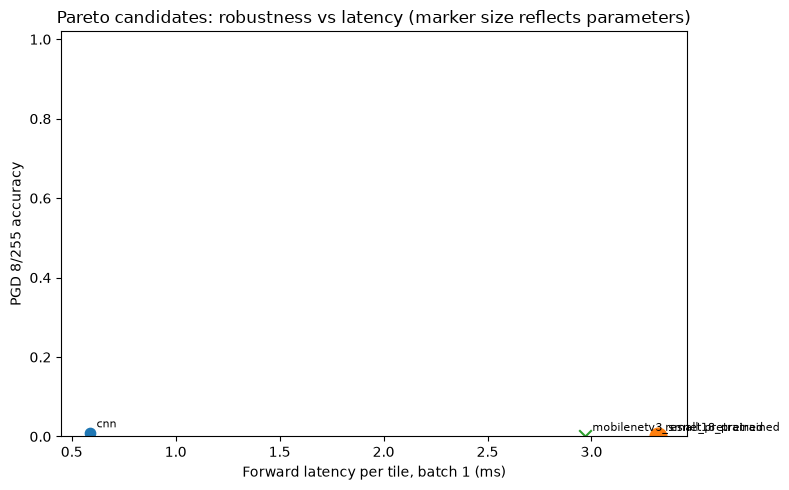

,model,pareto_efficient,clean_positive_recall,pgd_8_255_accuracy,forward_ms_per_tile_batch1,parameters_millions
0,cnn,True,0.894850,0.009047,0.58588,0.101634
1,resnet18_pretrained,True,0.912116,0.000174,3.32144,11.177538
2,mobilenetv3_small_pretrained,False,0.888255,0.000000,2.97089,1.519906


In [45]:
# Pareto efficiency balances detection, robustness, latency, and parameter count.
if ANALYSIS_ENABLED:
    if RUN_EFFICIENCY_PARETO:
        frontier = model_efficiency_table.copy()
        cols = ["clean_positive_recall","pgd_8_255_accuracy","forward_ms_per_tile_batch1","parameters_millions"]
        if frontier.empty or any(col not in frontier.columns for col in cols):
            raise RuntimeError("V8 Pareto needs all clean/PGD model efficiency metrics")
        if efficiency_df.device.nunique()!=1 or efficiency_df.image_size.nunique()!=1:
            raise RuntimeError("Pareto latency comparison requires the same device and image size")
        if frontier.n_matched.nunique()!=1:
            raise RuntimeError("Pareto requires the same number of attacked test patches")
        values=frontier[cols].to_numpy(dtype=float)
        goals=values*np.asarray([1,1,-1,-1],dtype=float)
        valid=np.isfinite(goals).all(axis=1)
        pareto=np.zeros(len(frontier),dtype=bool)
        for i in range(len(frontier)):
            if not valid[i]: continue
            dominated=False
            for j in range(len(frontier)):
                if i!=j and valid[j] and np.all(goals[j]>=goals[i]-1e-12) and np.any(goals[j]>goals[i]+1e-12):
                    dominated=True;break
            pareto[i]=not dominated
        frontier["pareto_efficient"]=pareto
        frontier["comparison_device"]=str(DEVICE)
        frontier["comparison_image_size"]=IMAGE_SIZE
        frontier["pareto_objectives"]="max_clean_recall_max_pgd_accuracy_min_latency_min_parameters"
        frontier["interpretation"]="exploratory_technical_comparison_not_clinical"
        write_csv(frontier,"V8_robustness_efficiency_pareto.csv")
        fig,ax=plt.subplots(figsize=(8,5))
        for _,r in frontier.iterrows():
            ax.scatter(r.forward_ms_per_tile_batch1,r.pgd_8_255_accuracy,
                       s=max(55,45+30*float(r.parameters_millions)**0.5),
                       marker="o" if r.pareto_efficient else "x",label=r.model)
            ax.annotate(r.model,(r.forward_ms_per_tile_batch1,r.pgd_8_255_accuracy),xytext=(5,4),textcoords="offset points",fontsize=8)
        ax.set(xlabel="Forward latency per tile, batch 1 (ms)",ylabel="PGD 8/255 accuracy",title="Pareto candidates: robustness vs latency (marker size reflects parameters)")
        ax.set_ylim(0,1.02);fig.tight_layout()
        fig.savefig(RESULTS_DIR/"V8_robustness_efficiency_pareto.png",dpi=160);plt.show();plt.close(fig)
        display(frontier[["model","pareto_efficient"]+cols])
    else:
        print("[SKIPPED] Pareto: RUN_EFFICIENCY_PARETO=False")


In [46]:
# Report DeepFool iteration limits and clipping alongside perturbation magnitudes.
if ANALYSIS_ENABLED and RUN_DEEPFOOL:
    diag_rows=[]
    diag_cap = ALL_SMOKE_OPTIONAL_N if RUN_PROFILE=="all_smoke" else DEEPFOOL_FULL_SAMPLE_LIMIT
    diag_subset=choose_subset(manifest,"test",diag_cap,seed=SPLIT_SEED+310)
    max_iter=12 if MODE=="quick" else 20
    for model_name,model in model_dict.items():
        for x,y,ids in loader_subset(diag_subset,batch=min(4,ATTACK_BATCH_SIZE)):
            x=x.to(DEVICE);y=y.to(DEVICE)
            adv,stats=deepfool_binary_native(model,x,max_steps=max_iter,return_diagnostics=True)
            distance=(adv-x).flatten(1).norm(p=2,dim=1).detach().cpu().tolist()
            for j,sid in enumerate(ids.tolist()):
                item=stats[j]
                clean_correct=(int(item["initial_pred"])==int(y[j].item()))
                attack_success=bool(clean_correct and int(item["final_pred"])!=int(y[j].item()))
                diag_rows.append({"model":model_name,"sample_id":sid,"clean_correct":clean_correct,
                   "decision_flipped":item["decision_flipped"],"attack_success_given_clean_correct":attack_success,
                   "gradient_steps_used":item["gradient_steps_used"],"max_steps":max_iter,
                   "iteration_cap_reached":item["iteration_cap_reached"],
                   "adv_boundary_fraction":item["adv_boundary_fraction"],"l2_distortion":distance[j],
                   "successful_only_l2":distance[j] if attack_success else np.nan})
    deep_diag=pd.DataFrame(diag_rows)
    write_csv(deep_diag,"V8_deepfool_iteration_boundary_audit.csv")
    deep_diag_summary=deep_diag.groupby("model",as_index=False).agg(
        n=("sample_id","size"),clean_correct_n=("clean_correct","sum"),
        successful_n=("attack_success_given_clean_correct","sum"),
        iteration_cap_fraction=("iteration_cap_reached","mean"),
        mean_boundary_pixel_fraction=("adv_boundary_fraction","mean"),
        mean_l2_success_only=("successful_only_l2","mean"))
    write_csv(deep_diag_summary,"V8_deepfool_iteration_boundary_summary.csv")
    display(deep_diag_summary)
elif ANALYSIS_ENABLED:
    print("[SKIPPED] DeepFool diagnostics: RUN_DEEPFOOL=False")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\V8_deepfool_iteration_boundary_audit.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\V8_deepfool_iteration_boundary_summary.csv


,model,n,clean_correct_n,successful_n,iteration_cap_fraction,mean_boundary_pixel_fraction,mean_l2_success_only
0,cnn,32,27,27,0.0,0.000011,0.852225
1,mobilenetv3_small_pretrained,32,29,29,0.0,0.000000,0.154570
2,resnet18_pretrained,32,28,28,0.0,0.000000,0.251554


## 13. Run summary

In [47]:
if ANALYSIS_ENABLED:
    print("="*80)
    print("FINAL RUN SUMMARY |", MODE.upper())
    print("Profile:",RUN_PROFILE,"| Training policy:",TRAIN_POLICY)
    print("Dataset root:",DATA_ROOT)
    print("Raw/deduplicated patch counts:",len(raw_images),"/",len(images))
    print("Unique patients:",images.patient_id.nunique(),"| Split manifest:",MANIFEST_ID)
    print("Device:",DEVICE,"| Input size:",IMAGE_SIZE,"| Evaluated attacked patches:",len(attack_subset))
    print("Baseline models:",", ".join(BASELINE_MODELS))
    print("=== Baseline held-out TEST results (threshold 0.50) ===")
    display(baseline_table[baseline_table.threshold_rule=="default_0.50"].reset_index(drop=True))
    print("=== Patient-cluster confidence intervals ===");display(ci_df)
    print("=== Attack results (common held-out test subset) ===")
    display(attack_results[["model","attack","epsilon","steps","restarts","accuracy","recall","false_negative_rate","success_given_clean_correct"]])
    if RUN_DEFENSE:
        print("=== Matched CNN defense trade-off ===")
        display(defense_results[["model","attack","accuracy","recall","false_negative_rate"]])
    print("Artifacts:",RESULTS_DIR)
    print("Checkpoints:",CHECKPOINT_DIR)
    summary={"mode":MODE,"profile":RUN_PROFILE,"train_policy":TRAIN_POLICY,"device":str(DEVICE),"manifest_id":MANIFEST_ID,"raw_patches":len(raw_images),
             "deduplicated_patches":len(images),"filename_derived_groups":images.patient_id.nunique(),"verified_unique_patients":None,
             "models":BASELINE_MODELS,"attacked_test_patches":len(attack_subset),
             "run_defense":RUN_DEFENSE,"run_extra":RUN_EXTRA_ANALYSES,
             "run_deepfool":RUN_DEEPFOOL,"run_autoattack":RUN_AUTOATTACK,
             "run_targeted":RUN_TARGETED_ATTACK,"run_spatial":RUN_SPATIAL_MAPPING,
             "run_stain":RUN_STAIN_SENSITIVITY,"run_calibration":RUN_CALIBRATION,
             "run_paired_CI":RUN_PAIRED_BOOTSTRAP,"experiment_revision":EXPERIMENT_REVISION,"checkpoint_paths":{k:str(v) for k,v in checkpoint_paths.items()},
             "adversarial_calibration":bool(RUN_ATTACK_CALIBRATION)}
    (RESULTS_DIR/"final_run_summary.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")
    if MODE=="quick":
        print("\nWARNING: QUICK mode is only an integration test. DO NOT present these numbers as final research.")
    else:
        print("FULL mode completed. Inspect uncertainty, failure modes and extra stress tests before publishing.")


FINAL RUN SUMMARY | FULL
Profile: all_research | Training policy: train_missing
Dataset root: I:\Potforlio\IDC Adversarial Robustness
Raw/deduplicated patch counts: 555048 / 277524
Unique patients: 279 | Split manifest: 58a37814cee83c15
Device: cuda | Input size: 128 | Evaluated attacked patches: 51622
Baseline models: cnn, resnet18_pretrained, mobilenetv3_small_pretrained
=== Baseline held-out TEST results (threshold 0.50) ===


,model,threshold_rule,threshold,mode,n,accuracy,precision,recall,specificity,false_negative_rate,f1,roc_auc,pr_auc,brier,tn,fp,fn,tp
0,cnn,default_0.50,0.5,full,51622,0.853512,0.662825,0.894850,0.838881,0.105150,0.761556,0.937381,0.838553,0.106956,31984,6143,1419,12076
1,resnet18_pretrained,default_0.50,0.5,full,51622,0.863895,0.678219,0.912116,0.846828,0.087884,0.777967,0.951429,0.888557,0.098121,32287,5840,1186,12309
2,mobilenetv3_small_pretrained,default_0.50,0.5,full,51622,0.884371,0.728782,0.888255,0.882996,0.111745,0.800655,0.951185,0.878931,0.086916,33666,4461,1508,11987


=== Patient-cluster confidence intervals ===


,model,threshold_policy,threshold,metric,estimate,ci_lower,ci_upper,patients,patches
0,cnn,default_0.50,0.500000,accuracy,0.853512,0.819500,0.881183,42,51622
1,cnn,default_0.50,0.500000,recall,0.894850,0.868000,0.921378,42,51622
2,cnn,default_0.50,0.500000,f1,0.761556,0.707315,0.813909,42,51622
3,cnn,validation_F1,0.729540,accuracy,0.879354,0.852689,0.902285,42,51622
4,cnn,validation_F1,0.729540,recall,0.786217,0.734702,0.834704,42,51622
5,cnn,validation_F1,0.729540,f1,0.773098,0.724355,0.819185,42,51622
6,cnn,validation_F1,0.729540,roc_auc,0.937381,0.917669,0.952878,42,51622
7,cnn,validation_F1,0.729540,pr_auc,0.838553,0.775573,0.888965,42,51622
8,cnn,validation_recall_at_least_90%,0.316368,accuracy,0.807040,0.769738,0.839280,42,51622
9,cnn,validation_recall_at_least_90%,0.316368,recall,0.941386,0.921861,0.957917,42,51622


=== Attack results (common held-out test subset) ===


,model,attack,epsilon,steps,restarts,accuracy,recall,false_negative_rate,success_given_clean_correct
0,cnn,Clean,0.000000,0,0,0.853512,0.894850,0.105150,0.000000
1,cnn,FGSM,0.007843,1,0,0.292007,0.290848,0.709152,0.657876
2,cnn,PGD,0.007843,20,2,0.137151,0.100185,0.899815,0.839310
3,cnn,FGSM,0.015686,1,0,0.108113,0.117747,0.882253,0.874512
4,cnn,PGD,0.015686,20,2,0.032854,0.004372,0.995628,0.961507
5,cnn,FGSM,0.031373,1,0,0.105071,0.264617,0.735383,0.884408
6,cnn,PGD,0.031373,20,2,0.009047,0.000000,1.000000,0.989401
7,resnet18_pretrained,Clean,0.000000,0,0,0.863915,0.912116,0.087884,0.000000
8,resnet18_pretrained,FGSM,0.007843,1,0,0.090969,0.052093,0.947907,0.894701
9,resnet18_pretrained,PGD,0.007843,20,2,0.001162,0.000000,1.000000,0.998655


=== Matched CNN defense trade-off ===


,model,attack,accuracy,recall,false_negative_rate
0,baseline_cnn,Clean,0.853512,0.894850,0.105150
1,baseline_cnn,FGSM,0.105071,0.264617,0.735383
2,baseline_cnn,PGD,0.009066,0.000000,1.000000
3,clean_control,Clean,0.858878,0.887143,0.112857
4,clean_control,FGSM,0.084363,0.173768,0.826232
5,clean_control,PGD,0.006780,0.000000,1.000000
6,fgsm_training,Clean,0.859808,0.893738,0.106262
7,fgsm_training,FGSM,0.992368,0.997036,0.002964
8,fgsm_training,PGD,0.002286,0.000000,1.000000
9,pgd_training,Clean,0.790012,0.776658,0.223342


Artifacts: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results
Checkpoints: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\checkpoints
FULL mode completed. Inspect uncertainty, failure modes and extra stress tests before publishing.


IDC ROBUSTNESS | FINAL CHECK
RUN_PROFILE: all_research | DEVICE: cuda
DATA_ROOT: I:\Potforlio\IDC Adversarial Robustness
RESULTS_DIR: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results
Required artifacts: 41


,Evaluation,N,Accuracy,Recall,F1,ROC-AUC
0,CNN test (threshold 0.50),51622,0.8535,0.8948,0.7616,0.9374
1,Clean attack subset,51622,0.8535,0.8948,0.7616,0.9374
2,FGSM (eps=8/255),51622,0.1051,0.2646,0.1339,0.0463
3,PGD (eps=8/255),51622,0.0090,0.0000,0.0000,0.0000


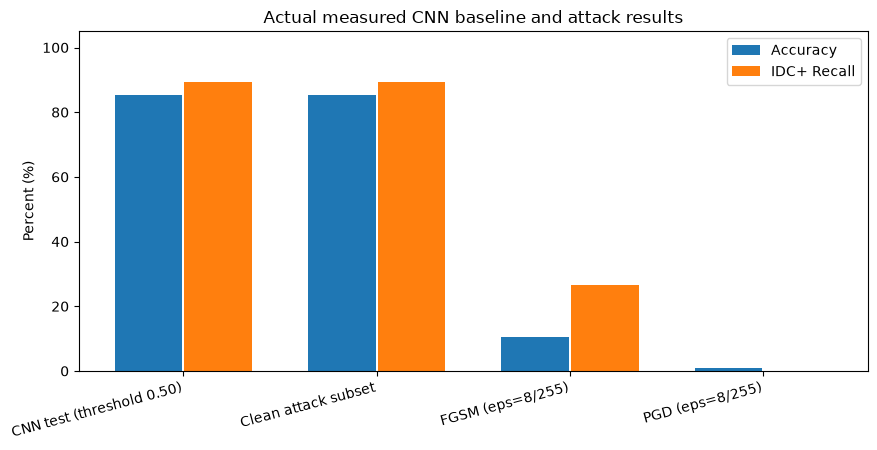

[SUCCESS] Core measured results generated and validated (optional studies audited below).
[SUCCESS] All requested advanced analysis families completed.
[SUCCESS] Completion marker: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\RUN_PROGRESS.json


In [48]:

print("=" * 74)
print("IDC ROBUSTNESS | FINAL CHECK")
print("RUN_PROFILE:", RUN_PROFILE, "| DEVICE:", DEVICE)
print("DATA_ROOT:", DATA_ROOT)
print("RESULTS_DIR:", RESULTS_DIR)

if not ANALYSIS_ENABLED:
    if RUN_STAGE in ("baseline_only", "split_stability"):
        print(f"STAGE COMPLETED ({RUN_STAGE}): full analysis was intentionally skipped.")
        print("Baseline checkpoints and stage-specific results are available in:", RESULTS_DIR)
    else:
        print("RECOVERY ONLY: no compatible baseline weights; no dependent metrics were generated.")
        print("Select quick_train to authorize a small new training run.")
else:
    required = {
        "Baseline metrics": RESULTS_DIR / "baseline_model_comparison.csv",
        "Test predictions": RESULTS_DIR / "test_predictions_cnn.csv",
        "FGSM/PGD metrics": RESULTS_DIR / "FGSM_PGD_epsilon_sweep.csv",
        "Final metadata": RESULTS_DIR / "final_run_summary.json",
        "CNN checkpoint": Path(checkpoint_paths["cnn"]),
        "Confusion matrix/ROC figure": RESULTS_DIR / "diagnostic_cnn.png",
        "Attack robustness figure": RESULTS_DIR / "attack_epsilon_accuracy_FNR.png",
    }
    if RUN_PGD_CONVERGENCE:
        required["PGD convergence study"] = RESULTS_DIR / "PGD_CONVERGENCE_STRENGTH.csv"
        required["PGD convergence figure"] = RESULTS_DIR / "PGD_CONVERGENCE_STRENGTH.png"
    if RUN_PAIRED_BOOTSTRAP:
        required["Paired patient-cluster attack confidence intervals"] = RESULTS_DIR / "paired_patient_CI_attack_minus_clean.csv"
    if RUN_EXTERNAL_VALIDATION:
        required["External-cohort metrics"] = RESULTS_DIR / "EXTERNAL_independent_cohort_metrics.csv"
    for model_name in BASELINE_MODELS:
        required[f"Test predictions: {model_name}"] = RESULTS_DIR / f"test_predictions_{model_name}.csv"
        required[f"Diagnostic figure: {model_name}"] = RESULTS_DIR / f"diagnostic_{model_name}.png"
        required[f"Checkpoint: {model_name}"] = Path(checkpoint_paths[model_name])
    if RUN_CALIBRATION:
        required["Temperature calibration"] = RESULTS_DIR / "calibration_temperature_scaling.csv"
    if RUN_ATTACK_CALIBRATION:
        required["Attack calibration"] = RESULTS_DIR / "adversarial_calibration_and_confident_errors.csv"
    if RUN_COST_SCENARIOS:
        required["Validation cost scenarios"] = RESULTS_DIR / "validation_selected_hypothetical_cost_scenarios.csv"
    if RUN_FN_FLIP_ANALYSIS:
        required["Attack-induced FN analysis"] = RESULTS_DIR / "attack_induced_false_negative_flips.csv"
    required["Patient-specific PGD heterogeneity"] = RESULTS_DIR / "patient_pgd_heterogeneity.csv"
    required["Robustness epsilon integral"] = RESULTS_DIR / "robustness_auc_epsilon_integral.csv"
    if RUN_DEFENSE:
        required["Defense time/effectiveness"] = RESULTS_DIR / "defense_effectiveness_and_training_cost.csv"
    if RUN_TRANSFERABILITY and len(model_dict) >= 2:
        required["Cross-model transferability"] = RESULTS_DIR / "cross_model_attack_transferability.csv"
        required["Transferability heatmap"] = RESULTS_DIR / "cross_model_attack_transferability_heatmap.png"
    if RUN_DEFENSE:
        required["Defense accuracy/recall tradeoff"] = RESULTS_DIR / "defense_clean_vs_adversarial_training.csv"
        required["Defense figure"] = RESULTS_DIR / "defense_tradeoff.png"
        if RUN_PAIRED_BOOTSTRAP:
            required["Paired defense confidence intervals"] = RESULTS_DIR / "paired_patient_bootstrap_defense_differences.csv"
    if RUN_EXTRA_ANALYSES:
        required["Strong PGD results"] = RESULTS_DIR / "strong_PGD_steps_restarts.csv"
        required["Brightness/contrast sensitivity"] = RESULTS_DIR / "brightness_contrast_corruption.csv"
        for model_name in BASELINE_MODELS:
            required[f"Grad-CAM: {model_name}"] = RESULTS_DIR / f"gradcam_clean_attack_{model_name}.png"
    for flag, label, filename in (
        (RUN_TARGETED_ATTACK,"Targeted FN attack","targeted_positive_to_negative_summary.csv"),
        (RUN_SPATIAL_MAPPING,"Spatial error mapping","spatial_clean_vs_pgd_patch_outcomes.csv"),
        (RUN_STAIN_SENSITIVITY,"Approximate stain sensitivity","approximate_he_shift_robustness.csv"),
        (RUN_DEEPFOOL,"DeepFool","deepfool_L2_optional.csv"),
        (RUN_AUTOATTACK,"AutoAttack attempt and status","autoattack_optional.csv"),
    ):
        if flag: required[label] = RESULTS_DIR / filename
    print("Required artifacts:", len(required))
    missing = [name for name, path in required.items() if not path.is_file()]
    if missing:
        raise RuntimeError("RESULTS NOT COMPLETE: " + ", ".join(missing) + ". Inspect earlier cells.")
    # Results must come from THIS run; a previously saved model checkpoint is allowed.
    stale = [label for label, p in required.items() if Path(p).suffix.lower() != ".pt"
             and p.stat().st_mtime < RUN_STARTED_AT - 5]
    if stale:
        raise RuntimeError("Old results found, not generated in this run: " + ", ".join(stale))

    baselines = pd.read_csv(required["Baseline metrics"])
    attacks = pd.read_csv(required["FGSM/PGD metrics"])
    predictions = pd.read_csv(required["Test predictions"])
    baseline = baselines[(baselines["model"] == "cnn") & (baselines["threshold_rule"] == "default_0.50")]
    subset = attacks[attacks["model"] == "cnn"]
    attack_names = set(subset["attack"].astype(str))
    assert len(baseline) == 1, "Exactly one CNN default-threshold baseline metric row is required."
    assert {"Clean", "FGSM", "PGD"}.issubset(attack_names), f"Missing expected attacks: {attack_names}"
    assert len(predictions) > 0 and len(subset) >= 3, "No prediction or attack data rows found."
    if not set(BASELINE_MODELS).issubset(set(baselines.model)):
        raise RuntimeError("At least one configured model is absent from baseline results")
    if not set(BASELINE_MODELS).issubset(set(attacks.model)):
        raise RuntimeError("At least one configured model is absent from attack results")
    for frame in [baseline, subset]:
        assert np.isfinite(frame["accuracy"].to_numpy(dtype=float)).all(), "Non-finite accuracy detected."
        assert frame["accuracy"].between(0, 1).all(), "Accuracy outside [0,1]."
    assert predictions["p"].between(0, 1).all(), "Predicted probabilities outside [0,1]."

    clean_row = subset[subset["attack"] == "Clean"].iloc[0]
    fgsm_row = subset[subset["attack"] == "FGSM"].sort_values("epsilon").iloc[-1]
    pgd_row = subset[subset["attack"] == "PGD"].sort_values("epsilon").iloc[-1]
    cmp_rows = pd.DataFrame([
        {"Evaluation": "CNN test (threshold 0.50)", "N": int(baseline.iloc[0]["n"]),
         "Accuracy": float(baseline.iloc[0]["accuracy"]), "Recall": float(baseline.iloc[0]["recall"]),
         "F1": float(baseline.iloc[0]["f1"]), "ROC-AUC": float(baseline.iloc[0]["roc_auc"])},
        {"Evaluation": "Clean attack subset", "N": int(clean_row["n"]),
         "Accuracy": float(clean_row["accuracy"]), "Recall": float(clean_row["recall"]),
         "F1": float(clean_row["f1"]), "ROC-AUC": float(clean_row["roc_auc"])},
        {"Evaluation": f"FGSM (eps={fgsm_row['epsilon']*255:.0f}/255)", "N": int(fgsm_row["n"]),
         "Accuracy": float(fgsm_row["accuracy"]), "Recall": float(fgsm_row["recall"]),
         "F1": float(fgsm_row["f1"]), "ROC-AUC": float(fgsm_row["roc_auc"])},
        {"Evaluation": f"PGD (eps={pgd_row['epsilon']*255:.0f}/255)", "N": int(pgd_row["n"]),
         "Accuracy": float(pgd_row["accuracy"]), "Recall": float(pgd_row["recall"]),
         "F1": float(pgd_row["f1"]), "ROC-AUC": float(pgd_row["roc_auc"])},
    ])
    display(cmp_rows.round(4))
    summary_csv=RESULTS_DIR/"FINAL_RESULTS_OVERVIEW.csv"
    cmp_rows.to_csv(summary_csv, index=False, encoding="utf-8-sig")

    fig, ax = plt.subplots(figsize=(9, 4.6))
    x = np.arange(len(cmp_rows))
    ax.bar(x-0.18, cmp_rows["Accuracy"]*100, 0.35, label="Accuracy")
    ax.bar(x+0.18, cmp_rows["Recall"]*100, 0.35, label="IDC+ Recall")
    ax.set_xticks(x, cmp_rows["Evaluation"], rotation=15, ha="right")
    ax.set_ylim(0, 105)
    ax.set_ylabel("Percent (%)")
    ax.set_title("Actual measured CNN baseline and attack results")
    ax.legend()
    fig.tight_layout()
    overview_png=RESULTS_DIR/"FINAL_RESULTS_OVERVIEW.png"
    fig.savefig(overview_png, dpi=170)
    plt.show()
    plt.close(fig)
    completed={
        "status": "CORE_RESULTS_GENERATED_PENDING_FINAL",
        "run_profile": RUN_PROFILE, "quick_test_only": MODE == "quick", "dataset_root": str(DATA_ROOT),
        "experiment_id": EXPERIMENT_ID, "selected_models": BASELINE_MODELS, "all_requested_suite": bool(RUN_ALL_REQUESTED),
        "autoattack_binary_custom_not_standard": bool(RUN_AUTOATTACK),
        "transferability_evaluated": bool(RUN_TRANSFERABILITY and len(model_dict)>=2),
        "baseline_rows": int(len(baselines)), "attack_rows": int(len(attacks)),
        "test_predictions": int(len(predictions)), "checkpoint": str(required["CNN checkpoint"]),
        "results_dir": str(RESULTS_DIR), "overview_csv": str(summary_csv),
        "overview_png": str(overview_png),
    }
    completion_file = RESULTS_DIR / "RUN_PROGRESS.json"
    completion_file.write_text(json.dumps(completed, indent=2, ensure_ascii=False), encoding="utf-8")
    print("[SUCCESS] Core measured results generated and validated (optional studies audited below).")
    if RUN_ALL_REQUESTED:
        if RUN_TRANSFERABILITY and len(model_dict)<2:
            raise RuntimeError("Transferability requires two evaluated models")
        all_seven_requested=all((RUN_DEFENSE,RUN_TARGETED_ATTACK,RUN_SPATIAL_MAPPING,
            RUN_STAIN_SENSITIVITY,RUN_DEEPFOOL,RUN_AUTOATTACK,RUN_EXTRA_ANALYSES,RUN_TRANSFERABILITY))
        optional_csv=RESULTS_DIR/"optional_attack_execution_status.csv"
        optional_records=pd.read_csv(optional_csv) if optional_csv.is_file() else pd.DataFrame()
        aa_rows=optional_records[optional_records.analysis=="AutoAttack_binary_custom"] if not optional_records.empty else pd.DataFrame()
        aa_complete=bool(not aa_rows.empty and aa_rows.status.eq("COMPLETED").all()) if RUN_AUTOATTACK else False
        completed["all_7_families_completed"] = bool(all_seven_requested and aa_complete)
        completed["autoattack_status"] = ("COMPLETED" if aa_complete else
                                         "SKIPPED_OR_FAILED" if RUN_AUTOATTACK else "NOT_REQUESTED")
        completed["status"] = "CORE_RESULTS_GENERATED_PENDING_FINAL"
        completion_file.write_text(json.dumps(completed,indent=2,ensure_ascii=False),encoding="utf-8")
        if all_seven_requested and aa_complete:
            print("[SUCCESS] All requested advanced analysis families completed.")
        elif RUN_AUTOATTACK and not aa_complete:
            print("[PARTIAL] AutoAttack was requested but did not complete; see optional_attack_execution_status.csv.")
        else:
            print("[SUCCESS] Enabled analyses completed; disabled optional analyses were not claimed as executed.")
    print("[SUCCESS] Completion marker:", completion_file)
    if MODE == "quick":
        print("IMPORTANT: QUICK uses limited patches; not valid as final full-data research claims.")
print("=" * 74)


## 14. Result-file integrity and research readiness

In [49]:
# Require result files only for the analyses enabled in this run.
if ANALYSIS_ENABLED:
    required_v6 = {
        "Baseline class collapse audit": "baseline_class_collapse_and_readiness.csv",
        "Class-wise attack robustness": "classwise_attack_robustness.csv",
        "Patient IDC+ recall support": "patient_positive_recall_and_support.csv",
        "Full/partial execution marker": "RUN_PROGRESS.json",
        "Final result table": "FINAL_RESULTS_OVERVIEW.csv",
    }
    if RUN_CALIBRATION:
        required_v6["Calibration delta audit"] = "calibration_before_after_metric_disagreement.csv"
    if RUN_DEFENSE:
        required_v6["Defense quality audit"] = "defense_evidence_quality.csv"
    missing_v6=[name for name, rel in required_v6.items() if not (RESULTS_DIR/rel).is_file()]
    if missing_v6:
        raise RuntimeError("V6 output audit failed; missing: " + ", ".join(missing_v6))
    baseline_issues=baseline_readiness_table.warnings.fillna("").tolist()
    positive_collapse=any("IDC_POSITIVE_RECALL_COLLAPSE" in x for x in baseline_issues)
    eligible_attack_rows=int((classwise_attack_table.clean_correct_positive_n >= MIN_CLEAN_CORRECT_POSITIVE_N).sum())
    aa_status="NOT_REQUESTED"
    aa_file=RESULTS_DIR/"optional_attack_execution_status.csv"
    if RUN_AUTOATTACK:
        aa_status="NOT_COMPLETED"
        if aa_file.is_file():
            aa_report=pd.read_csv(aa_file)
            aa_rows=aa_report[aa_report.analysis == "AutoAttack_binary_custom"]
            if not aa_rows.empty and aa_rows.status.eq("COMPLETED").all():
                aa_status="COMPLETED_CUSTOM_NOT_STANDARD"
            elif not aa_rows.empty:
                aa_status=";".join(sorted(set(aa_rows.status.astype(str))))
    evidence={
        "run_profile":RUN_PROFILE,
        "pipeline_outputs_checked":True,
        "research_ready":bool(MODE=="full" and not positive_collapse and eligible_attack_rows>0
                              and (not RUN_AUTOATTACK or aa_status=="COMPLETED_CUSTOM_NOT_STANDARD")),
        "smoke_test_only":bool(MODE=="quick"),
        "baseline_idc_positive_recall_collapse_at_0p5":bool(positive_collapse),
        "attack_rows_with_min_clean_correct_positive_support":eligible_attack_rows,
        "autoattack_status":aa_status,
        "full_attack_sample_limit":FULL_ATTACK_SAMPLE_LIMIT,
        "repeat_train_seeds": [int(TRAIN_SEED)] + list(map(int, REPEAT_MODEL_SEEDS)),
        "limitations":"Passing automatic checks does not establish clinical suitability or external validity."
    }
    (RESULTS_DIR/"SCIENTIFIC_READINESS.json").write_text(
        json.dumps(evidence,indent=2,ensure_ascii=False,default=str),encoding="utf-8")
    marker=RESULTS_DIR/"RUN_PROGRESS.json"
    completion=json.loads(marker.read_text(encoding="utf-8"))
    completion["scientific_readiness"] = "PRELIMINARY_ONLY" if not evidence["research_ready"] else "ELIGIBLE_FOR_MANUAL_SCIENTIFIC_REVIEW"
    completion["autoattack_actual_status"] = aa_status
    completion["baseline_idc_positive_recall_collapse"] = bool(positive_collapse)
    marker.write_text(json.dumps(completion,indent=2,ensure_ascii=False,default=str),encoding="utf-8")
    display(pd.DataFrame([evidence]))
    if MODE=="quick":
        print("[SMOKE COMPLETE] All enabled code paths and results are checked; numbers are NOT research evidence.")
    elif positive_collapse:
        print("[INCONCLUSIVE] Full run executed, but IDC+ recall collapsed for a model.")
    elif aa_status not in ("NOT_REQUESTED","COMPLETED_CUSTOM_NOT_STANDARD"):
        print("[PARTIAL] Advanced results generated, but requested AutoAttack did not complete.")
    else:
        print("[RUN COMPLETE] Inspect uncertainty, sample sizes, weak-attack artifacts, and external validity before publication.")
    print("Results:",RESULTS_DIR)
else:
    print(f"[NO FULL ANALYSIS] stage={RUN_STAGE}; inspect stage-specific outputs if applicable.")


,run_profile,pipeline_outputs_checked,research_ready,smoke_test_only,baseline_idc_positive_recall_collapse_at_0p5,attack_rows_with_min_clean_correct_positive_support,autoattack_status,full_attack_sample_limit,repeat_train_seeds,limitations
0,all_research,True,True,False,False,21,COMPLETED_CUSTOM_NOT_STANDARD,None,"[42, 43, 44]",Passing automatic checks does not establish cl...


[RUN COMPLETE] Inspect uncertainty, sample sizes, weak-attack artifacts, and external validity before publication.
Results: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results


### Scientific-readiness criteria

In [50]:
# Scientific readiness is an audit for manual review, not clinical validation.
if ANALYSIS_ENABLED:
    imports=pd.read_csv(RESULTS_DIR/"optional_attack_execution_status.csv") if (RESULTS_DIR/"optional_attack_execution_status.csv").is_file() else pd.DataFrame()
    aa_rows=imports[imports.analysis=="AutoAttack_binary_custom"] if not imports.empty else pd.DataFrame()
    aa_ok=bool(not RUN_AUTOATTACK or (not aa_rows.empty and aa_rows.status.eq("COMPLETED").all()))
    full_test=manifest[manifest.split=="test"]
    baseline_sufficient={model: {
        "positive_n":int((baseline_predictions[model]["test"].y==1).sum()),
        "positive_recall_0p5":float(binary_scores(baseline_predictions[model]["test"].y,baseline_predictions[model]["test"].p)["recall"]),
        "positive_recall_frozen_validation_F1":float(binary_scores(
            baseline_predictions[model]["test"].y, baseline_predictions[model]["test"].p,
            float(frozen_thresholds[model]["validation_F1"]))["recall"]),
        "n_patients":int(baseline_predictions[model]["test"].patient_id.nunique()),
        "sufficient":bool((baseline_predictions[model]["test"].y==1).sum()>=MIN_RESEARCH_IDC_POSITIVE_N
                          and baseline_predictions[model]["test"].patient_id.nunique()>=MIN_RESEARCH_PATIENT_N)}
        for model in model_dict}
    coverage=float(len(attack_subset)/max(len(full_test),1))
    checks={
        "full_mode":MODE=="full",
        "three_primary_models":set(("cnn", "resnet18_pretrained", "mobilenetv3_small_pretrained")).issubset(model_dict),
        "no_positive_class_collapse":all(v["positive_recall_frozen_validation_F1"]>0 for v in baseline_sufficient.values()),
        "baseline_positive_patient_support":all(v["sufficient"] for v in baseline_sufficient.values()),
        "full_test_attack_coverage":coverage>=0.999,
        "repeated_training_seeds":bool(len(REPEAT_MODEL_SEEDS)>=2 and (RESULTS_DIR/"repeat_all_model_seeds.csv").is_file()),
        "defense_comparison_complete":bool(RUN_DEFENSE and (RESULTS_DIR/"defense_validation_threshold_classwise.csv").is_file()),
        "threshold_attack_comparison_complete":(RESULTS_DIR/"attack_frozen_validation_threshold_comparison.csv").is_file(),
        "transferability_complete":bool(len(model_dict)>=2 and (RESULTS_DIR/"cross_model_attack_transferability.csv").is_file()),
        "autoattack_completed_if_requested":aa_ok,
        "deepfool_success_only_L2_reported":bool(not RUN_DEEPFOOL or (RESULTS_DIR/"deepfool_success_only_l2_summary.csv").is_file()),
    }
    criteria_table=pd.DataFrame([{"criterion":k,"passed":bool(v)} for k,v in checks.items()])
    write_csv(criteria_table,"V7_SCIENTIFIC_READINESS_CRITERIA.csv")
    readiness={"research_ready_for_manual_review":bool(all(checks.values())),
               "execution_pipeline_finished":True,
               "analysis_mode":RUN_PROFILE,
               "attack_test_fraction":coverage,
               "attack_n":len(attack_subset),
               "test_n":len(full_test),
               "per_model_test_support":baseline_sufficient,
               "operational_threshold_policy":"validation_F1_frozen_before_test",
               "default_0p5_collapse_warning_models":[m for m,v in baseline_sufficient.items() if v["positive_recall_0p5"]==0],
               "criteria":checks,
               "caveat":"No evidence here establishes clinical safety, generalization to independent institutions, or standard AutoAttack when a custom suite is used."}
    (RESULTS_DIR/"V7_SCIENTIFIC_READINESS.json").write_text(json.dumps(readiness,indent=2,ensure_ascii=False,default=str),encoding="utf-8")
    marker_path=RESULTS_DIR/"RUN_PROGRESS.json"
    if marker_path.exists():
        marker=json.loads(marker_path.read_text(encoding="utf-8"))
        marker["v7_manual_research_review_eligible"]=readiness["research_ready_for_manual_review"]
        marker["v7_autoattack_status"]="COMPLETED_CUSTOM" if aa_ok else "NOT_COMPLETED"
        marker_path.write_text(json.dumps(marker,indent=2,ensure_ascii=False),encoding="utf-8")
    display(criteria_table)
    print("[V7] Pipeline completed; research-ready for manual review:",readiness["research_ready_for_manual_review"])
    print("[V7] Results directory:",RESULTS_DIR)
else:
    print(f"[READINESS NOT EVALUATED] stage={RUN_STAGE}; full analyses not requested or unavailable.")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\V7_SCIENTIFIC_READINESS_CRITERIA.csv


,criterion,passed
0,full_mode,True
1,three_primary_models,True
2,no_positive_class_collapse,True
3,baseline_positive_patient_support,True
4,full_test_attack_coverage,True
5,repeated_training_seeds,True
6,defense_comparison_complete,True
7,threshold_attack_comparison_complete,True
8,transferability_complete,True
9,autoattack_completed_if_requested,True


[V7] Pipeline completed; research-ready for manual review: True
[V7] Results directory: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results


## 15. Class-wise selective prediction and risk–coverage

Report retained and abstained IDC-positive patches separately.

Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\V9_selective_classwise_coverage.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\V9_selective_patient_bootstrap_CI.csv


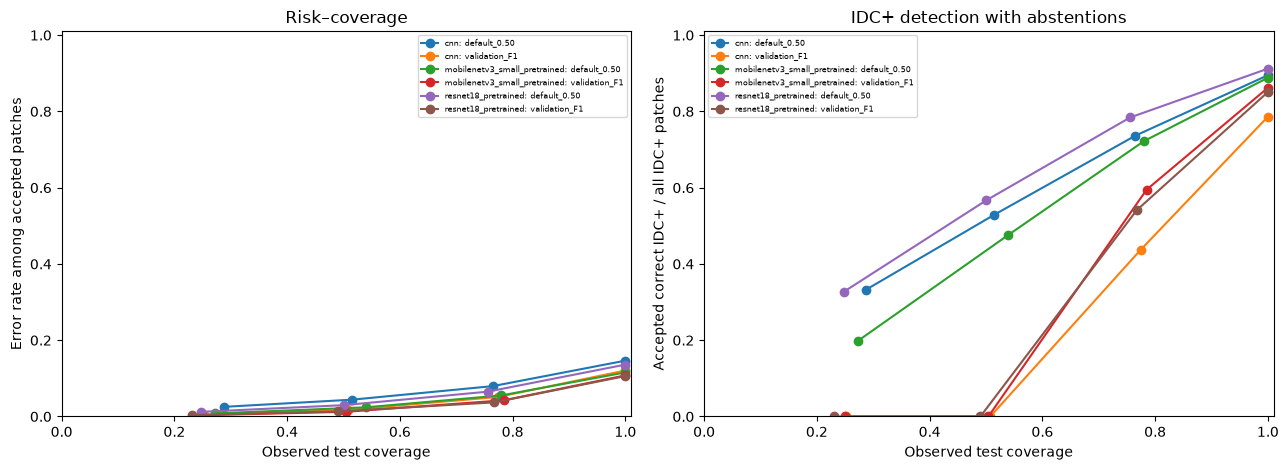

,model,policy,validation_coverage_goal,test_coverage,idc_positive_coverage,selective_risk,positive_detected_overall
0,cnn,default_0.50,0.25,0.287746,0.335383,0.025313,0.333012
1,cnn,default_0.50,0.50,0.515013,0.539830,0.044083,0.529307
2,cnn,default_0.50,0.75,0.764906,0.773694,0.079674,0.736421
3,cnn,default_0.50,1.00,1.000000,1.000000,0.146488,0.894850
4,cnn,validation_F1,0.25,0.252547,0.004668,0.004832,0.000000
5,cnn,validation_F1,0.50,0.507652,0.033716,0.017362,0.000000
6,cnn,validation_F1,0.75,0.774282,0.543016,0.051263,0.437125
7,cnn,validation_F1,1.00,1.000000,1.000000,0.120646,0.786217
8,resnet18_pretrained,default_0.50,0.25,0.248092,0.328788,0.012259,0.327306
9,resnet18_pretrained,default_0.50,0.50,0.500271,0.574657,0.029700,0.566654


In [51]:
# Track abstained positives so selective prediction cannot hide missed IDC cases.
if ANALYSIS_ENABLED and RUN_SELECTIVE_CLASSWISE:
    v9_select_rows=[]; v9_select_ci=[]
    _rng=np.random.default_rng(SPLIT_SEED+912)
    for model_name,sp in baseline_predictions.items():
        val=sp["val"].copy();test=sp["test"].copy()
        for policy in ("default_0.50","validation_F1"):
            op=float(frozen_thresholds[model_name][policy])
            v_margin=np.abs(val.p.to_numpy(dtype=float)-op)
            test_margin=np.abs(test.p.to_numpy(dtype=float)-op)
            for goal in (0.25,0.5,0.75,1.0):
                cutoff=-1.0 if goal==1.0 else float(np.quantile(v_margin,1.0-goal))
                retained=(test_margin>=cutoff)
                truth=test.y.to_numpy(dtype=int);p=test.p.to_numpy(dtype=float)
                pred=(p>=op)
                row={"model":model_name,"policy":policy,"threshold":op,
                     "validation_coverage_goal":goal,"frozen_margin_cutoff":cutoff,
                     "test_n":len(test),"n_retained":int(retained.sum()),"n_abstained":int((~retained).sum()),
                     "test_coverage":float(retained.mean()),"patient_groups":int(test.patient_id.nunique()),
                     "selectivity_measure":"uncalibrated_distance_to_decision_threshold"}
                for cls,category in ((0,"idc_negative"),(1,"idc_positive")):
                    mask=truth==cls;n=int(mask.sum());accepted=retained & mask
                    row[f"{category}_total_n"]=n
                    row[f"{category}_retained_n"]=int(accepted.sum())
                    row[f"{category}_abstained_n"]=int((mask & ~retained).sum())
                    row[f"{category}_coverage"]=float(accepted.sum()/n) if n else np.nan
                    row[f"{category}_accepted_correct_fraction_of_all"]=float((accepted & (pred==truth)).sum()/n) if n else np.nan
                    row[f"{category}_conditional_recall_or_specificity"]=float((pred[accepted]==truth[accepted]).mean()) if accepted.any() else np.nan
                    row[f"{category}_accepted_error_n"]=int((accepted & (pred!=truth)).sum())
                row["selective_risk"]=float((retained & (pred!=truth)).sum()/retained.sum()) if retained.any() else np.nan
                row["selected_accuracy"]=1.0-row["selective_risk"] if retained.any() else np.nan
                row["positive_detected_overall"]=row["idc_positive_accepted_correct_fraction_of_all"]
                row["positive_false_negative_retained_n"]=int((retained & (truth==1) & (~pred)).sum())
                row["positive_false_negative_abstained_n"]=int(((~retained) & (truth==1) & (~pred)).sum())
                v9_select_rows.append(row)
                patients=test.patient_id.to_numpy();unique_patients=np.unique(patients)
                if len(unique_patients)>=2:
                    ids={pid:np.flatnonzero(patients==pid) for pid in unique_patients}
                    for b in range(min(PAIRED_BOOTSTRAP_N,400)):
                        draw=_rng.choice(unique_patients,size=len(unique_patients),replace=True)
                        ix=np.concatenate([ids[pid] for pid in draw])
                        yb=truth[ix];ab=retained[ix];pb=pred[ix]
                        pos=yb==1
                        if not pos.any():continue
                        v9_select_ci.append({"model":model_name,"policy":policy,"goal":goal,"bootstrap":b,
                            "positive_coverage":float((ab & pos).sum()/pos.sum()),
                            "positive_detected_overall":float((ab & pos & pb).sum()/pos.sum())})
    v9_select=pd.DataFrame(v9_select_rows)
    write_csv(v9_select,"V9_selective_classwise_coverage.csv")
    v9_bs=pd.DataFrame(v9_select_ci)
    ci_rows=[]
    if not v9_bs.empty:
        for (model_name,policy,goal),g in v9_bs.groupby(["model","policy","goal"]):
            line={"model":model_name,"policy":policy,"validation_coverage_goal":goal,
                  "n_bootstrap_valid":len(g),"cluster_unit":"patient_id"}
            for metric in ("positive_coverage","positive_detected_overall"):
                line[f"{metric}_ci95_low"]=float(g[metric].quantile(.025))
                line[f"{metric}_ci95_high"]=float(g[metric].quantile(.975))
            ci_rows.append(line)
    write_csv(pd.DataFrame(ci_rows,columns=["model","policy","validation_coverage_goal","n_bootstrap_valid","cluster_unit", "positive_coverage_ci95_low","positive_coverage_ci95_high","positive_detected_overall_ci95_low","positive_detected_overall_ci95_high"]),"V9_selective_patient_bootstrap_CI.csv")
    fig,axes=plt.subplots(1,2,figsize=(13,4.8))
    for (name,policy),g in v9_select.groupby(["model","policy"]):
        g=g.sort_values("test_coverage")
        label=f"{name}: {policy}"
        axes[0].plot(g.test_coverage,g.selective_risk,marker="o",label=label)
        axes[1].plot(g.test_coverage,g.positive_detected_overall,marker="o",label=label)
    axes[0].set(title="Risk–coverage",xlabel="Observed test coverage",ylabel="Error rate among accepted patches")
    axes[1].set(title="IDC+ detection with abstentions",xlabel="Observed test coverage",ylabel="Accepted correct IDC+ / all IDC+ patches")
    for ax in axes:
        ax.set_xlim(0,1.01);ax.set_ylim(0,1.01)
        ax.legend(fontsize=6)
    fig.tight_layout();fig.savefig(RESULTS_DIR/"V9_selective_positive_detection.png",dpi=150);plt.show();plt.close(fig)
    display(v9_select[["model","policy","validation_coverage_goal","test_coverage","idc_positive_coverage","selective_risk","positive_detected_overall"]])


## 16. Corruption dose–response

Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\V9_shift_dose_patch_predictions.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\V9_shift_dose_response.csv


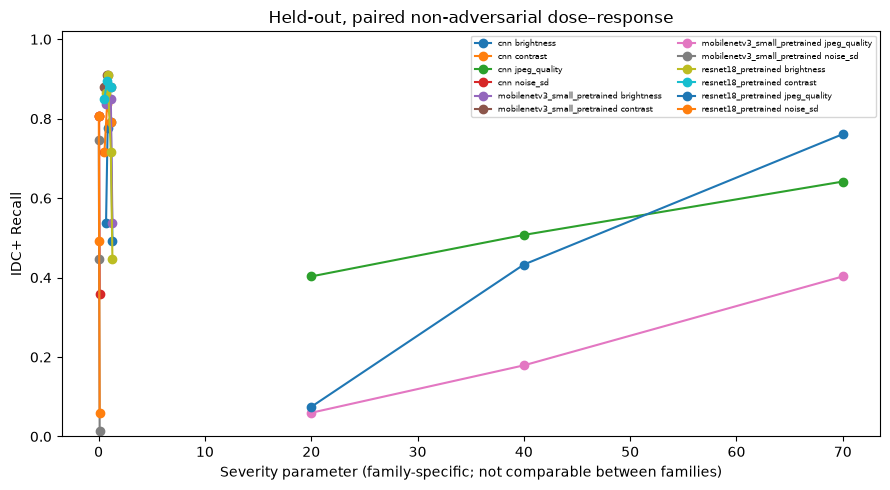

Shift paired rows 10752 and conditions 42


In [52]:
if ANALYSIS_ENABLED and RUN_SHIFT_DOSE_RESPONSE:
    from io import BytesIO
    _dose_subset=choose_subset(manifest,"test",SHIFT_EVAL_N,seed=SPLIT_SEED+811)
    _dose_loader=loader_subset(_dose_subset,batch=min(8,ATTACK_BATCH_SIZE))
    _dose_specs=[("clean",0),
                 *[("brightness",v) for v in (.7,.85,1.15,1.3)],
                 *[("contrast",v) for v in (.55,.8,1.2)],
                 *[("noise_sd",v) for v in (.02,.05,.10)],
                 *[("jpeg_quality",v) for v in (20,40,70)]]
    def v9_corrupt(x,family,strength,ids):
        if family=="clean":return x
        if family=="brightness":return (x*strength).clamp(0,1)
        if family=="contrast":
            mu=x.mean(dim=(-2,-1),keepdim=True)
            return ((x-mu)*strength+mu).clamp(0,1)
        if family=="noise_sd":
            # Identical noise realization per sample ID across severity levels and models.
            base=[]
            for sid in ids.tolist():
                gen=torch.Generator(device="cpu").manual_seed(123470+int(sid))
                base.append(torch.randn(tuple(x.shape[1:]),generator=gen,dtype=x.dtype))
            return (x+strength*torch.stack(base).to(x.device)).clamp(0,1)
        if family=="jpeg_quality":
            out=[]
            for item in x.cpu():
                buf=BytesIO();transforms.functional.to_pil_image(item).save(buf,format="JPEG",quality=int(strength));buf.seek(0)
                with Image.open(buf) as im:out.append(transforms.functional.to_tensor(im.convert("RGB")))
            return torch.stack(out).to(x.device)
        raise ValueError(family)
    _dose_patch=[];_dose_group=[]
    for name,model in model_dict.items():
        op=float(frozen_thresholds[name]["validation_F1"])
        for family,strength in _dose_specs:
            predictions=[]
            for x,y,sid in _dose_loader:
                xx=v9_corrupt(x.to(DEVICE),family,strength,sid)
                model.eval()
                with torch.no_grad():p=torch.softmax(model(xx),dim=1)[:,1].cpu().numpy()
                predictions.extend(zip(sid.tolist(),y.tolist(),p.tolist()))
            df=pd.DataFrame(predictions,columns=["sample_id","y","p"])
            df["model"]=name;df["family"]=family;df["severity"]=strength
            _dose_patch.append(df)
    dose_patch=pd.concat(_dose_patch,ignore_index=True)
    clean_dose=dose_patch[dose_patch.family=="clean"][["model","sample_id","p"]].rename(columns={"p":"clean_p"})
    dose_patch=dose_patch.merge(clean_dose,on=["model","sample_id"],how="left",validate="many_to_one")
    dose_patch=dose_patch.merge(manifest[["sample_id","patient_id"]],on="sample_id",how="left",validate="many_to_one")
    for (name,family,strength),g in dose_patch.groupby(["model","family","severity"],dropna=False):
        op=float(frozen_thresholds[name]["validation_F1"])
        y=g.y.to_numpy(dtype=int);a=(g.p.to_numpy()>=op);c=(g.clean_p.to_numpy()>=op)
        positive=y==1
        new_fn=positive & c & ~a
        reverse_fn=positive & ~c & a
        _dose_group.append({"model":name,"family":family,"severity":strength,"threshold_policy":"validation_F1",
             "n":len(g),"patients":int(g.patient_id.nunique()),"positive_n":int(positive.sum()),
             "clean_correct_positive_n":int((positive & c).sum()),"new_false_negatives":int(new_fn.sum()),
             "fn_recovered_by_shift":int(reverse_fn.sum()),
             "new_fn_fraction_eligible":float(new_fn.sum()/(positive & c).sum()) if (positive & c).any() else np.nan,
             "mean_delta_p":float((g.p-g.clean_p).mean()),**binary_scores(y,g.p,op)})
    dose_summary=pd.DataFrame(_dose_group)
    write_csv(dose_patch,"V9_shift_dose_patch_predictions.csv")
    write_csv(dose_summary,"V9_shift_dose_response.csv")
    fig,ax=plt.subplots(figsize=(9,5))
    for (name,family),g in dose_summary[dose_summary.family!="clean"].groupby(["model","family"]):
        ax.plot(g.severity,g.recall,marker="o",label=f"{name} {family}")
    ax.set(xlabel="Severity parameter (family-specific; not comparable between families)",ylabel="IDC+ Recall",ylim=(0,1.02),title="Held-out, paired non-adversarial dose–response")
    ax.legend(fontsize=6,ncol=2);fig.tight_layout();fig.savefig(RESULTS_DIR/"V9_shift_dose_response.png",dpi=155);plt.show();plt.close(fig)
    print("Shift paired rows",len(dose_patch),"and conditions",len(dose_summary))


## 17. High-confidence false negatives

In [53]:
# A high-confidence false negative is a serious model error, not a diagnosis.
if ANALYSIS_ENABLED and RUN_HIGH_CONFIDENCE_FN:
    hc_frames=[]
    for name,pair in baseline_predictions.items():
        t=pair["test"].copy();t["model"]=name;t["condition"]="clean_full_test";t["family"]="clean"
        hc_frames.append(t)
    for key,df in attack_prediction_frames.items():
        if "_PGD_8_255" not in key:continue
        name=next((m for m in model_dict if key.startswith(m+"_")),None)
        if name is None:continue
        t=df.copy();t["model"]=name;t["condition"]="pgd_8_255_attack_subset";t["family"]="adversarial"
        hc_frames.append(t)
    if RUN_SHIFT_DOSE_RESPONSE and "dose_patch" in globals():
        for (name,family,strength),g in dose_patch.groupby(["model","family","severity"]):
            if family=="clean":continue
            t=g.copy();t["condition"]=f"shift_{family}_{strength}";t["family"]="synthetic_shift"
            hc_frames.append(t)
    hc_rows=[];hc_pat=[]
    for frame in hc_frames:
        name=str(frame.model.iloc[0]);condition=str(frame.condition.iloc[0]);family=str(frame.family.iloc[0])
        op=float(frozen_thresholds[name]["validation_F1"])
        y=frame.y.to_numpy(dtype=int);p=frame.p.to_numpy(dtype=float)
        is_fn=(y==1)&(p<op)
        is_hc=is_fn & ((1-p)>=HIGH_CONFIDENCE_NEGATIVE)
        hc_rows.append({"model":name,"condition":condition,"family":family,"threshold":op,
             "negative_probability_cutoff":HIGH_CONFIDENCE_NEGATIVE,"n":len(frame),
             "positive_n":int((y==1).sum()),"false_negative_n":int(is_fn.sum()),"high_confidence_false_negative_n":int(is_hc.sum()),
             "high_confidence_fn_rate_all_positive":float(is_hc.sum()/(y==1).sum()) if (y==1).any() else np.nan,
             "high_confidence_fn_fraction_of_fn":float(is_hc.sum()/is_fn.sum()) if is_fn.any() else np.nan,
             "interpretation":"raw_softmax_negative_confidence_not_calibrated"})
        if is_hc.any():
            g=frame.iloc[np.flatnonzero(is_hc)].copy()
            hc_pat.append(g[["model","sample_id","patient_id","y","p","condition","family"]])
    hc_table=pd.DataFrame(hc_rows)
    write_csv(hc_table,"V9_high_confidence_false_negatives.csv")
    hc_examples=pd.concat(hc_pat,ignore_index=True) if hc_pat else pd.DataFrame(columns=["model","sample_id","patient_id","y","p","condition","family"])
    write_csv(hc_examples,"V9_high_confidence_FN_examples.csv")
    display(hc_table[["model","condition","positive_n","false_negative_n","high_confidence_false_negative_n"]].head(20))


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\V9_high_confidence_false_negatives.csv
Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\V9_high_confidence_FN_examples.csv


,model,condition,positive_n,false_negative_n,high_confidence_false_negative_n
0,cnn,clean_full_test,13495,2885,199
1,resnet18_pretrained,clean_full_test,13495,2014,185
2,mobilenetv3_small_pretrained,clean_full_test,13495,1861,404
3,cnn,pgd_8_255_attack_subset,13495,13495,13460
4,resnet18_pretrained,pgd_8_255_attack_subset,13495,13495,13495
5,mobilenetv3_small_pretrained,pgd_8_255_attack_subset,13495,13495,13495
6,cnn,shift_brightness_0.7,67,31,3
7,cnn,shift_brightness_0.85,67,15,0
8,cnn,shift_brightness_1.15,67,14,1
9,cnn,shift_brightness_1.3,67,34,4


## 18. Independent patient-split stability

Alternative splits require independent retraining and must not be combined with the primary test results.

In [54]:
# Retrain on alternative patient splits independently of the primary test split.
if RUN_STAGE in ("split_stability", "all"):
    if RUN_PROFILE!="all_research" and RUN_PROFILE!="all_smoke":
        raise ValueError("split_stability stage expects all_research (or all_smoke only for smoke checks)")
    if MODE=="quick":
        split_models=["cnn"]
        alt_seeds=GROUPED_SPLIT_SEEDS[:1]
    else:
        split_models=[m for m in GROUPED_SPLIT_MODELS if m in BASELINE_MODELS]
        alt_seeds=GROUPED_SPLIT_SEEDS
    if not split_models:raise ValueError("No selected split-stability model in BASELINE_MODELS")
    _orig_manifest,_orig_id,_orig_vl,_orig_tl=manifest,MANIFEST_ID,val_loader,test_loader
    split_results=[];split_details=[]
    try:
        for seed in alt_seeds:
            alt_full=patient_split(images,seed=int(seed))
            validate_splits(alt_full)
            alt=alt_full.reset_index(drop=True) if MODE=="full" else subsample_for_quick(alt_full)
            validate_splits(alt)
            alt=alt.reset_index(drop=True);alt["sample_id"]=np.arange(len(alt))
            alt_idrows=alt[["relative_path","patient_id","label","split","bytes","mtime_ns"]].sort_values("relative_path")
            alt_id=hashlib.sha256(alt_idrows.to_csv(index=False).encode()).hexdigest()[:16]
            manifest=alt;MANIFEST_ID=alt_id
            val_loader=loader_for(manifest,"val");test_loader=loader_for(manifest,"test")
            for model_name in split_models:
                model,path=train_baseline(model_name,seed=TRAIN_SEED)
                val=predict_frame(model,val_loader)
                test=predict_frame(model,test_loader)
                operating=validation_thresholds(val)["validation_F1"]
                outcome=binary_scores(test.y,test.p,operating)
                split_results.append({"split_seed":seed,"model":model_name,"manifest_id":alt_id,
                    "train_patients":int(alt.loc[alt.split=="train","patient_id"].nunique()),
                    "test_patients":int(test.patient_id.nunique()),"test_positive_n":int((test.y==1).sum()),
                    "frozen_validation_threshold":operating,"checkpoint":str(path),**outcome})
                split_details.append(test.assign(split_seed=seed,model=model_name,threshold=operating))
                print(f"[ALTERNATE GROUPED SPLIT] seed={seed} model={model_name} test_n={len(test)} recall={outcome['recall']:.3f}")
    finally:
        manifest,MANIFEST_ID,val_loader,test_loader=_orig_manifest,_orig_id,_orig_vl,_orig_tl
    split_table=pd.DataFrame(split_results)
    if split_table.empty:raise RuntimeError("No alternate split completed")
    write_csv(split_table,"V9_grouped_split_retraining_results.csv")
    write_csv(pd.concat(split_details,ignore_index=True),"V9_grouped_split_heldout_predictions.csv")
    split_summary=split_table.groupby("model").agg(repeated_splits=("split_seed","nunique"),accuracy_mean=("accuracy","mean"),accuracy_std=("accuracy","std"),positive_recall_mean=("recall","mean"),positive_recall_std=("recall","std")).reset_index()
    write_csv(split_summary,"V9_grouped_split_stability_summary.csv")
    split_stage={"stage":"split_stability","status":"COMPLETED","completed_split_seeds":list(map(int,alt_seeds)),
            "models":split_models,"separate_splits_are_not_original_test_comparisons":True,"smoke_only":MODE=="quick"}
    (RESULTS_DIR/"V9_STAGE_SPLIT_STABILITY.json").write_text(json.dumps(split_stage,indent=2),encoding="utf-8")
    write_stage_activity("COMPLETED",stage="split_stability",details=split_stage)
    display(split_summary)


Compatible checkpoint found: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\checkpoints\baseline_cnn_f8b9d178576749f8.pt
[cnn] Checkpoint reused; no training performed.
[ALTERNATE GROUPED SPLIT] seed=52 model=cnn test_n=40079 recall=0.819
Compatible checkpoint found: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\checkpoints\baseline_resnet18_pretrained_ebd3cd255fc933cb.pt
[resnet18_pretrained] Checkpoint reused; no training performed.
[ALTERNATE GROUPED SPLIT] seed=52 model=resnet18_pretrained test_n=40079 recall=0.808
Compatible checkpoint found: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\checkpoints\baseline_mobilenetv3_small_pretrained_3314d7a1fa15cb98.pt
[mobilenetv3_small_pretrained] Checkpoint reused; no training performed.
[ALTERNATE GROUPED SPLIT] seed=52 model=mobilenetv3_small_pretrained test_n=40079 recall=0.816
Compatible checkpoint found: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\chec

,model,repeated_splits,accuracy_mean,accuracy_std,positive_recall_mean,positive_recall_std
0,cnn,2,0.892712,0.001482,0.805140,0.020215
1,mobilenetv3_small_pretrained,2,0.888173,0.001832,0.820001,0.006221
2,resnet18_pretrained,2,0.892655,0.002036,0.807358,0.000963


## 19. Paired patient-level corruption intervals

In [55]:
if ANALYSIS_ENABLED and RUN_SHIFT_DOSE_RESPONSE:
    shift_boot_rows=[]
    # Matched patient-cluster bootstrap: same images under clean and shift, resampled by patient group.
    rng=np.random.default_rng(SPLIT_SEED+2026)
    for (name,family,severity),g in dose_patch.groupby(["model","family","severity"]):
        if family=="clean":continue
        op=float(frozen_thresholds[name]["validation_F1"])
        patient_groups={pid:part for pid,part in g.groupby("patient_id")}
        patient_ids=np.asarray(list(patient_groups.keys()))
        if len(patient_ids)<2:continue
        for draw_id in range(min(PAIRED_BOOTSTRAP_N,250)):
            sampled=rng.choice(patient_ids,size=len(patient_ids),replace=True)
            selected=pd.concat([patient_groups[pid] for pid in sampled],ignore_index=True)
            y=selected.y.to_numpy(dtype=int)
            pos=y==1
            if not pos.any():continue
            after=selected.p.to_numpy()>=op
            before=selected.clean_p.to_numpy()>=op
            shift_boot_rows.append({"model":name,"family":family,"severity":severity,"bootstrap":draw_id,
                "delta_idc_recall":float(after[pos].mean()-before[pos].mean()),
                "new_fn_rate_all_idc_positive":float((pos & before & ~after).sum()/pos.sum()),
                "bootstrap_unit":"patient_id"})
    ci_rows=[]
    df=pd.DataFrame(shift_boot_rows)
    if not df.empty:
        for (name,family,severity),g in df.groupby(["model","family","severity"]):
            ci_rows.append({"model":name,"family":family,"severity":severity,
                 "valid_patient_bootstrap_draws":len(g),
                 "delta_idc_recall_ci95_low":float(g.delta_idc_recall.quantile(.025)),
                 "delta_idc_recall_ci95_high":float(g.delta_idc_recall.quantile(.975)),
                 "new_fn_rate_ci95_low":float(g.new_fn_rate_all_idc_positive.quantile(.025)),
                 "new_fn_rate_ci95_high":float(g.new_fn_rate_all_idc_positive.quantile(.975)),
                 "interpretation":"patient_cluster_bootstrap_of_paired_synthetic_corruptions"})
    expected_cols=["model","family","severity","valid_patient_bootstrap_draws","delta_idc_recall_ci95_low","delta_idc_recall_ci95_high","new_fn_rate_ci95_low","new_fn_rate_ci95_high","interpretation"]
    shift_ci=pd.DataFrame(ci_rows,columns=expected_cols)
    write_csv(shift_ci,"V9_shift_patient_bootstrap_CI.csv")
    print("[V9] Patient-paired shift CI rows:",len(shift_ci)," | no CI can be claimed for insufficient patient support")


Saved: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\V9_shift_patient_bootstrap_CI.csv
[V9] Patient-paired shift CI rows: 39  | no CI can be claimed for insufficient patient support


### Independent submission-focused attack validation — frozen thresholds

**Purpose:** test for label leaking, gradient masking, numerical faults and underpowered attacks. This *supplementary* matched subset runs separately from the 51,622-patch primary attack sweep. It uses the validation-F1 threshold that was already frozen, checks both positive and negative patches, and records per-group observations. The defense comparison is not considered verified solely because FGSM accuracy rises: FGSM-training accuracy higher than clean accuracy while PGD collapses is a red flag, not a successful defense.

The stronger evaluation uses CE-PGD, a **threshold-aware binary-logit margin PGD**, FGSM and a per-patch worst-of ensemble, including the clean image as a candidate. The maximum attack succeeds only if it changes the **frozen decision policy**; report a denominator of clean-correct patches for attack success. Reassess PGD defense using the custom binary AutoAttack reference subset of at least 256 images; no claim of official standard four-attack AutoAttack is made.

In [56]:
# Independent verification uses models and thresholds from this run, never test-set tuning.
if ANALYSIS_ENABLED and RUN_SUBMISSION_VALIDATION and RUN_STAGE in ("all", "analyses"):
    seed_everything(20261102)  # Deterministic supplementary PGD restarts; baseline weights unchanged.
    _strong_sub = choose_subset(manifest, "test", SUBMISSION_VALIDATION_N, seed=SPLIT_SEED + 912)
    _strong_loader = loader_subset(_strong_sub, batch=min(ATTACK_BATCH_SIZE, 16))
    _verification_targets = [(key, model, float(frozen_thresholds[key]["validation_F1"]))
                             for key, model in model_dict.items()]
    if RUN_DEFENSE:
        for key in ("clean_control", "fgsm_training", "pgd_training"):
            _verification_targets.append((key, defense_models[key],
                float(defense_frozen_thresholds[key]["validation_F1"])))

    def _threshold_margin(logits, y, threshold):
        # Larger value = more incorrect w.r.t. frozen validation-only threshold.
        p = float(np.clip(threshold, 1e-5, 1-1e-5))
        threshold_logodds = np.log(p / (1-p))
        binary_logit = logits[:, 1] - logits[:, 0]
        return (1.0 - 2.0*y.float()) * (binary_logit - threshold_logodds)

    def _pgd_margin_verification(model, x, y, threshold, eps, steps, restarts):
        x0 = x.detach()
        with torch.no_grad():
            best = x0.clone()
            best_obj = _threshold_margin(model(best), y, threshold)
        alpha = max(2*eps/max(steps, 1), 1/255)
        gradient_abs_max = 0.0
        gradient_finite = True
        # Include clean candidate so a constructed attack can never improve
        # *per-example* classification correctness by selecting a weaker point.
        for _ in range(int(restarts)):
            cur = (x0 + torch.empty_like(x0).uniform_(-eps, eps)).clamp(0, 1).detach()
            for iteration in range(int(steps) + 1):
                with torch.no_grad():
                    obj = _threshold_margin(model(cur), y, threshold)
                    take = obj > best_obj
                    best_obj = torch.where(take, obj, best_obj)
                    best = torch.where(take[:, None, None, None], cur, best)
                if iteration == int(steps):
                    break
                with torch.enable_grad():
                    v = cur.detach().requires_grad_(True)
                    objective = _threshold_margin(model(v), y, threshold)
                    grad = torch.autograd.grad(objective.sum(), v, retain_graph=False)[0]
                gradient_finite &= bool(torch.isfinite(grad).all().item())
                gradient_abs_max = max(gradient_abs_max, float(grad.detach().abs().max()))
                if not gradient_finite:
                    raise FloatingPointError("Non-finite PGD margin gradient; attack result is invalid")
                cur = (v.detach() + alpha*grad.detach().sign())
                cur = torch.max(torch.min(cur, x0+eps), x0-eps).clamp(0, 1).detach()
        if float((best-x0).abs().max()) > eps + 1e-5:
            raise AssertionError("Strong PGD violated L-infinity budget")
        return best.detach(), gradient_abs_max

    _summary_rows=[]
    _patch_rows=[]
    _gradient_flags=[]
    _eps=8/255
    for _model_key, _model, _thr in _verification_targets:
        _model.eval()
        for _x, _y, _ids in _strong_loader:
            _x=_x.to(DEVICE); _y=_y.to(DEVICE)
            with torch.enable_grad():
                _fg=fgsm_attack(_model,_x,_y,_eps)
                _ce=pgd_attack(_model,_x,_y,_eps,steps=PGD_STEPS,restarts=PGD_RESTARTS)
                _margin,_gradient_max=_pgd_margin_verification(
                    _model,_x,_y,_thr,_eps,SUBMISSION_VALIDATION_PGD_STEPS,SUBMISSION_VALIDATION_RESTARTS)
            _gradient_flags.append({"model":_model_key,"gradient_abs_max":_gradient_max})
            _candidates={"Clean":_x,"FGSM_CE":_fg,"PGD_CE":_ce,"PGD_margin":_margin}
            with torch.no_grad():
                _obj=[_threshold_margin(_model(_candidate),_y,_thr) for _candidate in _candidates.values()]
                _obj_stacked=torch.stack(_obj,dim=0)
                _winner=_obj_stacked.argmax(dim=0)
                _adv_images=torch.stack(list(_candidates.values()),dim=0)
                _worst=_adv_images[_winner,torch.arange(len(_y),device=DEVICE)]
                _candidates["Worst_of_Clean_FGSM_PGD_CE_PGD_margin"]=_worst
                _probs={k:torch.softmax(_model(v),dim=1)[:,1].cpu().numpy()
                        for k,v in _candidates.items()}
            assert np.all(np.isfinite(np.stack(list(_probs.values()))))
            _clean_p=_probs["Clean"]
            _label=_y.cpu().numpy()
            _ids_cpu=_ids.cpu().numpy()
            for _name,_candidate in _candidates.items():
                _linf=float((_candidate-_x).abs().amax().detach().cpu())
                assert _linf <=_eps+1e-5 and float(_candidate.min())>=-1e-6 and float(_candidate.max())<=1+1e-6
                _p=_probs[_name]
                for _j,_sid in enumerate(_ids_cpu):
                    _patch_rows.append({"model":_model_key,"sample_id":int(_sid),"y":int(_label[_j]),
                        "attack":_name,"p":float(_p[_j]),"clean_p":float(_clean_p[_j]),
                        "frozen_threshold":_thr,"eps":_eps})
        print("[INDEPENDENT ATTACK CHECK]",_model_key,"complete",flush=True)
    _verification_frame=pd.DataFrame(_patch_rows)
    _verification_frame=_verification_frame.merge(
        manifest[["sample_id","patient_id","split"]],on="sample_id",validate="many_to_one")
    _verification_frame.to_csv(RESULTS_DIR/"SUBMISSION_STRONG_ATTACK_PATCH_PREDICTIONS.csv",index=False)
    for (_m,_attack),_d in _verification_frame.groupby(["model","attack"],sort=False):
        _t=float(_d.frozen_threshold.iloc[0]); _y=_d.y.to_numpy(dtype=int)
        _clean_correct=(_d.clean_p.to_numpy()>=_t)==_y
        _adv_correct=(_d.p.to_numpy()>=_t)==_y
        _positive=_y==1
        _new_fn = _positive & (_d.clean_p.to_numpy()>=_t) & (_d.p.to_numpy()<_t)
        _summary_rows.append({"model":_m,"attack":_attack,"n":int(len(_d)),
            "filename_groups":int(_d.patient_id.nunique()),"eps":_eps,"frozen_threshold":_t,
            "accuracy":float(_adv_correct.mean()),
            "positive_recall":float(_adv_correct[_positive].mean()) if _positive.any() else float("nan"),
            "clean_correct_n":int(_clean_correct.sum()),
            "attack_success_among_clean_correct":float((~_adv_correct[_clean_correct]).mean()) if _clean_correct.any() else float("nan"),
            "new_false_negative_n":int(_new_fn.sum()),
            "positive_n":int(_positive.sum())})
    _strong_table=pd.DataFrame(_summary_rows)
    _strong_table.to_csv(RESULTS_DIR/"SUBMISSION_STRONG_ATTACK_VALIDATION.csv",index=False)
    _gradient_nonzero=all(float(r["gradient_abs_max"])>1e-12 for r in _gradient_flags)
    _consistency=[]
    for _key,_part in _strong_table.groupby("model"):
        _by=_part.set_index("attack")
        _worst=float(_by.loc["Worst_of_Clean_FGSM_PGD_CE_PGD_margin","accuracy"])
        _clean=float(_by.loc["Clean","accuracy"])
        _fgsm=float(_by.loc["FGSM_CE","accuracy"])
        _pgd=float(_by.loc["PGD_margin","accuracy"])
        _ce=float(_by.loc["PGD_CE","accuracy"])
        _correct=bool(_worst <=min(_clean,_fgsm,_pgd,_ce)+1e-9)
        _masking_signal=bool(_fgsm>_clean+0.05 and _pgd <_fgsm-0.25)
        _consistency.append({"model":_key,"worst_of_never_better_than_any_candidate":_correct,
            "fgsm_accuracy_greater_than_clean_by_gt5pp":bool(_fgsm>_clean+0.05),
            "fgsm_high_pgd_low_gradient_masking_or_label_leaking_signal":_masking_signal,
            "interpretation":"DEFENSE CLAIM REQUIRES EXTRA REVIEW" if _masking_signal else "No specific FGSM/PGD discrepancy triggered"})
    _diagnostics={"revision":SUBMISSION_REVIEW_REVISION,"supplementary_seed":20261102,"status":"MEASURED_SUBSET_REVIEW_REQUIRED",
        "n_matched_test_patches":int(len(_strong_sub)),
        "n_filename_groups":int(_strong_sub.patient_id.nunique()),
        "models_and_defenses_evaluated":list(_strong_table.model.unique()),
        "gradient_nonzero_all_batches":bool(_gradient_nonzero),
        "all_worst_of_consistency_passed":all(x["worst_of_never_better_than_any_candidate"] for x in _consistency),
        "attack_methods":["FGSM-CE","PGD-CE","PGD-threshold-margin", "worst-of attacks and clean"],
        "eps_linf":_eps,"margin_pgd_steps":SUBMISSION_VALIDATION_PGD_STEPS,
        "margin_pgd_restarts":SUBMISSION_VALIDATION_RESTARTS,
        "threshold_source":"validation_F1 (frozen before attacking)",
        "gradient_masking_and_label_leaking_flags":_consistency,
        "scope_warning":"Only an internal retrospective test-patch subset with filename-derived groups, NOT external/clinical validation"}
    (RESULTS_DIR/"SUBMISSION_ATTACK_DIAGNOSTICS.json").write_text(
        json.dumps(_diagnostics,indent=2,default=str),encoding="utf-8")
    if not _gradient_nonzero or not _diagnostics["all_worst_of_consistency_passed"]:
        raise AssertionError("Independent gradient/worst-of attack validation failed")
    display(_strong_table)

[INDEPENDENT ATTACK CHECK] cnn complete
[INDEPENDENT ATTACK CHECK] resnet18_pretrained complete
[INDEPENDENT ATTACK CHECK] mobilenetv3_small_pretrained complete
[INDEPENDENT ATTACK CHECK] clean_control complete
[INDEPENDENT ATTACK CHECK] fgsm_training complete
[INDEPENDENT ATTACK CHECK] pgd_training complete


,model,attack,n,filename_groups,eps,frozen_threshold,accuracy,positive_recall,clean_correct_n,attack_success_among_clean_correct,new_false_negative_n,positive_n
0,cnn,Clean,384,42,0.031373,0.729540,0.859375,0.72,330,0.000000,0,100
1,cnn,FGSM_CE,384,42,0.031373,0.729540,0.075521,0.06,330,0.924242,70,100
2,cnn,PGD_CE,384,42,0.031373,0.729540,0.015625,0.00,330,0.981818,72,100
3,cnn,PGD_margin,384,42,0.031373,0.729540,0.010417,0.00,330,0.987879,72,100
4,cnn,Worst_of_Clean_FGSM_PGD_CE_PGD_margin,384,42,0.031373,0.729540,0.010417,0.00,330,0.987879,72,100
5,resnet18_pretrained,Clean,384,42,0.031373,0.679640,0.901042,0.81,346,0.000000,0,100
6,resnet18_pretrained,FGSM_CE,384,42,0.031373,0.679640,0.348958,0.01,346,0.627168,80,100
7,resnet18_pretrained,PGD_CE,384,42,0.031373,0.679640,0.000000,0.00,346,1.000000,81,100
8,resnet18_pretrained,PGD_margin,384,42,0.031373,0.679640,0.000000,0.00,346,1.000000,81,100
9,resnet18_pretrained,Worst_of_Clean_FGSM_PGD_CE_PGD_margin,384,42,0.031373,0.679640,0.000000,0.00,346,1.000000,81,100


### Filename-group cluster confidence intervals for strong-attack validation
Paired within-patch differences are bootstrapped by **filename-derived group**, not source-verified patient. These are exploratory subset CIs, separate from the full-test primary CIs.


In [57]:
# Filename-group cluster bootstrap for the matched independent attack validation.
if ANALYSIS_ENABLED and RUN_SUBMISSION_VALIDATION and RUN_STAGE in ("all", "analyses"):
    _rng=np.random.default_rng(20261102)
    _ci_rows=[]
    for (_model_name,_attack_name),_table in _verification_frame.groupby(["model","attack"],sort=False):
        _table=_table.reset_index(drop=True)
        _t=float(_table.frozen_threshold.iloc[0])
        _yy=_table.y.to_numpy(dtype=int)
        _pp=_table.p.to_numpy(dtype=float)
        _pc=_table.clean_p.to_numpy(dtype=float)
        _is_positive=_yy==1
        _clean_correct=(_pc>=_t)==_yy
        _attacked_correct=(_pp>=_t)==_yy
        _difference_accuracy=float(_attacked_correct.mean()-_clean_correct.mean())
        _difference_recall=(float(_attacked_correct[_is_positive].mean()-_clean_correct[_is_positive].mean())
            if _is_positive.any() else float("nan"))
        _group_map={group:np.array(index,dtype=int) for group,index
                    in _table.groupby("patient_id",sort=False).indices.items()}
        _group_names=list(_group_map)
        _samples={"accuracy":[],"recall":[]}
        for _bootstrap in range(1000):
            _selected=_rng.integers(0,len(_group_names),size=len(_group_names))
            _indices=np.concatenate([_group_map[_group_names[int(i)]] for i in _selected])
            _samples["accuracy"].append(float(_attacked_correct[_indices].mean()-_clean_correct[_indices].mean()))
            _pos=_is_positive[_indices]
            if _pos.any():
                _samples["recall"].append(float(_attacked_correct[_indices][_pos].mean()-_clean_correct[_indices][_pos].mean()))
        for _metric,_point in [("accuracy",_difference_accuracy),("recall",_difference_recall)]:
            _draws=np.asarray(_samples[_metric],dtype=float)
            _ci_rows.append({"model":_model_name,"attack":_attack_name,"metric":"attack_minus_clean_"+_metric,
                "point_estimate":_point,"ci_lower_95":float(np.quantile(_draws,.025)) if len(_draws) else float("nan"),
                "ci_upper_95":float(np.quantile(_draws,.975)) if len(_draws) else float("nan"),
                "bootstrap_draws_used":int(len(_draws)),"n_test_patches":int(len(_table)),
                "n_filename_groups":int(len(_group_names)),"group_identity":"FILENAME_DERIVED_NOT_SOURCE_VERIFIED"})
    _strong_ci=pd.DataFrame(_ci_rows)
    _strong_ci.to_csv(RESULTS_DIR/"SUBMISSION_STRONG_ATTACK_GROUP_CLUSTER_CI.csv",index=False)
    display(_strong_ci.head(12))


,model,attack,metric,point_estimate,ci_lower_95,ci_upper_95,bootstrap_draws_used,n_test_patches,n_filename_groups,group_identity
0,cnn,Clean,attack_minus_clean_accuracy,0.000000,0.000000,0.000000,1000,384,42,FILENAME_DERIVED_NOT_SOURCE_VERIFIED
1,cnn,Clean,attack_minus_clean_recall,0.000000,0.000000,0.000000,1000,384,42,FILENAME_DERIVED_NOT_SOURCE_VERIFIED
2,cnn,FGSM_CE,attack_minus_clean_accuracy,-0.783854,-0.837851,-0.719877,1000,384,42,FILENAME_DERIVED_NOT_SOURCE_VERIFIED
3,cnn,FGSM_CE,attack_minus_clean_recall,-0.660000,-0.776699,-0.529371,1000,384,42,FILENAME_DERIVED_NOT_SOURCE_VERIFIED
4,cnn,PGD_CE,attack_minus_clean_accuracy,-0.843750,-0.890740,-0.789600,1000,384,42,FILENAME_DERIVED_NOT_SOURCE_VERIFIED
5,cnn,PGD_CE,attack_minus_clean_recall,-0.720000,-0.825275,-0.617590,1000,384,42,FILENAME_DERIVED_NOT_SOURCE_VERIFIED
6,cnn,PGD_margin,attack_minus_clean_accuracy,-0.848958,-0.900496,-0.795633,1000,384,42,FILENAME_DERIVED_NOT_SOURCE_VERIFIED
7,cnn,PGD_margin,attack_minus_clean_recall,-0.720000,-0.822917,-0.611637,1000,384,42,FILENAME_DERIVED_NOT_SOURCE_VERIFIED
8,cnn,Worst_of_Clean_FGSM_PGD_CE_PGD_margin,attack_minus_clean_accuracy,-0.848958,-0.894751,-0.794444,1000,384,42,FILENAME_DERIVED_NOT_SOURCE_VERIFIED
9,cnn,Worst_of_Clean_FGSM_PGD_CE_PGD_margin,attack_minus_clean_recall,-0.720000,-0.822439,-0.616429,1000,384,42,FILENAME_DERIVED_NOT_SOURCE_VERIFIED


### Independent robustness comparison figure
Generated from the saved matched-subset attack measurements, not manually entered values.

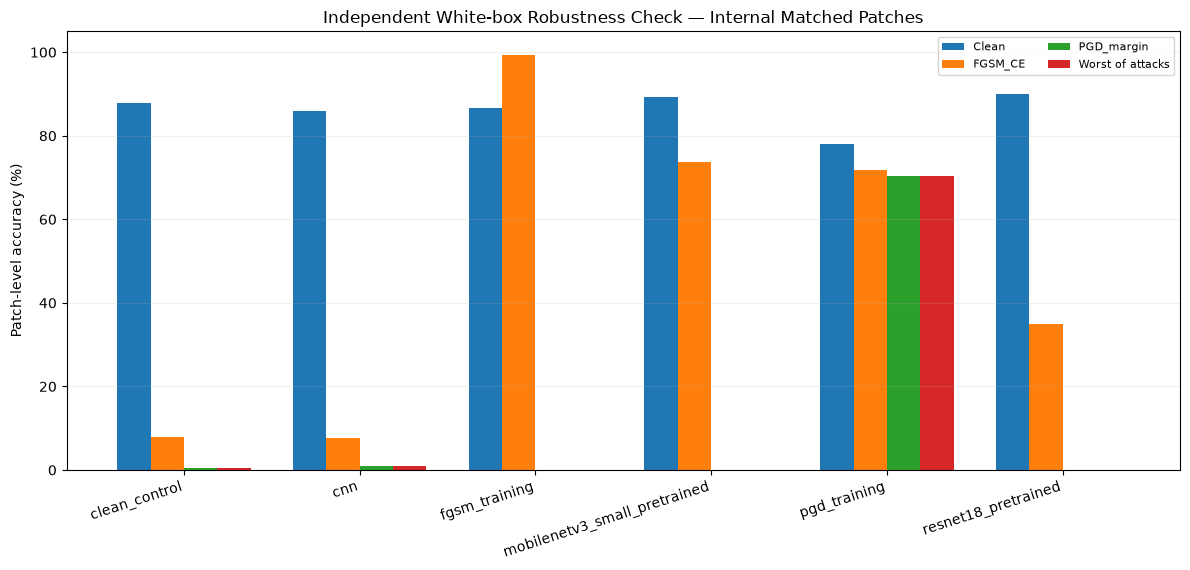

In [58]:
# Visual summary of measured, validation-threshold-frozen independent attacks.
# The figure is recreated from this run's CSV; no test measurements are hard-coded.
if ANALYSIS_ENABLED and RUN_SUBMISSION_VALIDATION and RUN_STAGE in ("all", "analyses"):
    _source = RESULTS_DIR / "SUBMISSION_STRONG_ATTACK_VALIDATION.csv"
    if not _source.is_file():
        raise RuntimeError("Strong attack comparison plot requires measured CSV")
    _tbl = pd.read_csv(_source)
    _keep = ["Clean", "FGSM_CE", "PGD_margin", "Worst_of_Clean_FGSM_PGD_CE_PGD_margin"]
    _pivot = _tbl[_tbl.attack.isin(_keep)].pivot(index="model", columns="attack", values="accuracy")
    if any(name not in _pivot.columns for name in _keep):
        raise RuntimeError("Missing an attack from the independent validation CSV")
    _fig, _ax = plt.subplots(figsize=(12, 5.8))
    _x = np.arange(len(_pivot.index)); _w = 0.19
    for _i, _method in enumerate(_keep):
        _ax.bar(_x + (_i-1.5)*_w, 100*_pivot[_method].to_numpy(), width=_w,
                label=_method.replace("Worst_of_Clean_FGSM_PGD_CE_PGD_margin", "Worst of attacks"))
    _ax.set_ylim(0, 105); _ax.set_ylabel("Patch-level accuracy (%)")
    _ax.set_xticks(_x); _ax.set_xticklabels(list(_pivot.index), rotation=18, ha="right")
    _ax.set_title("Independent White-box Robustness Check — Internal Matched Patches")
    _ax.legend(fontsize=8, ncol=2); _ax.grid(axis="y", alpha=0.2)
    _fig.tight_layout()
    _fig.savefig(RESULTS_DIR/"SUBMISSION_STRONG_ATTACK_COMPARISON.png", dpi=180)
    plt.show(); plt.close(_fig)


In [59]:
# Verify all enabled analyses before recording final execution status.
if RUN_STAGE in ("all","analyses") and ANALYSIS_ENABLED:
    required_v9={"patient_balance":"V9_patient_split_balance_summary.csv"}
    if RUN_SELECTIVE_CLASSWISE:
        required_v9.update({"classwise_selective":"V9_selective_classwise_coverage.csv",
             "selective_cluster_ci":"V9_selective_patient_bootstrap_CI.csv",
             "selective_plot":"V9_selective_positive_detection.png"})
    if RUN_SHIFT_DOSE_RESPONSE:
        required_v9.update({"shift_dose":"V9_shift_dose_response.csv",
            "shift_patch":"V9_shift_dose_patch_predictions.csv",
            "shift_plot":"V9_shift_dose_response.png", "shift_patient_ci":"V9_shift_patient_bootstrap_CI.csv"})
    if RUN_HIGH_CONFIDENCE_FN:required_v9["high_confidence_fn"]="V9_high_confidence_false_negatives.csv"
    if RUN_PGD_CONVERGENCE:
        required_v9["pgd_convergence"]="PGD_CONVERGENCE_STRENGTH.csv"
        required_v9["pgd_convergence_figure"]="PGD_CONVERGENCE_STRENGTH.png"
    if RUN_EFFICIENCY_PARETO:
        required_v9["model_pareto"]="V8_robustness_efficiency_pareto.csv"
        required_v9["pareto_figure"]="V8_robustness_efficiency_pareto.png"
    if RUN_DEEPFOOL:
        required_v9["deepfool_diagnostics"]="V8_deepfool_iteration_boundary_audit.csv"
    missing=[];empty=[]
    for title,fn in required_v9.items():
        p=RESULTS_DIR/fn
        if not p.is_file():missing.append(title)
        elif p.suffix==".csv":
            try:
                if pd.read_csv(p).empty:empty.append(title)
            except Exception:empty.append(title)
    if missing or empty:raise RuntimeError(f"V9 audit failed: missing={missing}; empty/unreadable={empty}")
    previous=json.loads((RESULTS_DIR/"V7_SCIENTIFIC_READINESS.json").read_text(encoding="utf-8"))
    v9_criteria={
       "v7_frozen_threshold_readiness":bool(previous.get("research_ready_for_manual_review")),
       "v9_classwise_abstention_reporting":(not RUN_SELECTIVE_CLASSWISE or "classwise_selective" not in missing),
       "v9_dose_response_reporting":(not RUN_SHIFT_DOSE_RESPONSE or "shift_dose" not in missing),
       "v9_high_confidence_fn_reporting":(not RUN_HIGH_CONFIDENCE_FN or "high_confidence_fn" not in missing),
       "full_mode_not_smoke":MODE=="full",
       "standard_autoattack_not_claimed":True}
    v9_status={"run_stage":RUN_STAGE,"run_profile":RUN_PROFILE,"experiment_id":EXPERIMENT_ID,
       "manifest_id":MANIFEST_ID,"baseline_models":list(model_dict),"v9_files":required_v9,
       "checks":v9_criteria,"all_auto_checks_passed":bool(all(v9_criteria.values())),
       "eligible_for_manual_scientific_review":bool(all(v9_criteria.values())),"clinical_readiness":False,
       "warning":"Manual review of validation decisions, repeated seeds, attack implementations and external validity still required.",
       "standard_autoattack_used":False,"grouped_split_stability_separate_stage":True}
    (RESULTS_DIR/"V9_SCIENTIFIC_READINESS.json").write_text(json.dumps(v9_status,ensure_ascii=False,indent=2),encoding="utf-8")
    marker_path=RESULTS_DIR/"RUN_PROGRESS.json"
    if marker_path.is_file():
        marker=json.loads(marker_path.read_text(encoding="utf-8"))
        marker["v9_status"]="SCIENTIFIC_MANUAL_REVIEW_ELIGIBLE" if v9_status["eligible_for_manual_scientific_review"] else "EXECUTION_ONLY_INCONCLUSIVE"
        marker_path.write_text(json.dumps(marker,ensure_ascii=False,indent=2),encoding="utf-8")
    print("[FINAL VERIFIED] Required analysis files checked. Manual research review eligible:",v9_status["eligible_for_manual_scientific_review"])
elif RUN_STAGE in ("baseline_only","split_stability"):
    print("[V9 STAGE ONLY] Stage finished; no full research completion is claimed.")
else:
    print("[V9] No completed analysis results to verify.")


[FINAL VERIFIED] Required analysis files checked. Manual research review eligible: True


## 20. Evidence-backed portfolio research report

The final report is generated **only from saved measurements in this run**. The report distinguishes smoke tests from full studies, records the threshold policy and sample size, and lists missing or skipped analyses without inventing performance claims. Stage completion is recorded only after the report is verified.

In [60]:
# Generate a publication-ready draft from measured outputs; never fabricate results.
if RUN_STAGE in ("all", "analyses") and ANALYSIS_ENABLED:
    def markdown_table(frame, columns, limit=30):
        table = frame.loc[:, [column for column in columns if column in frame.columns]].head(limit).copy()
        if table.empty:
            return "No measured rows are available."
        table = table.replace({np.nan: "N/A"})
        for column in table.columns:
            if pd.api.types.is_numeric_dtype(table[column]):
                table[column] = table[column].map(lambda v: f"{v:.4f}" if isinstance(v, (float, np.floating)) else str(v))
        return "| " + " | ".join(table.columns) + " |\n| " + " | ".join(["---"] * len(table.columns)) + " |\n" + "\n".join(
            "| " + " | ".join(map(str, row)) + " |" for row in table.itertuples(index=False, name=None))

    def read_result(filename):
        path = RESULTS_DIR / filename
        return pd.read_csv(path) if path.is_file() else pd.DataFrame()

    base = read_result("baseline_model_comparison.csv")
    attacks = read_result("FGSM_PGD_epsilon_sweep.csv")
    thresholds = read_result("validation_threshold_policies.csv")
    ci = read_result("patient_cluster_bootstrap_CI.csv")
    strong = read_result("PGD_CONVERGENCE_STRENGTH.csv")
    defenses = read_result("defense_validation_threshold_classwise.csv")
    calibration = read_result("calibration_before_after_metric_disagreement.csv")
    selectivity = read_result("V9_selective_classwise_coverage.csv")
    pareto = read_result("V8_robustness_efficiency_pareto.csv")
    false_negatives = read_result("V9_high_confidence_false_negatives.csv")
    if base.empty or attacks.empty:
        raise RuntimeError("The portfolio report requires baseline and attack measurements.")
    operational = base[base.threshold_rule == "validation_F1"].copy()
    if not set(BASELINE_MODELS).issubset(set(operational.model)):
        raise RuntimeError("Missing model measurements in the portfolio report.")
    model_order = {name: pos for pos, name in enumerate(BASELINE_MODELS)}
    operational["sort_key"] = operational.model.map(model_order)
    operational = operational.sort_values("sort_key")
    pgd_comparison = strong[strong.threshold_policy == "validation_F1"].copy() if not strong.empty else pd.DataFrame()
    ci_main = ci[ci.threshold_policy == "validation_F1"].copy() if "threshold_policy" in ci else ci
    defense_main = defenses[defenses.threshold_policy == "validation_F1"] if not defenses.empty else pd.DataFrame()
    smoke_label = "SMOKE TEST — NOT FULL RESEARCH EVIDENCE" if MODE == "quick" else "FULL DATA EXPERIMENT — MANUAL REVIEW REQUIRED"
    report = ["# IDC Histopathology: Adversarial Robustness", "",
              f"**Status:** {smoke_label}", "",
              "## Research question", "How do model architecture, adversarial attacks, and defense training affect patch-level IDC-positive detection and reliability?",
              "", "## Reproducibility and sample provenance",
              f"- Experiment: `{EXPERIMENT_ID}`; manifest: `{MANIFEST_ID}`; filename-group-disjoint split: seed `{SPLIT_SEED}`",
              f"- Run profile / stage: `{RUN_PROFILE}` / `{RUN_STAGE}`; device: `{DEVICE}`; input size: `{IMAGE_SIZE}`",
              f"- Models (training and comparison order): {', '.join(BASELINE_MODELS)}",
              f"- Test patches: {len(manifest[manifest.split == 'test'])}; attack patches: {len(attack_subset)}; PGD convergence patches: {len(pgd_conv_subset) if RUN_PGD_CONVERGENCE else 'not run'}",
              "- Thresholds were selected exclusively using validation predictions; reported test metrics are not used to tune thresholds.",
              "", "## Held-out classification metrics — validation F1 threshold",
              markdown_table(operational, ["model", "threshold", "n", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "fn"]),
              "", "## Filename-derived group-cluster bootstrap uncertainty",
              markdown_table(ci_main, ["model", "threshold_policy", "metric", "estimate", "ci_lower", "ci_upper", "patients"]),
              "", "## FGSM / PGD robustness and attack strength",
              f"- Standard sweep epsilons: {list(EPS_GRID)}; PGD steps: {PGD_STEPS}; restarts: {PGD_RESTARTS}.",
              markdown_table(attacks, ["model", "attack", "epsilon", "n", "accuracy", "recall", "success_given_clean_correct"]),
              "", "### Convergence check (frozen validation F1 threshold)",
              markdown_table(pgd_comparison, ["model", "steps", "restarts", "n", "pgd_accuracy", "pgd_recall", "new_fn_n", "recall_change_ci95_low", "recall_change_ci95_high"]),
              "", "## Adversarial fine-tuning (each model uses a validation-only threshold)",
              markdown_table(defense_main, ["model", "attack", "n", "accuracy", "recall", "fn", "clean_correct_positive_n"]),
              "", "## Calibration, abstention, and false-negative reliability",
              "### Calibration before vs. after", markdown_table(calibration, list(calibration.columns)[:9]) if not calibration.empty else "Not evaluated.",
              "", "### Selective prediction / positive-class coverage",
              markdown_table(selectivity[selectivity.policy == "validation_F1"] if not selectivity.empty else selectivity,
                             ["model", "validation_coverage_goal", "test_coverage", "idc_positive_coverage", "positive_detected_overall", "selective_risk"]),
              "", f"- High-confidence false-negative detail rows: {len(false_negatives)} (see saved CSV; the number of rows alone is not an event rate).",
              "", "## Model size, inference latency, and robustness efficiency",
              markdown_table(pareto, list(pareto.columns)[:10]) if not pareto.empty else "Not evaluated.",
              "", "## Interpretation and limitations",
              "- These are 50×50 histopathology image patches resized for the models, **not** whole-slide or patient-level clinical diagnostic outcomes.",
              "- Public source documentation describes tokens such as `10253_idx5` as patient IDs. The model used its numeric case prefix (`10253`) for group separation; no independent biological patient-to-slide registry was available to authenticate group identities.",
              "- Any smoke-test measurements are implementation checks only; do not report them as estimated population performance.",
              "- Attack strengths and norms must be reported: PGD/FGSM use L-infinity bounds, DeepFool is L2-based.",
              "- Attack convergence on a finite subset does not establish certified robustness.",
              "- Synthetic stain/corruption transformations are not validation on independent hospital cohorts.",
              "- The AutoAttack binary custom subset, when run, is not the official standard full suite.",
              "- Filename-derived group-cluster intervals reflect observed case-prefix group dependence only; they do not establish independent biological patient counts or external validity.",
              "- No clinical recommendation or deployment claim is supported by these experiments.",
              "", "## Result artifacts", "Core figures and tables are in the same `results/` folder; review the scientific-readiness and execution-status JSON files before publication.", ""]
    report_path = RESULTS_DIR / "PORTFOLIO_RESEARCH_REPORT.md"
    report_path.write_text("\n".join(report), encoding="utf-8")
    if report_path.stat().st_size < 1000:
        raise RuntimeError("Portfolio report is unexpectedly incomplete.")
    core = pd.read_csv(RESULTS_DIR / "baseline_model_comparison.csv")
    core[core.threshold_rule == "validation_F1"].to_csv(RESULTS_DIR / "PORTFOLIO_CORE_RESULTS.csv", index=False)
    # Read this run's provisional results and publish completion atomically only at the end.
    progress_path = RESULTS_DIR / "RUN_PROGRESS.json"
    marker_path = RESULTS_DIR / "RUN_COMPLETED.json"
    marker = json.loads(progress_path.read_text(encoding="utf-8"))
    marker.update({"status": "VERIFIED_WITH_OPTIONAL_ATTACK_SKIP" if marker.get("autoattack_status") == "SKIPPED_OR_FAILED" else "VERIFIED_RESULTS_GENERATED",
        "run_stage": RUN_STAGE, "run_started_at_unix": RUN_STARTED_AT,
        "verified_at_unix": time.time(), "portfolio_report": str(report_path),
        "pgd_convergence_completed": bool(RUN_PGD_CONVERGENCE and (RESULTS_DIR / "PGD_CONVERGENCE_STRENGTH.csv").is_file())})
    marker_path.write_text(json.dumps(marker, indent=2, default=str), encoding="utf-8")
    write_stage_activity("COMPLETED", details={"portfolio_report": str(report_path), "completion_status": marker["status"]})
    print("[REPORT CREATED]", report_path)
    print("[STAGE VERIFIED]", RESULTS_DIR / f"RUN_ACTIVITY_{RUN_STAGE.upper()}.json")
else:
    print(f"[REPORT NOT APPLICABLE] stage={RUN_STAGE}; the previous full report, if any, was preserved.")

[REPORT CREATED] C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\PORTFOLIO_RESEARCH_REPORT.md
[STAGE VERIFIED] C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\RUN_ACTIVITY_ALL.json


## 21. Academic research audit and manuscript draft

The stage-1 evidence audit checks whether the required **full** evaluation artifacts exist and are internally consistent. It refuses to promote smoke-test values to scientific findings. The resulting draft is suitable for **author review**, not for automatic publication or a clinical-performance claim.

Run `split_stability` before the final `analyses` stage so the audit can see the saved stability results. Inspect `ACADEMIC_STAGE1_AUDIT.json` and complete the manual research checklist before submitting a paper.

In [61]:
if RUN_STAGE in ("all", "analyses") and ANALYSIS_ENABLED:
    # Research-stage evidence audit and manuscript draft. Never substitute smoke measurements for final findings.
    from datetime import datetime, timezone

    _required_models = ["cnn", "resnet18_pretrained", "mobilenetv3_small_pretrained"]
    _expected = {
        "baseline": "baseline_model_comparison.csv",
        "attack": "FGSM_PGD_epsilon_sweep.csv",
        "ci": "patient_cluster_bootstrap_CI.csv",
        "pgd": "PGD_CONVERGENCE_STRENGTH.csv",
        "defense": "defense_validation_threshold_classwise.csv",
        "selective": "V9_selective_classwise_coverage.csv",
        "calibration": "calibration_before_after_metric_disagreement.csv",
        "research_report": "PORTFOLIO_RESEARCH_REPORT.md",
        "readiness": "V9_SCIENTIFIC_READINESS.json",
        "completion": "RUN_COMPLETED.json",
    }

    def _maybe_table(filename):
        path = RESULTS_DIR / filename
        try:
            return pd.read_csv(path) if path.is_file() else pd.DataFrame()
        except Exception:
            return pd.DataFrame()

    def _md_table(frame, cols, limit=12):
        frame = frame.loc[:, [col for col in cols if col in frame.columns]].head(limit)
        if frame.empty:
            return "**Pending full-study results.**"
        data = frame.copy()
        for col in data.columns:
            data[col] = data[col].map(lambda v: "NA" if pd.isna(v) else (f"{v:.4f}" if isinstance(v, (float, np.floating)) else str(v)))
        return "| " + " | ".join(data.columns) + " |\n| " + " | ".join("---" for _ in data.columns) + " |\n" + "\n".join("| " + " | ".join(map(str, row)) + " |" for row in data.itertuples(index=False, name=None))

    _report_base = _maybe_table(_expected["baseline"])
    _report_ci = _maybe_table(_expected["ci"])
    _report_pgd = _maybe_table(_expected["pgd"])
    _report_def = _maybe_table(_expected["defense"])
    _report_attack = _maybe_table(_expected["attack"])
    _report_paired = _maybe_table("paired_patient_CI_attack_minus_clean.csv")
    _primary_valid = (not _report_paired.empty and
        {"model", "attack_result", "threshold_policy", "metric", "attack_minus_clean", "lower_95", "upper_95"}.issubset(_report_paired.columns))
    _primary_rows = (_report_paired.loc[(_report_paired.threshold_policy == "validation_F1") &
        (_report_paired.metric == "recall") &
        (_report_paired.apply(lambda r: str(r.attack_result) == f"{r.model}_PGD_8_255", axis=1))].copy()
        if _primary_valid else pd.DataFrame())
    _report_sel = _maybe_table(_expected["selective"])
    _report_cal = _maybe_table(_expected["calibration"])
    _test = manifest.loc[manifest.split == "test"] if "manifest" in globals() else pd.DataFrame()

    # This is a *technical evidence gate*, not a guarantee of publication/clinical suitability.
    _audit_checks = {
        "full_all_research_profile": RUN_PROFILE == "all_research" and MODE == "full",
        "full_analysis_stage": RUN_STAGE in ("all", "analyses") and bool(ANALYSIS_ENABLED),
        "three_expected_architectures": set(_required_models).issubset(set(BASELINE_MODELS)),
        "three_measured_architectures": bool(not _report_base.empty and {"model", "threshold_rule"}.issubset(_report_base.columns) and
                                          set(_required_models).issubset(set(_report_base.loc[_report_base.threshold_rule == "validation_F1", "model"]))),
        "sufficient_filename_case_groups_for_descriptive_CI": bool(not _test.empty and _test.patient_id.nunique() >= 20),
        "at_least_20_IDC_positive_test_patches": bool(not _test.empty and int((_test.label == 1).sum()) >= 20),
        "full_fgsm_pgd_coverage": bool("attack_subset" in globals() and "full_test" in globals() and len(attack_subset) == len(full_test)),
        "cluster_bootstrap_and_primary_policy": bool(not _report_ci.empty and "threshold_policy" in _report_ci and
              (_report_ci.threshold_policy == "validation_F1").any()),
        "primary_paired_PGD8_recall_CIs_all_models": bool(not _primary_rows.empty and
              set(_required_models).issubset(set(_primary_rows.model)) and
              np.isfinite(pd.to_numeric(_primary_rows.lower_95, errors="coerce")).all() and
              np.isfinite(pd.to_numeric(_primary_rows.upper_95, errors="coerce")).all()),
        "PGD8_whitebox_attack_all_models": bool(not _report_attack.empty and
              {"model", "attack", "epsilon", "steps", "restarts"}.issubset(_report_attack.columns) and
              set(_required_models).issubset(set(_report_attack.loc[(_report_attack.attack == "PGD") &
               (np.isclose(_report_attack.epsilon.astype(float), 8/255)) &
               (_report_attack.steps.astype(float) >= 20) & (_report_attack.restarts.astype(float) >= 2), "model"]))),
        "pgd_strength_validation_frozen": bool(not _report_pgd.empty and "threshold_policy" in _report_pgd and
              (_report_pgd.threshold_policy == "validation_F1").any()),
        "defense_metrics_saved": bool(not _report_def.empty),
        "calibration_and_selective_results_saved": bool(not _report_cal.empty and not _report_sel.empty),
        "previous_pipeline_verification": (RESULTS_DIR / _expected["completion"]).is_file(),
        "separate_split_stability_executed": (RESULTS_DIR / "RUN_ACTIVITY_SPLIT_STABILITY.json").is_file(),
        "all_three_architectures_alternative_group_splits": bool(
            (RESULTS_DIR / "V9_grouped_split_retraining_results.csv").is_file()
            and set(_required_models).issubset(set(_maybe_table("V9_grouped_split_retraining_results.csv").get("model", [])))
            and all(_maybe_table("V9_grouped_split_retraining_results.csv").groupby("model").split_seed.nunique().reindex(_required_models,fill_value=0)>=2)),
        "independent_attack_diagnostics_present":bool(
            (RESULTS_DIR / "SUBMISSION_ATTACK_DIAGNOSTICS.json").is_file()
            and json.loads((RESULTS_DIR / "SUBMISSION_ATTACK_DIAGNOSTICS.json").read_text(encoding="utf-8")).get("gradient_nonzero_all_batches",False)
            and json.loads((RESULTS_DIR / "SUBMISSION_ATTACK_DIAGNOSTICS.json").read_text(encoding="utf-8")).get("all_worst_of_consistency_passed",False)
            and json.loads((RESULTS_DIR / "SUBMISSION_ATTACK_DIAGNOSTICS.json").read_text(encoding="utf-8")).get("revision")==SUBMISSION_REVIEW_REVISION
            and int(json.loads((RESULTS_DIR / "SUBMISSION_ATTACK_DIAGNOSTICS.json").read_text(encoding="utf-8")).get("n_matched_test_patches",0))>=SUBMISSION_VALIDATION_N),
        "expanded_binary_autoattack_min256":bool(AUTOATTACK_FULL_SAMPLE_LIMIT>=256),
        "matched_strong_attack_subset_group_bootstrap": bool(
            not _maybe_table("SUBMISSION_STRONG_ATTACK_GROUP_CLUSTER_CI.csv").empty
            and set(_required_models).issubset(set(_maybe_table("SUBMISSION_STRONG_ATTACK_GROUP_CLUSTER_CI.csv").get("model", [])))),
    }
    # AutoAttack is optional for methodology, but required for this requested complete suite.
    _aa_optional_status = _maybe_table("optional_attack_execution_status.csv")
    _aa_metrics = _maybe_table("autoattack_optional.csv")
    _aa_status_rows = (_aa_optional_status.loc[_aa_optional_status.analysis == "AutoAttack_binary_custom"]
        if not _aa_optional_status.empty and "analysis" in _aa_optional_status else pd.DataFrame())
    _aa_valid = (_aa_metrics.loc[_aa_metrics.status == "COMPLETED"]
        if not _aa_metrics.empty and "status" in _aa_metrics else pd.DataFrame())
    _aa_complete_models = set(_aa_status_rows.loc[_aa_status_rows.status == "COMPLETED", "model"]) if not _aa_status_rows.empty else set()
    _aa_valid_models = set(_aa_valid.model) if not _aa_valid.empty and "model" in _aa_valid else set()
    _aa_eps_ok = (not _aa_valid.empty and "max_linf" in _aa_valid and
        pd.to_numeric(_aa_valid.max_linf, errors="coerce").notna().all() and
        (pd.to_numeric(_aa_valid.max_linf, errors="coerce") <= DEFENSE_EPS + 1e-5).all())
    _aa_n_ok = (not _aa_valid.empty and "n" in _aa_valid and
        (pd.to_numeric(_aa_valid.n, errors="coerce") >= min(AUTOATTACK_FULL_SAMPLE_LIMIT, len(_test))).all())
    _audit_checks["custom_autoattack_executed_for_all_primary_models"] = bool(
        set(_required_models).issubset(_aa_complete_models.intersection(_aa_valid_models)) and _aa_eps_ok and _aa_n_ok)
    # Existing source files may have been inspected during exploratory work: this audit cannot make the test set blinded.
    _autoattack_state = OPTIONAL_ATTACK_IMPORTS.get("autoattack", {"available": False})
    _research_audit = {
        "status": "FULL_TECHNICAL_EVIDENCE_PRESENT_MANUAL_REVIEW_REQUIRED" if all(_audit_checks.values()) else "NOT_READY_FOR_SCIENTIFIC_SUBMISSION",
        "study_protocol_id": STUDY_PROTOCOL_ID,
        "run_profile": RUN_PROFILE,
        "run_stage": RUN_STAGE,
        "checked_at_utc": datetime.now(timezone.utc).isoformat(),
        "criteria": _audit_checks,
        "optional_autoattack_importable": bool(_autoattack_state.get("available")),
        "source_group_identity_status":json.loads((RESULTS_DIR / "SUBMISSION_DATA_LINEAGE.json").read_text(encoding="utf-8")).get("status")
            if (RESULTS_DIR / "SUBMISSION_DATA_LINEAGE.json").is_file() else "NOT_CHECKED",
        "gradient_masking_review_flags":json.loads((RESULTS_DIR / "SUBMISSION_ATTACK_DIAGNOSTICS.json").read_text(encoding="utf-8")).get("gradient_masking_and_label_leaking_flags", [])
            if (RESULTS_DIR / "SUBMISSION_ATTACK_DIAGNOSTICS.json").is_file() else [],
        "submission_authorization":"NOT_AUTOMATIC; SOURCE, SCIENTIFIC, ETHICS, AND MANUSCRIPT REVIEW REQUIRED",
        "non_automatable_requirements": [
            "verify data provenance, filename group identifiers, and image-level labels",
            "document prior exploratory use of held-out data and lock analysis decisions",
            "check reference standard / annotation procedure against source publications",
            "review training loss, hyperparameters, and complete attack configuration",
            "check ethics, data rights, author contributions, references and journal guidelines",
            "external and clinical validation are absent"
        ],
        "scope": "patch-level internal methodology only; not clinical deployment",
    }
    (RESULTS_DIR / "ACADEMIC_STAGE1_AUDIT.json").write_text(json.dumps(_research_audit, indent=2, ensure_ascii=False), encoding="utf-8")
    _to_do = [name for name, passed in _audit_checks.items() if not bool(passed)]
    _gate_lines = ["# Stage-1 Academic Evidence Readiness", "",
                   f"**Automatic evidence status:** {_research_audit['status']}", "",
                   "This is a technical evidence check, not publication approval or clinical validation.", "",
                   "## Technical evidence criteria", ""]
    _gate_lines.extend(f"- [{'x' if bool(value) else ' '}] {name}" for name, value in _audit_checks.items())
    _gate_lines.extend(["", "## Required manual verification", ""])
    _gate_lines.extend(f"- [ ] {item}" for item in _research_audit["non_automatable_requirements"])
    if _to_do:
        _gate_lines.extend(["", "## Next actions", "", "Finish these technical checks before claiming the full study is complete:", ""])
        _gate_lines.extend(f"- {item}" for item in _to_do)
    else:
        _gate_lines.extend(["", "**All automatic technical checks passed.** Complete the manual checks and author review before submission."])
    (RESULTS_DIR / "STAGE1_SUBMISSION_READINESS.md").write_text("\n".join(_gate_lines) + "\n", encoding="utf-8")

    _full_evidence = all(_audit_checks.values())
    _status = "Full internal experiments and supplementary strong-attack validation completed; independent source-identity, ethics, and scientific author review still required" if _full_evidence else "METHODS DRAFT — FULL STUDY EVIDENCE INCOMPLETE"
    _article = [
        "# Adversarial Robustness and Reliability of Deep Learning Models for IDC Histopathology Patch Classification",
        "", f"**Manuscript status:** {_status}", "",
        "## Abstract", "",
        "**Background:** Robustness and false-negative errors in histopathology patch classification require transparent evaluation.",
        "**Methods:** Retrospective patch-level comparison of custom CNN, pretrained ResNet-18, and pretrained MobileNetV3-Small using filename-group-disjoint internal splits. Classification thresholds are set using validation predictions only. Adversarial perturbations (FGSM and PGD), fine-tuning, calibration, selective prediction, and patient-group cluster bootstrap are assessed.",
        "**Results:** " + ("See the measured tables below; all findings require independent author review." if _full_evidence else "Pending full-model training and locked internal evaluation. No numeric results are claimed."),
        "**Conclusions:** Interpretation is deferred until the full evidence and reporting checklist are reviewed.", "",
        "## Introduction", "", "The target is IDC presence within 50×50 breast histopathology patches. Patch labels do not establish patient-level cancer diagnosis. Adversarial and image-quality shifts motivate sensitivity, false-negative, and uncertainty analyses.", "",
        "## Materials and methods", "",
        "### Study design and dataset", "Retrospective secondary analysis of the public Breast Histopathology Images collection, attributed to Janowczyk and Madabhushi (2016; doi:10.4103/2153-3539.186902). The source describes 277,524 50×50 patches derived from 162 whole-mount slides, and describes the filename token `10253_idx5` as a patient identifier. Our training split uses the coarser numeric prefix `10253` for disjoint grouping. The number of numeric case groups must NOT be equated to independently authenticated biological patients or to the 162 slides; original patient/slide registry reconciliation is unavailable. Duplicate patch keys were byte-checked before splitting.",
        f"The declared full-study split seed is 20261101 (current split: {SPLIT_SEED}); this does not make the data externally independent. Previously inspected smoke results are exploratory and must be disclosed.", "",
        "### Modeling", "Primary architectures: custom CNN, ImageNet-pretrained ResNet-18, ImageNet-pretrained MobileNetV3-Small. The pipeline resizes patches to the configured input size, uses class-balanced sampling and training-only augmentation, and selects checkpoints on validation results. Detailed training hyperparameters and package versions must be copied from experiment_settings.json and saved training history before submission.", "",
        "### Outcomes and statistical analysis", "Primary endpoint: attacked minus clean IDC-positive recall under white-box PGD (L∞, ε = 8/255) at a validation-F1-selected threshold. The same held-out patches are evaluated before and after attack. Report 95% group-cluster bootstrap CIs. Secondary endpoints include false-negative rate, accuracy, specificity, AUPRC/AUROC, calibration, abstention, cross-model transferability, PGD strength, and model efficiency. These secondary analyses are exploratory unless separately predeclared.", "",
        "### Threat model", f"Input-space L∞ FGSM/PGD, ε ∈ {EPS_GRID}; PGD default {PGD_STEPS} steps/{PGD_RESTARTS} restarts. Convergence grid: {PGD_CONVERGENCE_STEPS}. Report source/target model, perturbation norm, clipping range, and whether attacks were run on an identical evaluation cohort.", "",
        "## Results", "",
    ]
    if _full_evidence:
        op = _report_base.loc[_report_base.threshold_rule == "validation_F1"]
        _article.extend(["### Primary endpoint: paired change in IDC-positive recall under PGD 8/255",
                         _md_table(_primary_rows, ["model", "attack_result", "attack_minus_clean", "lower_95", "upper_95", "n_patches", "n_patients"]), "",
                         "### Internal-test performance", _md_table(op, ["model", "n", "accuracy", "recall", "specificity", "f1", "roc_auc", "pr_auc", "fn"]), "",
                         "### Filename-derived group-cluster bootstrap uncertainty (NOT authenticated biological patient-level CI)", _md_table(_report_ci.loc[_report_ci.threshold_policy == "validation_F1"], ["model", "metric", "estimate", "ci_lower", "ci_upper", "patients"]), "",
                         "### PGD convergence", _md_table(_report_pgd.loc[_report_pgd.threshold_policy == "validation_F1"], ["model", "steps", "n", "pgd_accuracy", "pgd_recall", "new_fn_n"]), "",
                         "### Adversarial training", _md_table(_report_def, ["model", "attack", "n", "accuracy", "recall", "fn"]), "",
                         "### Independent threshold-aware strong-attack validation (supplement; matched subset)",
                         _md_table(_maybe_table("SUBMISSION_STRONG_ATTACK_VALIDATION.csv"),
                             ["model", "attack", "n", "accuracy", "positive_recall", "attack_success_among_clean_correct", "new_false_negative_n"],limit=36), "",
                         "### Paired filename-derived case-group bootstrap on strong-attack validation subset",
                         _md_table(_maybe_table("SUBMISSION_STRONG_ATTACK_GROUP_CLUSTER_CI.csv"),
                             ["model","attack","metric","point_estimate","ci_lower_95","ci_upper_95","n_filename_groups"],limit=30), "",
                         "### Independent group-split replication (exploratory; separate test cohorts)",
                         _md_table(_maybe_table("V9_grouped_split_retraining_results.csv"),
                             ["split_seed", "model", "n", "accuracy", "recall", "roc_auc"],limit=12), ""])
    else:
        _article.extend(["**No result estimates are inserted.** Execute all full research stages and complete manual checks before drafting the Results section.", ""])
    _article.extend([
        "## Discussion", "", "Interpret clinically relevant failure modes only as exploratory patch-level observations. A failed attack may reflect attack implementation limits rather than actual robustness. Calibration and abstention do not independently establish safe use. Statistical uncertainty is conditional on the observed source and group definitions.", "",
        "## Limitations", "", "Single public collection; 50×50 source patches; source reports 162 original slides but available files contain a different number of case prefixes; no independent patient/slide case registry; no external institution or prospective validation; reuse of held-out test results during exploratory iteration; synthetic rather than observed cross-site stain shifts; FGSM-only defense shows a strong FGSM-versus-PGD discrepancy consistent with possible label leaking/gradient masking; limited split seeds and attack-subset sizes; binary custom AutoAttack (APGD-CE + Square only, NOT official standard AutoAttack). All patch-level outcomes are non-clinical.", "",
        "## Ethics, availability and declarations", "", "Ethics/IRB status: **requires institutional determination**; the use of public data does not by itself establish exemption. Data: Kaggle Breast Histopathology Images (original authors credited in references). Code release and data redistribution must follow applicable licenses and provenance requirements. Funding, conflicts of interest, authorship, and computational resources: **author to complete**.", "",
        "## Submission integrity disclosure", "", "Earlier internal-test summaries were inspected during iterative notebook development. These results must be described as exploratory/retrospective, not preregistered confirmation. Sampled independent attacks do not independently validate another dataset. A formal independent reviewer must examine source lineage, data rights, reporting checklist and statistical interpretation before submission.", "",
        "## References (verify journal citation style)", "",
        "1. Janowczyk A, Madabhushi A. Deep learning for digital pathology image analysis: A comprehensive tutorial with selected use cases. J Pathol Inform. 2016;7:29. doi:10.4103/2153-3539.186902. Dataset: https://andrewjanowczyk.com/use-case-6-invasive-ductal-carcinoma-idc-segmentation/",
        "2. Dataset mirror: Breast Histopathology Images, Kaggle. https://www.kaggle.com/datasets/paultimothymooney/breast-histopathology-images", "3. Tejani AS et al. Checklist for Artificial Intelligence in Medical Imaging (CLAIM): 2024 Update. https://doi.org/10.1148/ryai.240300",
        "4. Sounderajah V et al. The STARD-AI reporting guideline. Nature Medicine (2025). https://www.nature.com/articles/s41591-025-03953-8",
        "5. Croce F, Hein M. Reliable evaluation of adversarial robustness with an ensemble of diverse parameter-free attacks. ICML (2020). https://proceedings.mlr.press/v119/croce20b.html",
        "6. Athalye A, Carlini N, Wagner D. Obfuscated Gradients Give a False Sense of Security. ICML (2018). https://proceedings.mlr.press/v80/athalye18a.html",
        "", "**DRAFT ONLY: Public filename schema and within-dataset group split checks do not authenticate biological patient identity, patient counts, or the source slide registry. Independent scientific and ethical review remain required before submission; this work has no clinical-use claim.**", ""
    ])
    _manuscript_path = RESULTS_DIR / "ACADEMIC_MANUSCRIPT_DRAFT.md"
    _manuscript_path.write_text("\n".join(_article), encoding="utf-8")
    print("Academic evidence gate:", _research_audit["status"])
    print("Draft:", _manuscript_path)
    print("Audit:", RESULTS_DIR / "ACADEMIC_STAGE1_AUDIT.json")

else:
    print("[ACADEMIC AUDIT UNCHANGED] This stage does not publish results or replace the existing draft.")


Academic evidence gate: FULL_TECHNICAL_EVIDENCE_PRESENT_MANUAL_REVIEW_REQUIRED
Draft: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\ACADEMIC_MANUSCRIPT_DRAFT.md
Audit: C:\Users\htpar\Downloads\idc_robustness_final_outputs\all_research\experiments\eaebd064f2a8\results\ACADEMIC_STAGE1_AUDIT.json


### Completion check

Read the generated `ACADEMIC_STAGE1_AUDIT.json` and `STAGE1_SUBMISSION_READINESS.md`; the run is not considered submission-ready if a required experiment is absent.

In [62]:
# Report explicit technical evidence status; no override or fabricated completion flag.
if RUN_PROFILE == "all_research" and RUN_STAGE == "all":
    audit_path = RESULTS_DIR / "ACADEMIC_STAGE1_AUDIT.json"
    split_path = RESULTS_DIR / "RUN_ACTIVITY_SPLIT_STABILITY.json"
    print("Stage 2 split stability:", "SAVED" if split_path.is_file() else "MISSING")
    if audit_path.is_file():
        audit = json.loads(audit_path.read_text(encoding="utf-8"))
        print("Stage 3 academic evidence:", audit.get("status", "UNKNOWN"))
        for label, passed in audit.get("criteria", {}).items():
            if not passed:
                print("  INCOMPLETE:", label)
    else:
        print("Stage 3 academic evidence: NOT GENERATED")
print("SUBMISSION STATE: not authorized by automated checks; complete the independent source/provenance, ethics and scientific review checklist.")


Stage 2 split stability: SAVED
Stage 3 academic evidence: FULL_TECHNICAL_EVIDENCE_PRESENT_MANUAL_REVIEW_REQUIRED
SUBMISSION STATE: not authorized by automated checks; complete the independent source/provenance, ethics and scientific review checklist.
